## Gaussian Processes Pipeline Without Dimensionality Reduction
This notebook produces Gaussian Process (GP) emulators without the use of Dimensionality Reduction techniques. Methods like PCA are very popular in hyperspectral regression mainly because they
allow to substantially reduce the computational burden of algorithms. However, they also introduce challenges related to interpretability and performance. Regarding the latter, dimensionality reduction introduces reconstruction errors, even when the majority of the variance in the data is explained.

Firstly, a GP is fitted to the selected training split for each band in the samples, resulting in 4,205 fitted GPs. This results in 4,205 learned length scale hyperparameters. Then, the K-means
clustering algorithm is applied to group these length scales. The idea behind this approach is rooted in the fact that the length scale hyperparameter is usually the most important parameter of a fitted kernel, meaning that if two bands were handled by the same length scale, they could be grouped together in the same cluster to improve inference time. Another important aspect is that, usually, adjacent wavelengths are correlated and therefore tend to be handled by a similar length scale value. The application of this clustering results in a number of 𝐾 clusters or "spectral windows". Finally, the median length scale of each window is used to perform inference on the selected testing split. This allows to reduce the number of GPs to perform inference with from 4,205 × 6 to 𝐾 × 6. The main advantage is reducing the number of required Cholesky factorizations, which is usually the main bottleneck in terms of inference time. It is worth noting that this method still requires the fitting of one GP for each wavelength, which means that the computational optimization occurs only during testing time and not during training.

#### Imports

In [1]:
from pathlib import Path
import os
import sys

_cwd = Path.cwd()
_project_candidates = [_cwd, *_cwd.parents]
_project_candidates.extend(parent / "Masters_Thesis" for parent in tuple(_project_candidates))
_PROJECT_ROOT = next(
    (candidate for candidate in _project_candidates if (candidate / "src" / "globals.py").is_file()),
    None,
)
if _PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate Masters_Thesis/src/globals.py from the current working directory.")
_SRC_DIR = str(_PROJECT_ROOT / "src")
if _SRC_DIR not in sys.path:
    sys.path.insert(0, _SRC_DIR)
os.chdir(_PROJECT_ROOT / "thesis_results")

import importlib
import pandas as pd
import numpy as np
import random
import copy
import pickle
import time

import matplotlib.pyplot as plt

from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
from sklearn.gaussian_process import GaussianProcessRegressor
import warnings
from sklearn.exceptions import ConvergenceWarning
from scipy.linalg import cho_factor, cho_solve

import globals
import utils

np.set_printoptions(precision=4, suppress=True, linewidth=np.inf, threshold=np.inf)

pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)

seed = 42
random.seed(seed)
np.random.seed(seed)

In [2]:
importlib.reload(globals)
importlib.reload(utils)

<module 'utils' from 'c:\\Users\\Matteo\\Desktop\\Scuola\\MastersThesis\\Masters_Thesis\\utils.py'>

In [4]:
X, Y, wavelengths = utils.load_train_h5(globals.CURRENT_TRAIN_FILE)
wavelengths = wavelengths.squeeze()
Y_resh = Y.reshape(-1, Y.shape[1] // len(wavelengths), len(wavelengths))

X_tr, X_val, X_test, Y_tr, Y_val, Y_test = utils.train_val_test_split(X, Y_resh, wavelengths, verbose=True)

X shape: (10000, 9)
Y shape: (10000, 6, 4205)
wavelengths shape: (4205,)

X_tr shape: (8000, 9)
X_val shape: (1000, 9)
X_test shape: (1000, 9)

Y_tr shape: (8000, 6, 4205)
Y_val shape: (1000, 6, 4205)
Y_test shape: (1000, 6, 4205)


#### Gaussian Processes on each band

In [5]:
scale_type = "minmax"
kern = (
    C(1.0, (1e-3, 1e3))
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-3, 1e3),
        nu=2.5
    )
    + WhiteKernel(1e-2, (1e-5, 1e1))
)
x_scaler, X_tr_scaled, X_test_scaled = utils.scale_input_data(X_tr, X_test, scale_type=scale_type)
y_scalers, Y_tr_scaled, Y_test_scaled = utils.scale_output_data(Y_tr, Y_test, scale_type=scale_type)

---------- Scaling input data using minmax scaling... ----------
---------- Input data scaling completed. ----------

---------- Scaling output data using minmax scaling... ----------
---------- Output data scaling completed. ----------



In [ ]:
n_functions = Y_tr_scaled.shape[1]
n_wavelengths = Y_tr_scaled.shape[2]

gpr_list = [[None for _ in range(n_wavelengths)] for _ in range(n_functions)]

for f in range(n_functions):
    for w in range(n_wavelengths):
        y = Y_tr_scaled[:, f, w] # shape (n_samples,)

        gpr = GaussianProcessRegressor(kernel=copy.deepcopy(kern), n_restarts_optimizer=0, random_state=42)
        
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            gpr.fit(X_tr_scaled, y)

        print(f"Function {f}, wavelength {w}: {gpr.kernel_}")

        gpr_list[f][w] = gpr
    print(f"Function {f+1} done.")

with open(globals.gp_output_path("gp_saves/model_saves/gpr_list_nodimred.pkl"), "wb") as f:
    pickle.dump(gpr_list, f)

Time taken for fitting Matérn kernel on 400-sample training dataset: 158 minutes and 50 seconds. Kernel with:
<ul>
    <li>C(1.0, (1e-3, 1e3))</li>
    <li>Matern(length_scale=1.0, length_scale_bounds=(1e-3, 1e3), nu=2.5)</li>
    <li>WhiteKernel(1e-2, (1e-5, 1e1))</li>
</ul>

In [6]:
with open(globals.gp_input_path("gp_saves/model_saves/gpr_list_nodimred.pkl"), "rb") as f:
    gpr_list = pickle.load(f)

In [7]:
length_scales = np.full((globals.N_FUNCTIONS, len(wavelengths)), np.nan)

for f in range(globals.N_FUNCTIONS):
    for w in range(len(wavelengths)):
        gpr = gpr_list[f][w]
        if gpr is None:
            continue
        k = gpr.kernel_
        # kernel structure: C * Matern + WhiteKernel
        # k.k1 = C * Matern, k.k2 = WhiteKernel
        matern = k.k1.k2
        length_scales[f, w] = matern.length_scale

print(length_scales.shape)

(6, 4205)


In [29]:
from sklearn.cluster import KMeans

def find_k_clusters(values, k=10, random_state=42):
    """
    Cluster `values` (1D array, length scales across wavelengths) into
    exactly k groups by value similarity (1D k-means on the length scale
    itself, not on wavelength position). Clusters are NOT required to be
    contiguous — wavelengths with similar length scales anywhere in the
    spectrum can land in the same group.

    Returns a dict: {cluster_id: np.array of wavelength indices in that cluster}
    
    Args:
        values: One-dimensional length-scale values to cluster.
        k: Requested number of clusters.
        random_state: Seed passed to the clustering routine.

    Returns:
        Cluster labels and cluster centers.
"""
    n = len(values)
    if k > n:
        raise ValueError(f"Cannot form {k} clusters from only {n} points.")

    X = values.reshape(-1, 1)
    km = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    labels = km.fit_predict(X)

    clusters = {}
    for c in range(k):
        idx = np.where(labels == c)[0]
        # sort by cluster center so cluster 0 = smallest length scale, etc.
        clusters[c] = idx

    # relabel clusters in ascending order of their center, for readability
    centers = km.cluster_centers_.ravel()
    order = np.argsort(centers)
    clusters_sorted = {new_id: clusters[old_id] for new_id, old_id in enumerate(order)}

    return clusters_sorted


K_CLUSTERS = 10
for k in range(K_CLUSTERS):
    windows_per_function = {}
    for f, func_name in zip(range(globals.N_FUNCTIONS), globals.function_names_plots):
        ls = length_scales[f]
        clusters = find_k_clusters(ls, k=k+1)
        windows_per_function[f] = clusters
        print(f"{func_name}: {len(clusters)} clusters")
        # for c, idx in clusters.items():
        #     print(f"   cluster {c}: {len(idx)} wavelengths, "
        #           f"length_scale range [{ls[idx].min():.3f}, {ls[idx].max():.3f}], "
        #           f"median={np.median(ls[idx]):.3f}")

    with open(globals.gp_output_path(f"gp_saves/nodimred_resources/gpr_list_nodimred_windows_{k+1}.pkl"), "wb") as f:
        pickle.dump(windows_per_function, f)

Path Radiance: 1 clusters
Direct Solar Irradiance: 1 clusters
Diffuse Solar Irradiance: 1 clusters
Spherical Albedo: 1 clusters
Direct Transmittance: 1 clusters
Diffuse Transmittance: 1 clusters
Path Radiance: 2 clusters
Direct Solar Irradiance: 2 clusters
Diffuse Solar Irradiance: 2 clusters
Spherical Albedo: 2 clusters
Direct Transmittance: 2 clusters
Diffuse Transmittance: 2 clusters
Path Radiance: 3 clusters
Direct Solar Irradiance: 3 clusters
Diffuse Solar Irradiance: 3 clusters
Spherical Albedo: 3 clusters
Direct Transmittance: 3 clusters
Diffuse Transmittance: 3 clusters
Path Radiance: 4 clusters
Direct Solar Irradiance: 4 clusters
Diffuse Solar Irradiance: 4 clusters
Spherical Albedo: 4 clusters
Direct Transmittance: 4 clusters
Diffuse Transmittance: 4 clusters
Path Radiance: 5 clusters
Direct Solar Irradiance: 5 clusters
Diffuse Solar Irradiance: 5 clusters
Spherical Albedo: 5 clusters
Direct Transmittance: 5 clusters
Diffuse Transmittance: 5 clusters
Path Radiance: 6 clusters

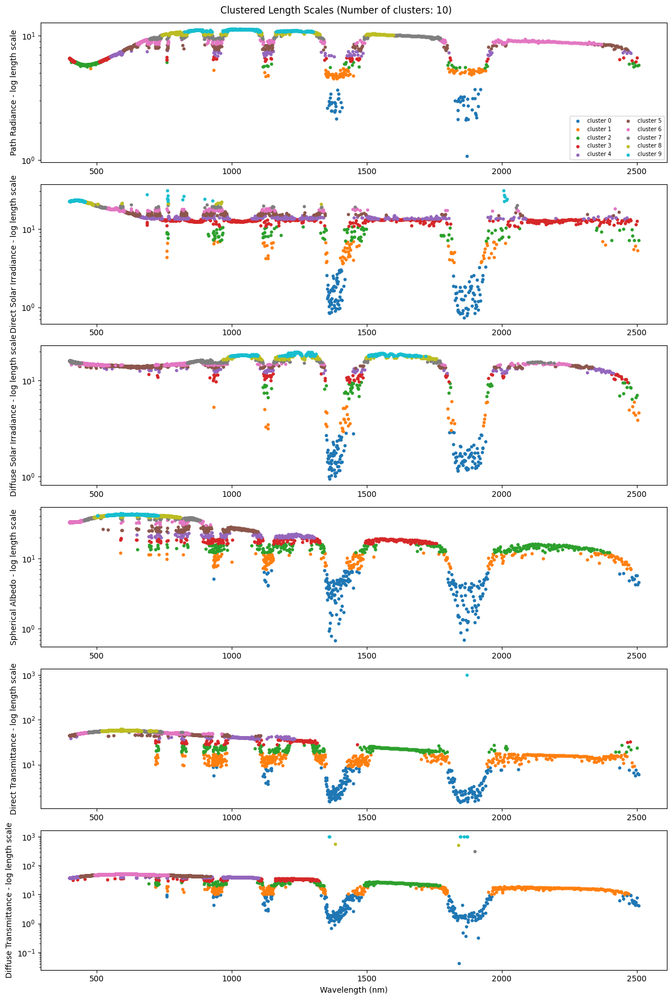

In [52]:
def plot_length_scale_clusters(wavelengths, l_scales, clusters_per_function, n_clusters):
    """Plot wavelength-dependent length scales and their cluster assignments.

        Args:
        wavelengths: Wavelength coordinates for the length-scale values.
        l_scales: Length-scale values grouped by transfer function.
        clusters_per_function: Cluster labels for each transfer function.
        n_clusters: Number of clusters represented in the plot.

        Returns:
            None. Displays the length-scale cluster plots.
        """
    fig, axes = plt.subplots(globals.N_FUNCTIONS, 1, figsize=(12, 3*globals.N_FUNCTIONS), sharex=True)
    if globals.N_FUNCTIONS == 1:
        axes = [axes]

    cmap = plt.get_cmap("tab10")

    plt.suptitle(f"Clustered Length Scales (Number of clusters: {n_clusters})")
    for f, func_name in zip(range(globals.N_FUNCTIONS), globals.function_names_plots):
        ax = axes[f]
        clusters = clusters_per_function[f]

        for c, idx in clusters.items():
            ax.scatter(wavelengths[idx], l_scales[f][idx],
                       s=10, color=cmap(c % 10), label=f"cluster {c}")

        ax.set_ylabel(f"{func_name} - log length scale")
        ax.set_yscale('log')
        ax.tick_params(axis='x', labelbottom=True)

    axes[-1].set_xlabel("Wavelength (nm)")
    axes[0].legend(loc="lower right", fontsize=7, ncol=2)
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()

n_clusters = 10
with open(globals.gp_input_path(f"gp_saves/nodimred_resources/gpr_list_nodimred_windows_{n_clusters}.pkl"), "rb") as f:
    windows_per_function = pickle.load(f)

plot_length_scale_clusters(wavelengths, length_scales, windows_per_function, n_clusters)

In [10]:
for f, func_name in zip(range(globals.N_FUNCTIONS), globals.function_names_plots):
    print(f"Statistics for {func_name}:")
    print(f"\tMinimum learned length scale: {np.min(length_scales[f])}")
    print(f"\tMaximum learned length scale: {np.max(length_scales[f])}")
    print(f"\tMedian learned length scale: {np.median(length_scales[f])}")
    print(f"\tMean learned length scale: {np.mean(length_scales[f])}")
    print(f"\tStandard deviation of learned length scale: {np.std(length_scales[f])}")
    print()

Statistics for Path Radiance:
	Minimum learned length scale: 1.0793470385792883
	Maximum learned length scale: 11.303871548029408
	Median learned length scale: 8.010806894533486
	Mean learned length scale: 8.061638885976723
	Standard deviation of learned length scale: 2.019407140373007

Statistics for Direct Solar Irradiance:
	Minimum learned length scale: 0.7438073796401304
	Maximum learned length scale: 30.754830078358783
	Median learned length scale: 15.683634977651705
	Mean learned length scale: 16.086670502071506
	Standard deviation of learned length scale: 4.835911392586798

Statistics for Diffuse Solar Irradiance:
	Minimum learned length scale: 0.9426037135356741
	Maximum learned length scale: 19.713563209041865
	Median learned length scale: 14.671879497558619
	Mean learned length scale: 14.464841593146973
	Standard deviation of learned length scale: 3.032356520766954

Statistics for Spherical Albedo:
	Minimum learned length scale: 0.6818297851803757
	Maximum learned length scal

In [38]:
# inspect direct transmittance
idx_target = np.argmax(length_scales[4])
print(idx_target, length_scales[4][idx_target], wavelengths[idx_target])

for c, idx in windows_per_function[4].items():
    if idx_target in idx:
        print("Found in cluster:", c)
        break
else:
    print("The high value is not inside any cluster.")

3933 999.9999999999998 1870.9073900841909
Found in cluster: 9


In [8]:
def predict_all(gpr_list, X_test_scaled, y_scalers, n_wavelengths):
    """
    Predict with the GPs exactly as fitted, one GP per (function, wavelength).
    Returns predictions and std, both inverse-transformed to original units.
    
    Args:
        gpr_list: Fitted GP regressors.
        X_test_scaled: Scaled test inputs.
        y_scalers: Per-function output scalers.
        n_wavelengths: Number of wavelength samples in each transfer function.

    Returns:
        Prediction and standard-deviation arrays in the original output scale.
"""
    print("---PREDICTING WITH ACTUAL FITTED GPRs---")
    n_samples = X_test_scaled.shape[0]
    Y_test_pred = np.zeros((n_samples, globals.N_FUNCTIONS, n_wavelengths))
    Y_test_std = np.zeros((n_samples, globals.N_FUNCTIONS, n_wavelengths))

    t_start = time.time()
    for f in range(globals.N_FUNCTIONS):
        Y_pred_scaled = np.zeros((n_samples, n_wavelengths))
        Y_std_scaled = np.zeros((n_samples, n_wavelengths))

        for w in range(n_wavelengths):
            mean_w, std_w = gpr_list[f][w].predict(X_test_scaled, return_std=True)
            Y_pred_scaled[:, w] = mean_w
            Y_std_scaled[:, w] = std_w

        Y_pred = utils.inverse_mean_transform(Y_pred_scaled, y_scalers[f], None)
        Y_std_full = utils.inverse_std_transform(Y_std_scaled, y_scalers[f], None)

        Y_test_pred[:, f, :] = Y_pred
        Y_test_std[:, f, :] = Y_std_full

        print(f"Function {f+1} done.")

    elapsed = time.time() - t_start
    print(f"Total time: {elapsed:.2f}s")
    
    return Y_test_pred, Y_test_std, elapsed

In [21]:
preds_full, stds_full, test_time_full = predict_all(gpr_list, X_test_scaled, y_scalers, len(wavelengths))

---PREDICTING WITH ACTUAL FITTED GPRs---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.
Total time: 105.71s


In [9]:
def predict_windowed_shared_kernel(gpr_list, X_test_scaled, X_tr_scaled, Y_tr_scaled, windows_per_function, y_scalers, n_wavelengths, verbose=True):
    """
    For each window, build ONE shared kernel (median or mean length_scale, amplitude,
    and noise across the window's wavelengths), factor K(X_tr, X_tr) ONCE via
    Cholesky, then solve for alpha across ALL wavelengths in the window in a
    single batched linear solve (multi-output GP). Predicts on X_test using
    that single factorization, for every wavelength in the window.

    Wavelengths not covered by any window fall back to their own individually
    fitted GP (no speedup possible there, but correctness preserved).

    Returns predictions and std, inverse-transformed to original units, plus
    timing info for the speed comparison.
    
    Args:
        gpr_list: Fitted window-level GP regressors.
        X_test_scaled: Scaled test inputs.
        X_tr_scaled: Scaled training inputs.
        Y_tr_scaled: Scaled training targets.
        windows_per_function: Wavelength window definitions for each transfer function.
        y_scalers: Per-function output scalers.
        n_wavelengths: Number of wavelength samples in each transfer function.
        verbose: Whether to print progress information.

    Returns:
        Windowed prediction and standard-deviation arrays.
"""
    print(f"---PREDICTING WITH WINDOWED METHOD---")
    n_samples = X_test_scaled.shape[0]
    n_train = X_tr_scaled.shape[0]
    Y_test_pred = np.zeros((n_samples, globals.N_FUNCTIONS, n_wavelengths))
    Y_test_std = np.zeros((n_samples, globals.N_FUNCTIONS, n_wavelengths))

    total_factorizations = 0
    total_wavelengths_covered = 0
    t_start = time.time()

    for f in range(globals.N_FUNCTIONS):
        Y_pred_scaled = np.zeros((n_samples, n_wavelengths))
        Y_std_scaled = np.zeros((n_samples, n_wavelengths))

        clusters = windows_per_function[f]
        covered = np.zeros(n_wavelengths, dtype=bool)

        for c, w_idx in clusters.items():
            covered[w_idx] = True
            total_wavelengths_covered += len(w_idx)

            # --- build ONE shared kernel for this window ---
            # pool length_scale, amplitude, and noise across the window so
            # K(X_tr, X_tr) is identical for every wavelength in the window
            length_scales_window = []
            const_vals = []
            white_vals = []
            nu = None

            for w in w_idx:
                k = gpr_list[f][w].kernel_
                const_vals.append(k.k1.k1.constant_value)
                length_scales_window.append(k.k1.k2.length_scale)
                white_vals.append(k.k2.noise_level)
                nu = k.k1.k2.nu  # assume nu fixed across window (it is, by construction)

            shared_length_scale = np.median(length_scales_window)
            shared_const = np.median(const_vals)
            shared_noise = np.median(white_vals)

            shared_kernel = (
                C(shared_const, "fixed")
                * Matern(length_scale=shared_length_scale,
                         length_scale_bounds="fixed",
                         nu=nu)
                + WhiteKernel(shared_noise, "fixed")
            )

            # --- ONE factorization for the whole window ---
            K = shared_kernel(X_tr_scaled)
            K[np.diag_indices_from(K)] += 1e-10  # jitter
            L, lower = cho_factor(K, lower=True)
            total_factorizations += 1

            # --- batched solve: alpha for ALL wavelengths in window at once ---
            Y_window = Y_tr_scaled[:, f, w_idx]  # shape (n_train, n_wavelengths_in_window)
            alpha_window = cho_solve((L, lower), Y_window)  # shape (n_train, n_wavelengths_in_window)

            # --- predict on validation set using the SAME K_trans for all wavelengths ---
            K_trans = shared_kernel(X_test_scaled, X_tr_scaled)  # (n_test, n_train)
            mean_window = K_trans @ alpha_window  # (n_test, n_wavelengths_in_window)

            # predictive std: same formula for every wavelength in the window,
            # since K_trans and L are shared -> compute ONCE, broadcast
            v = cho_solve((L, lower), K_trans.T)  # solve L L^T v = K_trans^T
            k_test_diag = np.diag(shared_kernel(X_test_scaled))  # prior variance at each test point
            var_window = k_test_diag - np.einsum('ij,ji->i', K_trans, v)
            var_window = np.clip(var_window, 0, None)
            std_window = np.sqrt(var_window)  # shape (n_test,), same for every wavelength in window

            Y_pred_scaled[:, w_idx] = mean_window
            Y_std_scaled[:, w_idx] = std_window[:, None]  # broadcast across window's wavelengths

        # --- wavelengths outside any window: fall back to individual GP predict ---
        uncovered = np.where(~covered)[0]
        for w in uncovered:
            mean_w, std_w = gpr_list[f][w].predict(X_test_scaled, return_std=True)
            Y_pred_scaled[:, w] = mean_w
            Y_std_scaled[:, w] = std_w

        Y_pred = utils.inverse_mean_transform(Y_pred_scaled, y_scalers[f], None)
        Y_std_full = utils.inverse_std_transform(Y_std_scaled, y_scalers[f], None)

        Y_test_pred[:, f, :] = Y_pred
        Y_test_std[:, f, :] = Y_std_full

        if verbose:
            print(f"Function {f+1} done.")

    elapsed = time.time() - t_start
    if verbose:
        print(f"\nTotal Cholesky factorizations: {total_factorizations} "
              f"(vs. {globals.N_FUNCTIONS * n_wavelengths} for the per-wavelength approach)")
        print(f"Wavelengths covered by shared-kernel windows: {total_wavelengths_covered}/"
              f"{globals.N_FUNCTIONS * n_wavelengths}")
        print(f"Total time: {elapsed:.2f}s")

    return Y_test_pred, Y_test_std, elapsed

---TESTING RESULTS FOR FULL GPRs---


Global Coverage Probability (2σ): 98.33%
------------------------------
Path Radiance   Coverage: 97.52%
Direct Solar Irradiance Coverage: 97.42%
Diffuse Solar Irradiance Coverage: 97.76%
Spherical Albedo Coverage: 98.83%
Direct Transmittance Coverage: 99.33%
Diffuse Transmittance Coverage: 99.09%

Testing MRE: 0.0037039628916712645
Path Radiance MRE: 0.0070
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0031


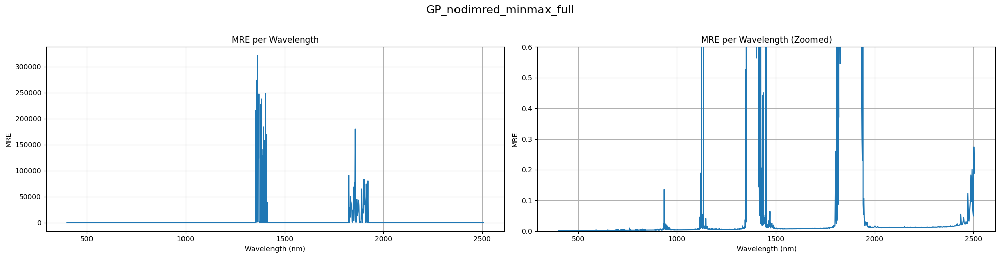

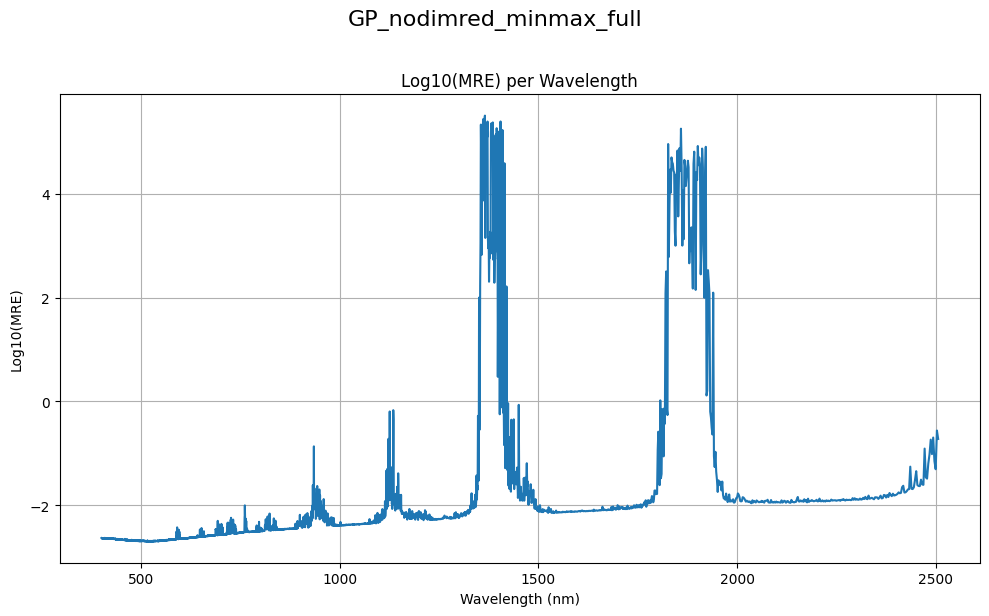

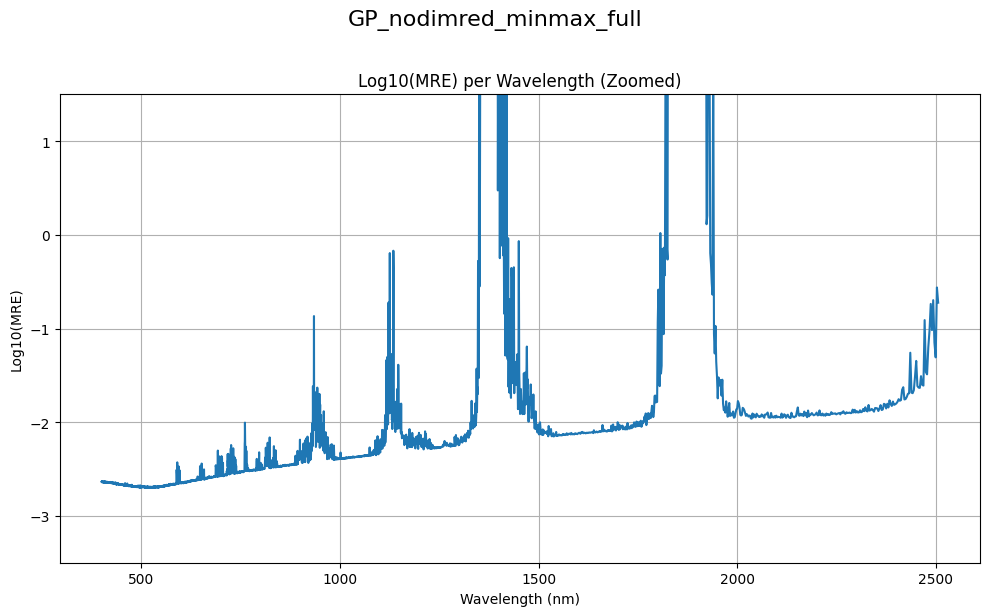

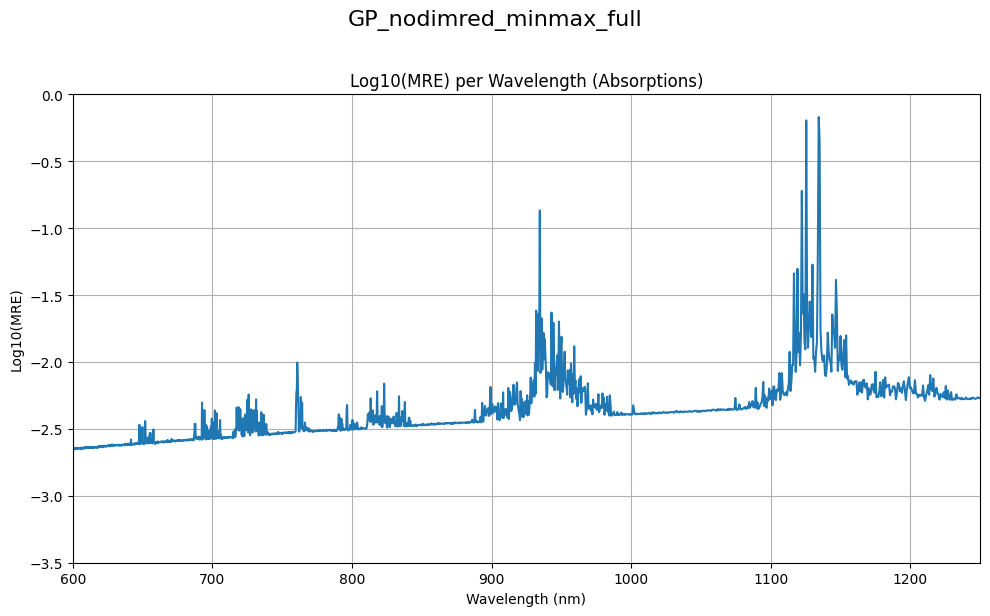

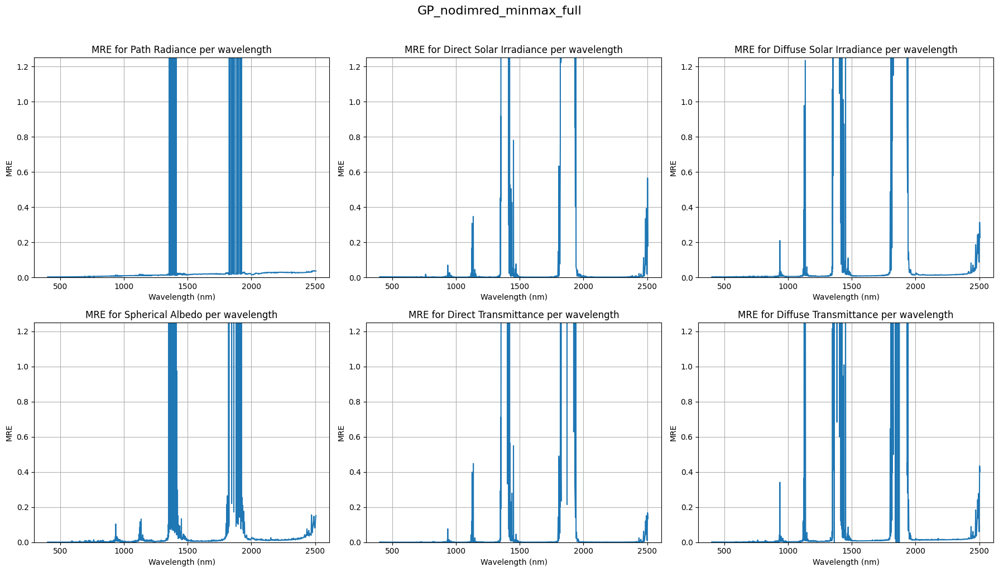

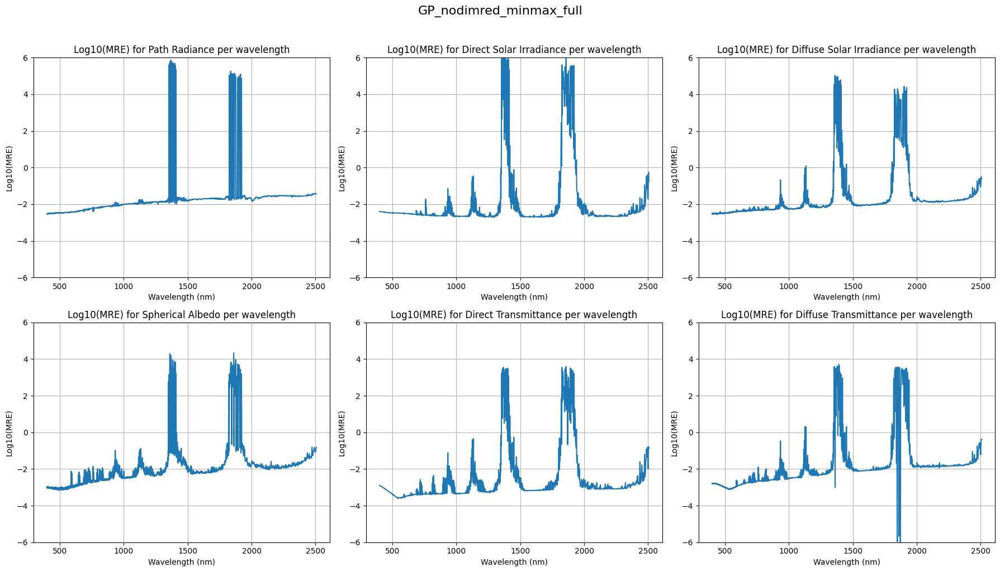

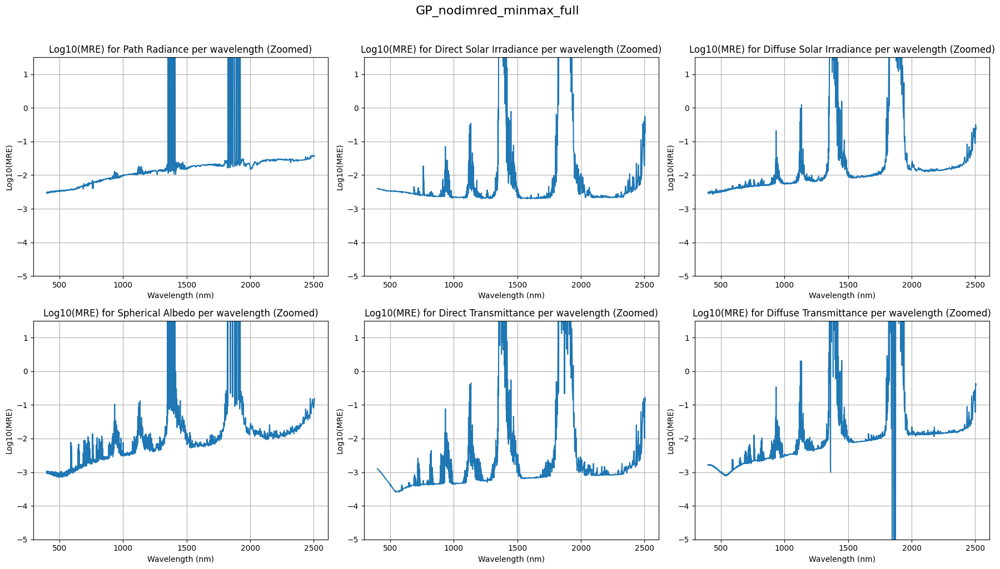

Testing MAE: 0.5572492097160358
Path Radiance MAE: 0.0760
Direct Solar Irradiance MAE: 2.3199
Diffuse Solar Irradiance MAE: 0.9467
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


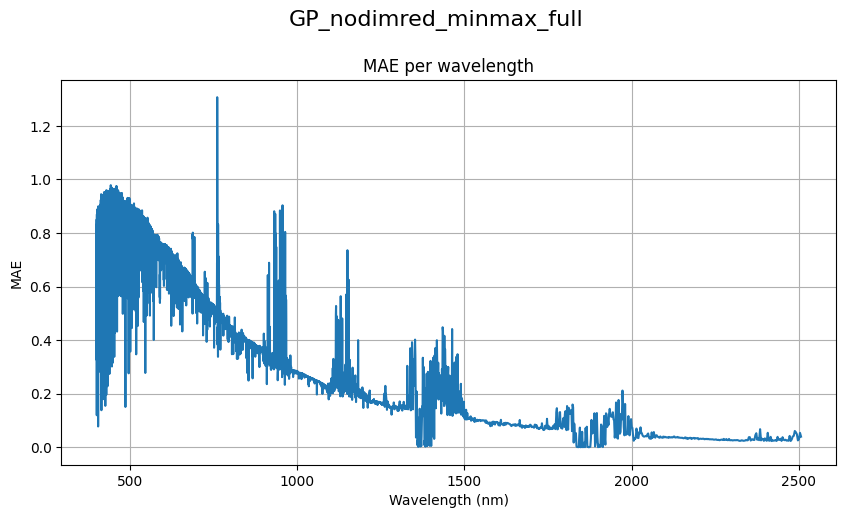

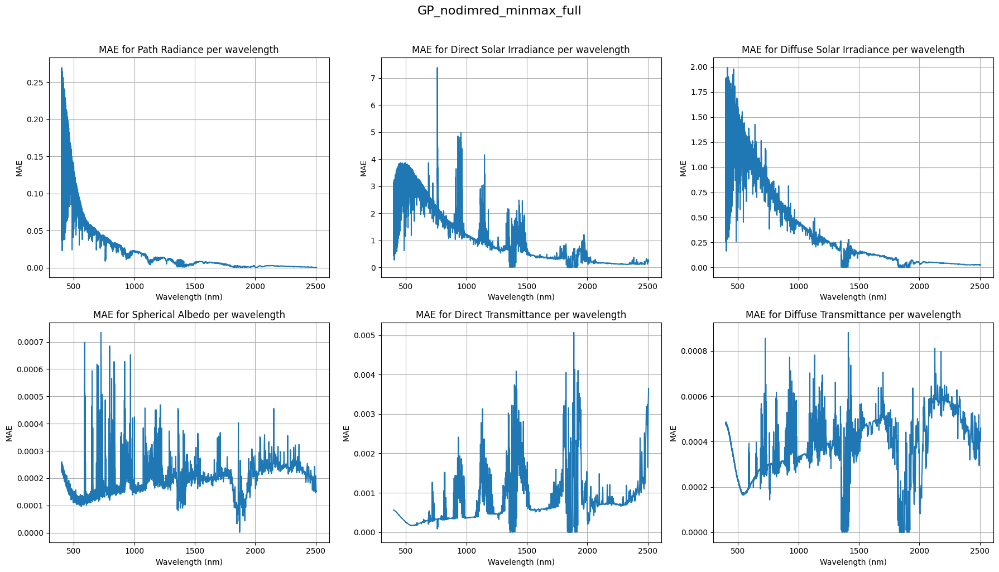

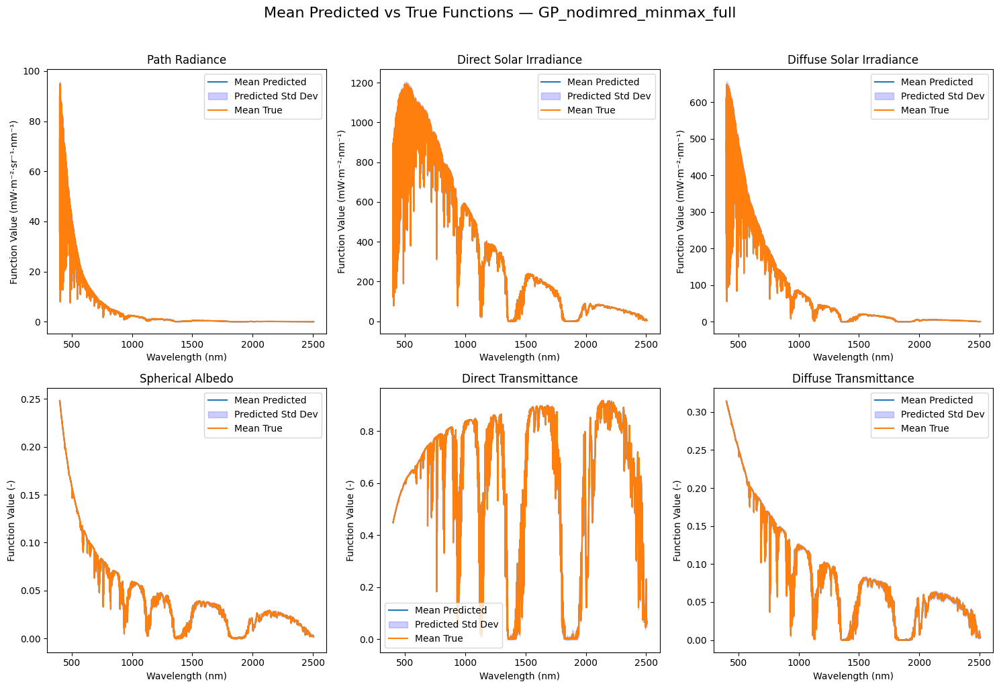

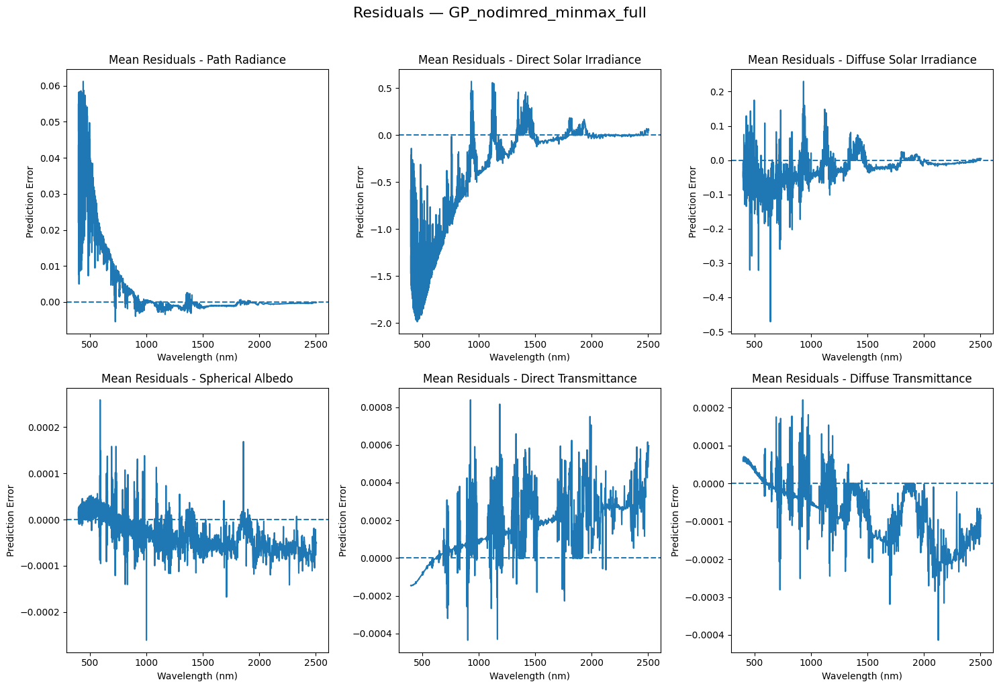

In [13]:
print("---TESTING RESULTS FOR FULL GPRs---\n")

global_cov, func_cov = utils.calculate_coverage(Y_test, preds_full, stds_full)
print(f"\nGlobal Coverage Probability ({2}σ): {global_cov:.2f}%")
print("-" * 30)
for i, name in enumerate(globals.function_names_plots):
    print(f"{name:15} Coverage: {func_cov[i]:.2f}%")
print()

experiment_id = f"GP_nodimred_{scale_type}_full"
test_mre, test_mre_per_func = utils.show_test_results_mre(Y_test, preds_full, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
test_mae, test_mae_per_func = utils.show_test_results_mae(Y_test, preds_full, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
utils.show_predicted_vs_true(Y_test, preds_full, stds_full, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
utils.show_residuals(Y_test, preds_full, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))

entry = {
    "experiment_id": experiment_id,
    "gp_kernel_full_name": "nodimred_full",
    "model": "nodimred_full",
    "scale_type": "minmax",
    "dataset_size": "500",
    "inference_time": test_time_full,
    "test_mre": test_mre,
    "test_mae": test_mae,
    "global_cov": global_cov
}

for name, value in zip(globals.function_names_results, test_mre_per_func):
    entry[f"test_mre_{name}"] = value

for name, value in zip(globals.function_names_results, test_mae_per_func):
    entry[f"test_mae_{name}"] = value

for name, value in zip(globals.function_names_plots, func_cov):
    entry[f"coverage_{name}"] = value

results_df = pd.DataFrame([entry])
results_df.to_csv(globals.gp_output_path("./gp_saves/testing_results/gp_test_results.csv"), mode="a", header=not Path(globals.gp_output_path("./gp_saves/testing_results/gp_test_results.csv")).exists(), index=False)

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 6 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.16s

Global Coverage Probability (2σ): 93.58%
------------------------------
Path Radiance   Coverage: 94.67%
Direct Solar Irradiance Coverage: 94.13%
Diffuse Solar Irradiance Coverage: 95.10%
Spherical Albedo Coverage: 94.68%
Direct Transmittance Coverage: 91.21%
Diffuse Transmittance Coverage: 91.69%

0.004005688207206326
0.5340122106753455
Testing MRE: 0.004005688207206326
Path Radiance MRE: 0.0072
Direct Solar Irradiance MRE: 0.0029
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0035
Direct Transmittance MRE: 0.0008
Diffuse Transmittance MRE: 0.0044


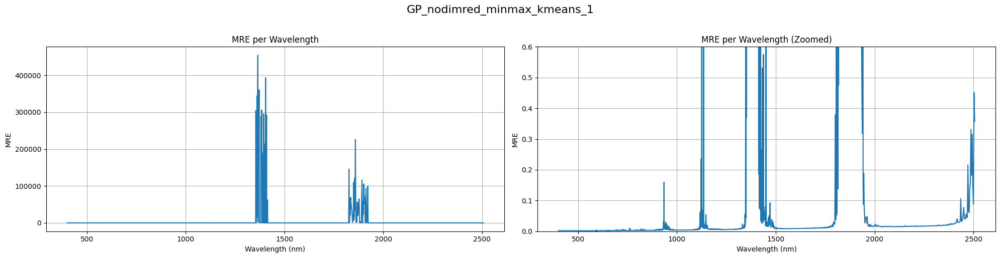

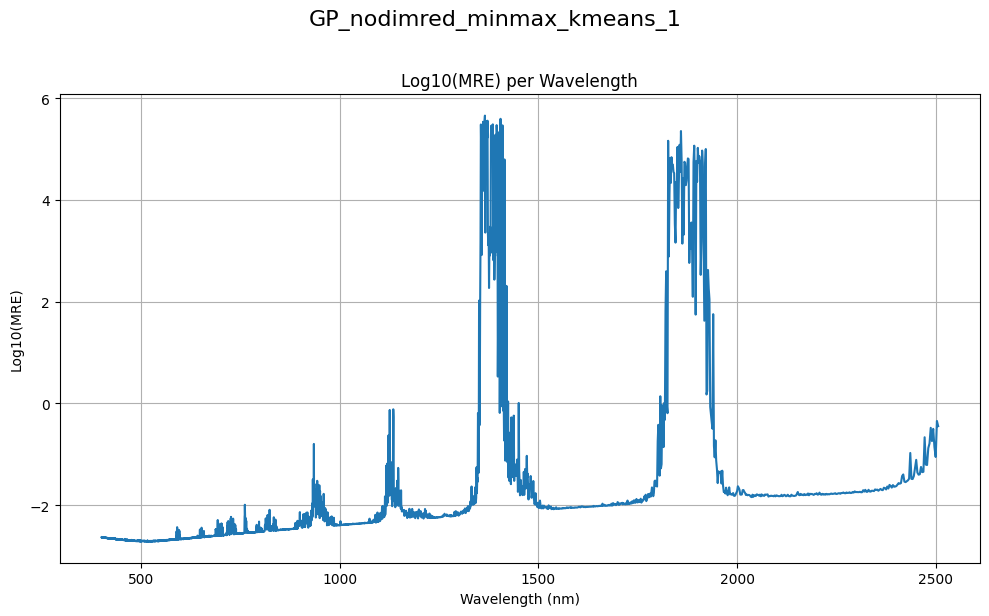

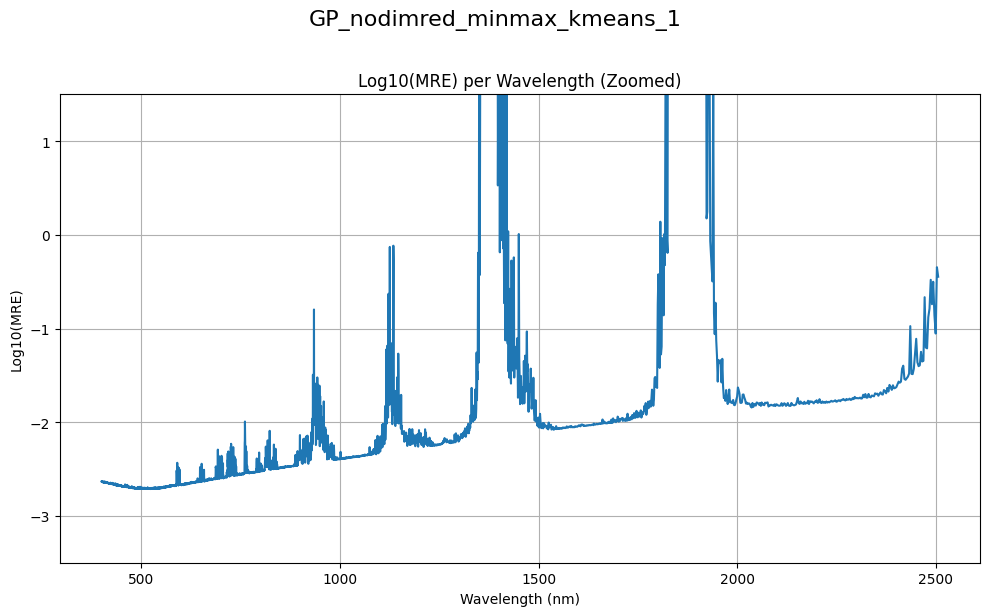

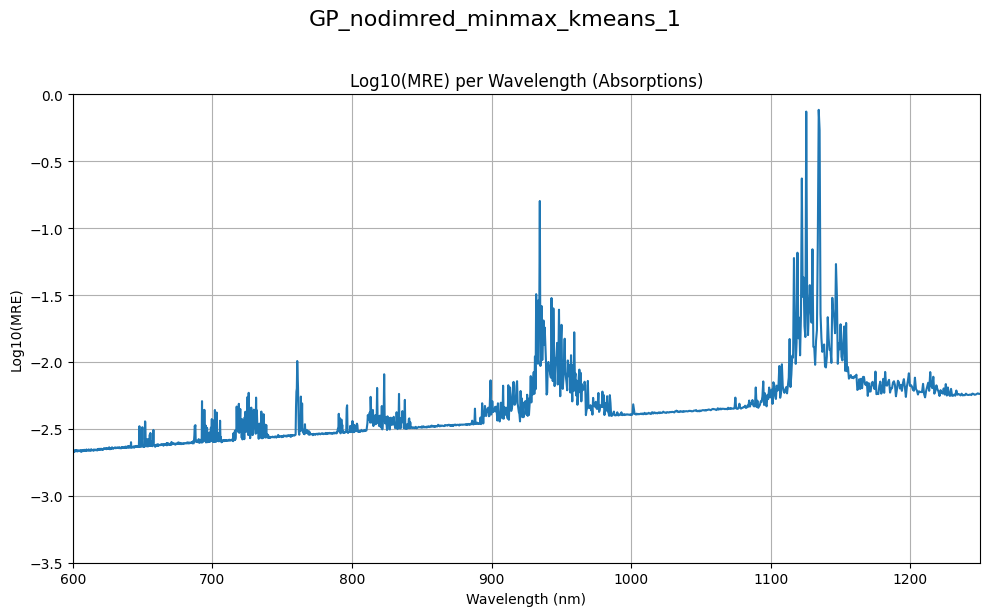

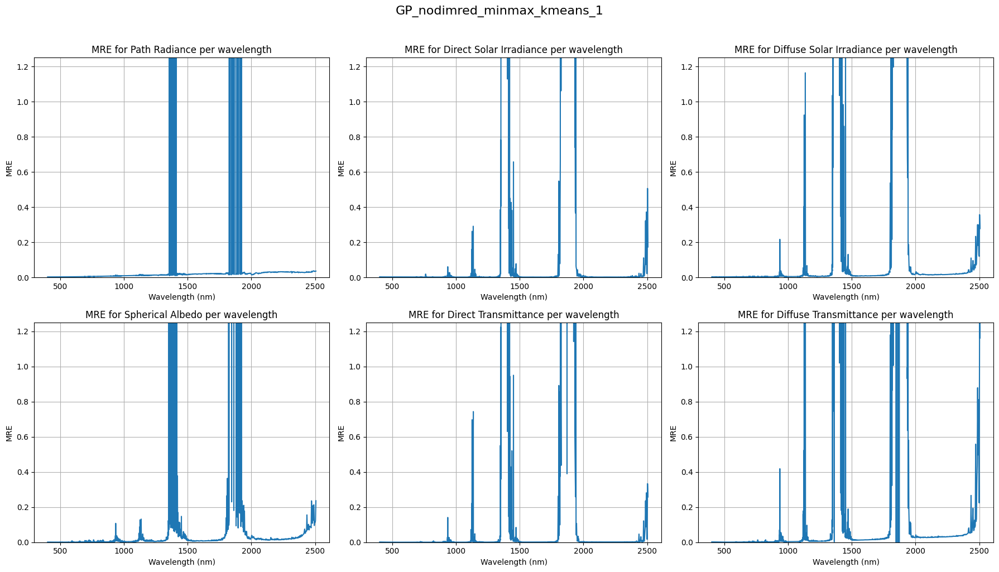

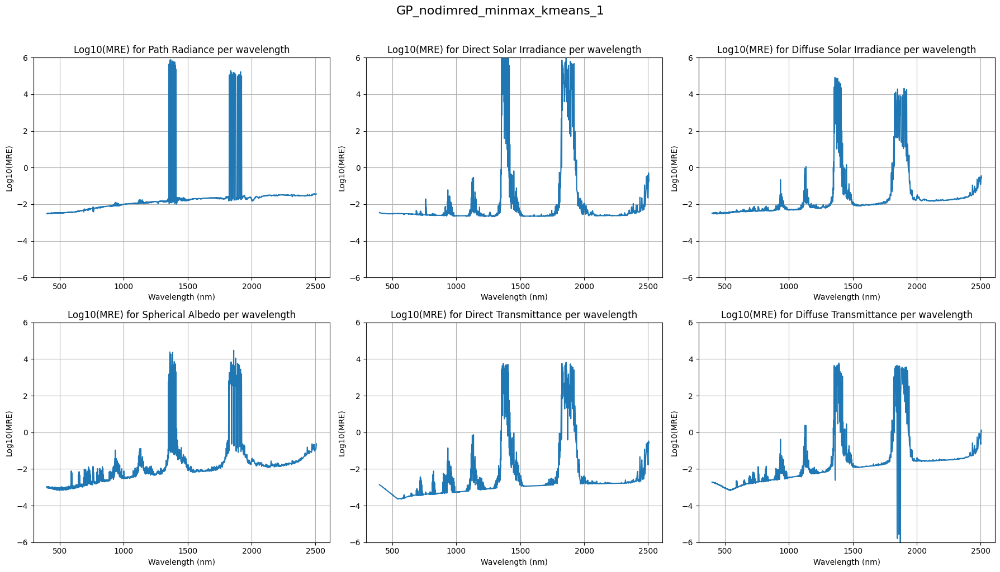

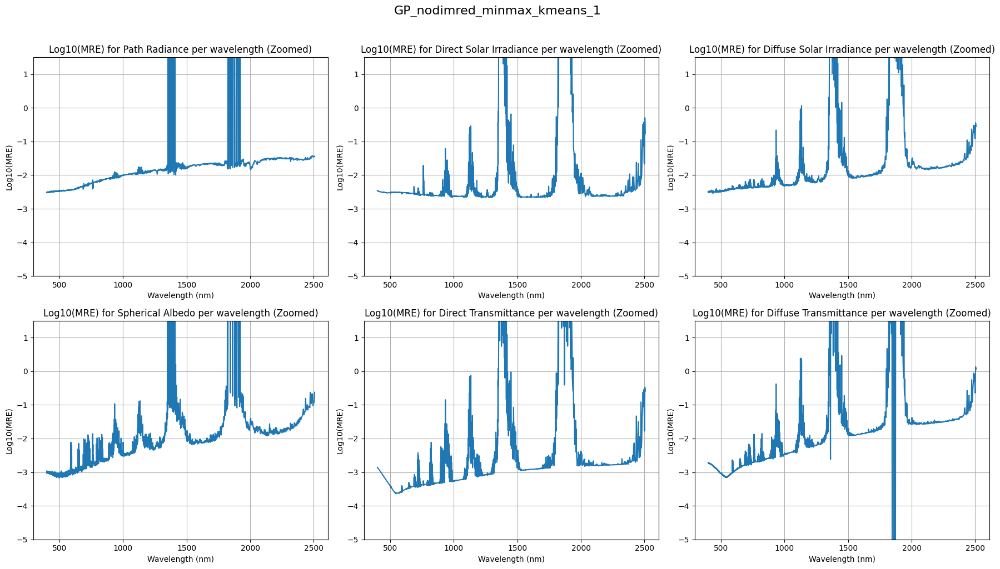

Testing MAE: 0.5340122106753455
Path Radiance MAE: 0.0764
Direct Solar Irradiance MAE: 2.1829
Diffuse Solar Irradiance MAE: 0.9437
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0005
Diffuse Transmittance MAE: 0.0004


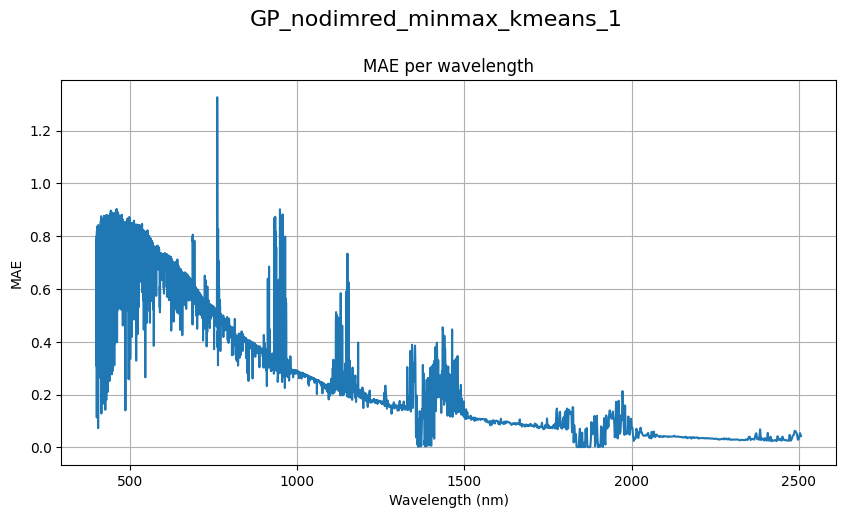

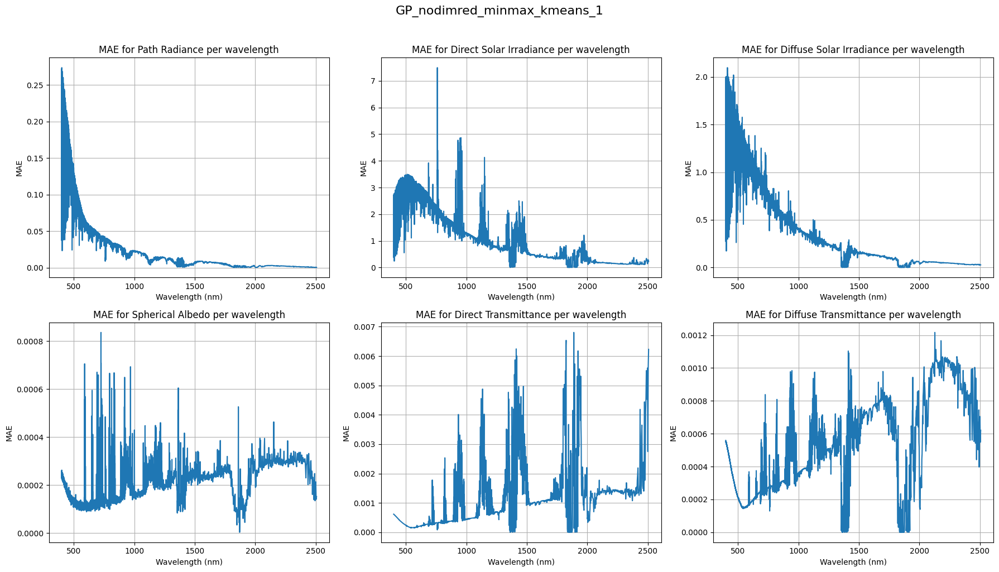

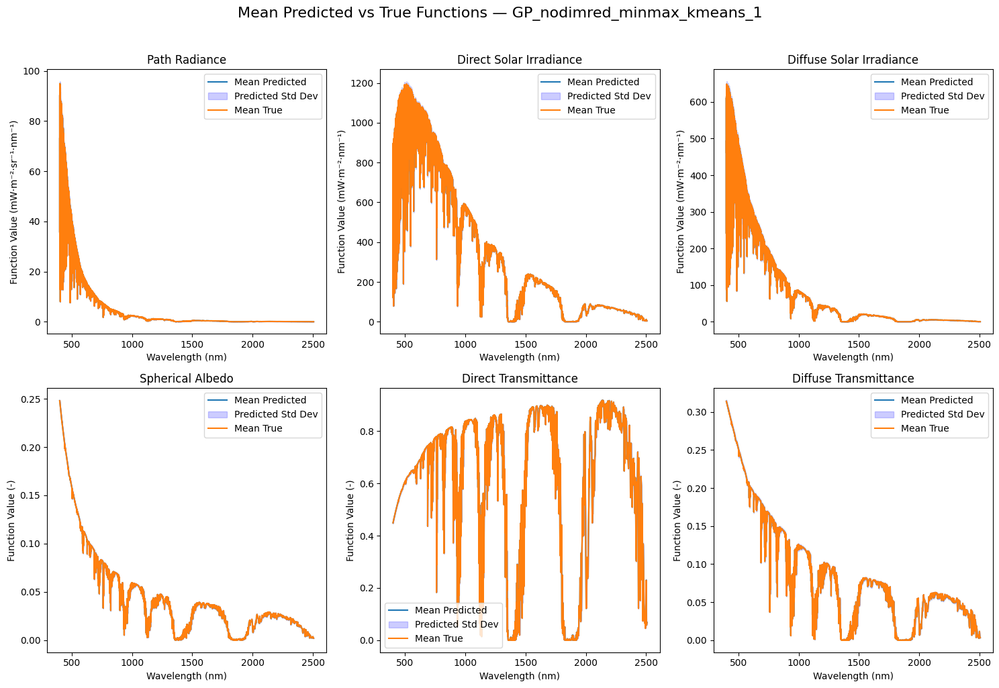

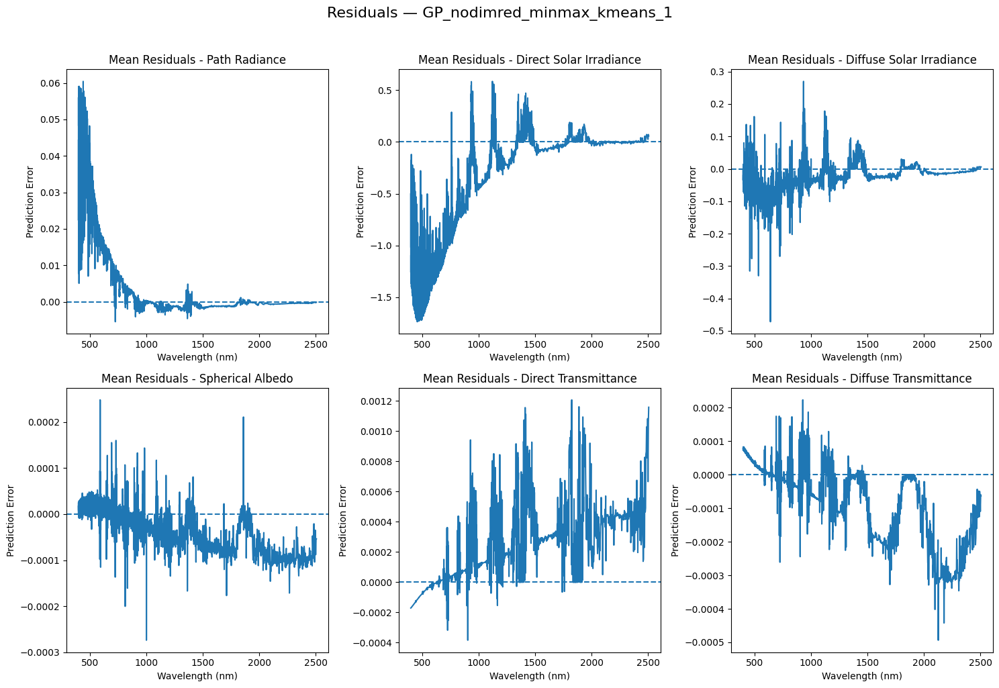

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 12 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.20s

Global Coverage Probability (2σ): 95.39%
------------------------------
Path Radiance   Coverage: 95.77%
Direct Solar Irradiance Coverage: 94.48%
Diffuse Solar Irradiance Coverage: 97.78%
Spherical Albedo Coverage: 96.46%
Direct Transmittance Coverage: 96.13%
Diffuse Transmittance Coverage: 91.74%

0.003928846466179397
0.55067445699658
Testing MRE: 0.003928846466179397
Path Radiance MRE: 0.0070
Direct Solar Irradiance MRE: 0.0030
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0044


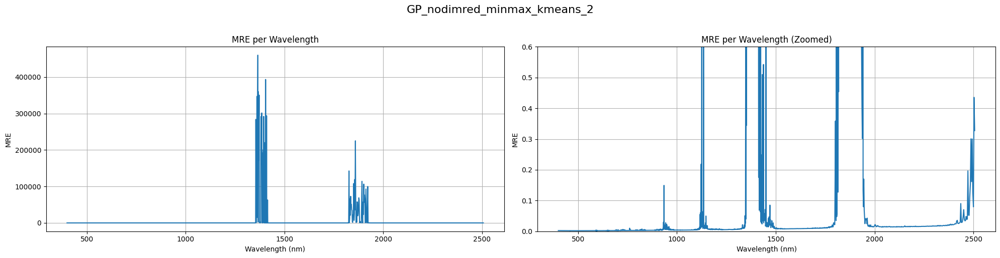

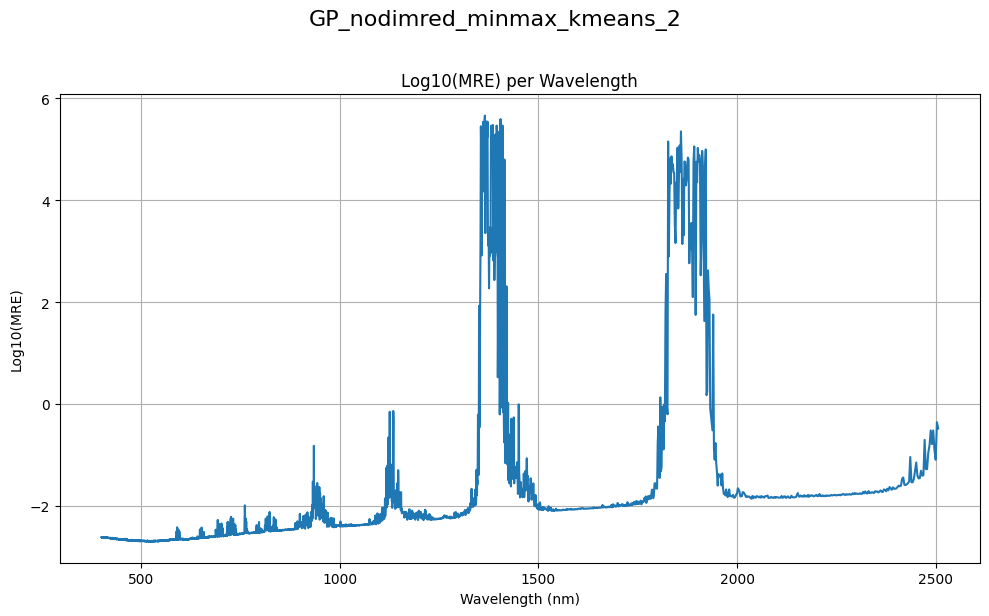

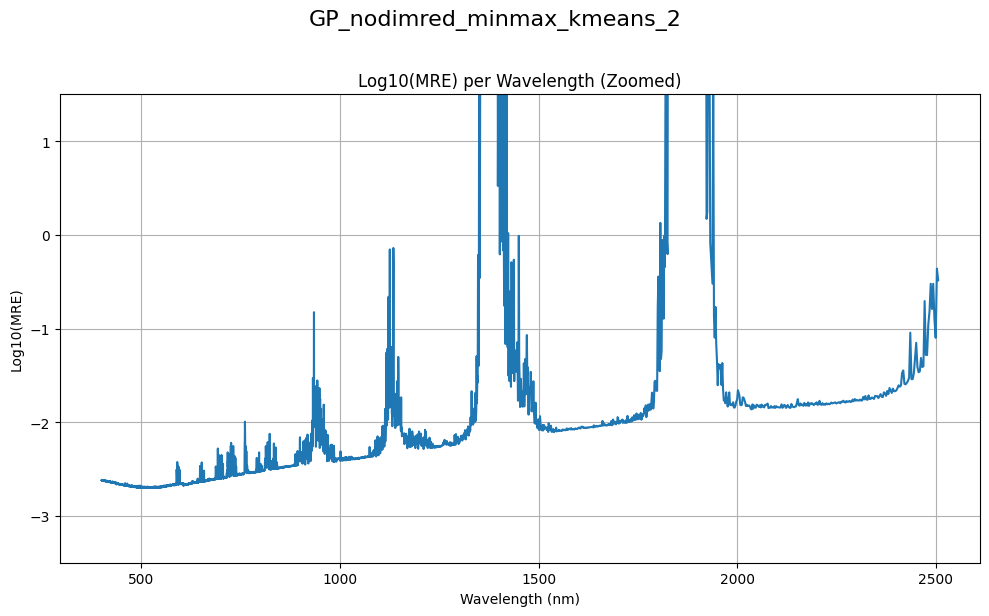

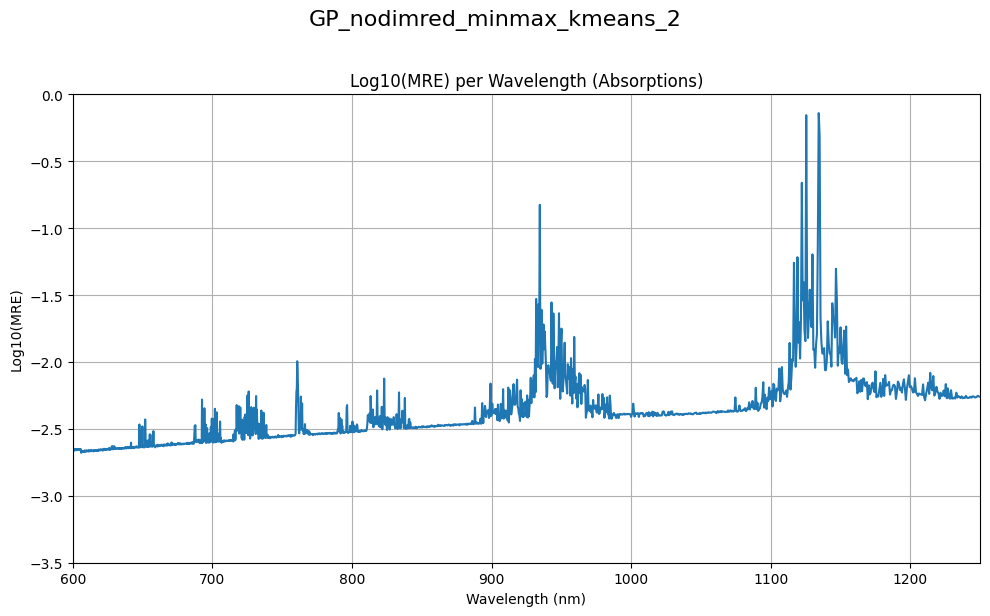

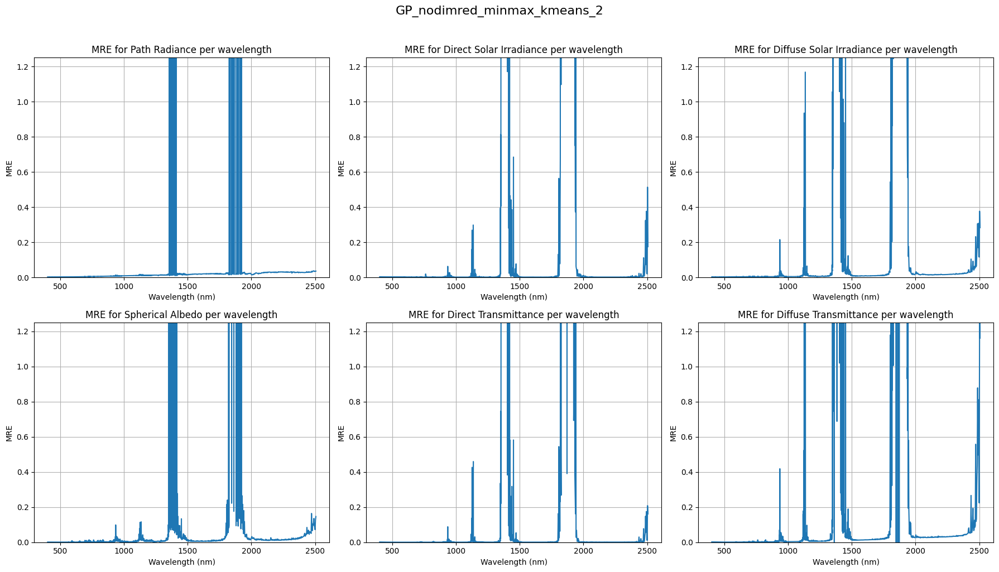

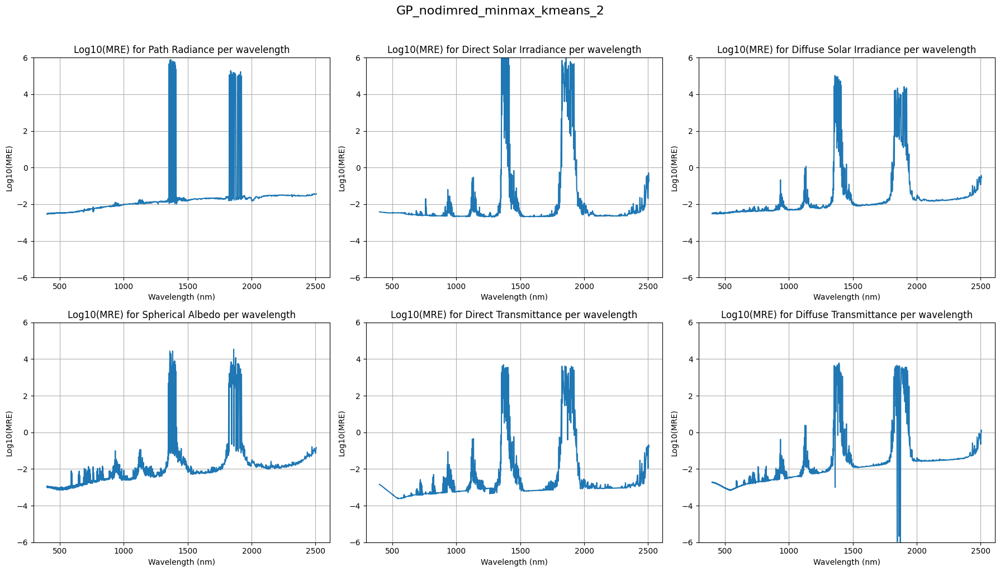

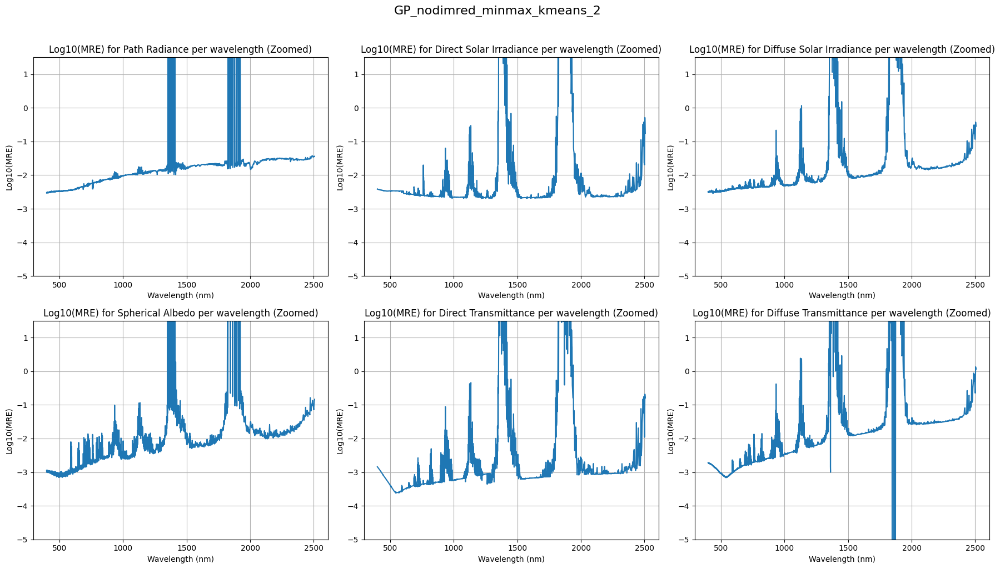

Testing MAE: 0.55067445699658
Path Radiance MAE: 0.0751
Direct Solar Irradiance MAE: 2.2882
Diffuse Solar Irradiance MAE: 0.9398
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0004


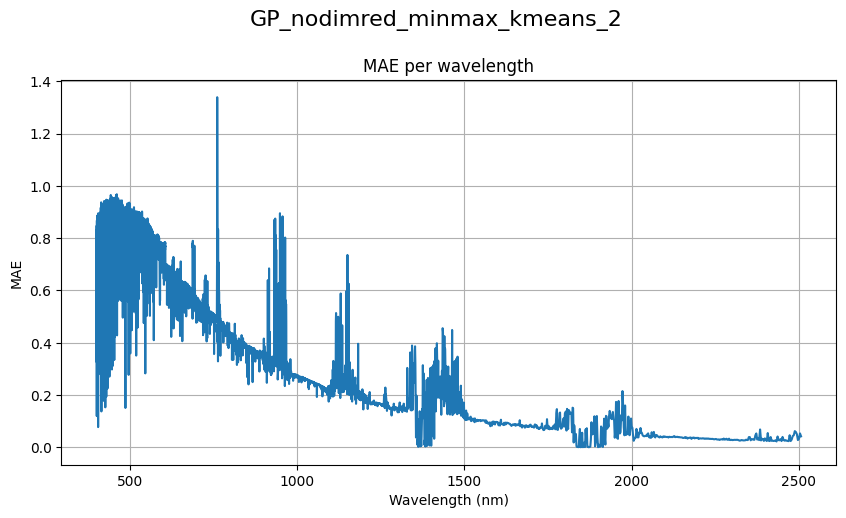

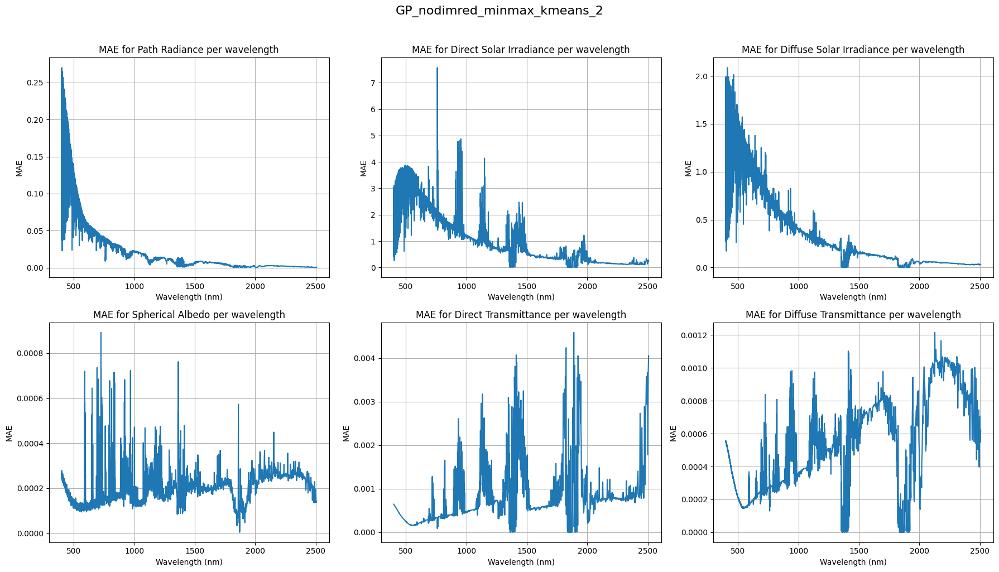

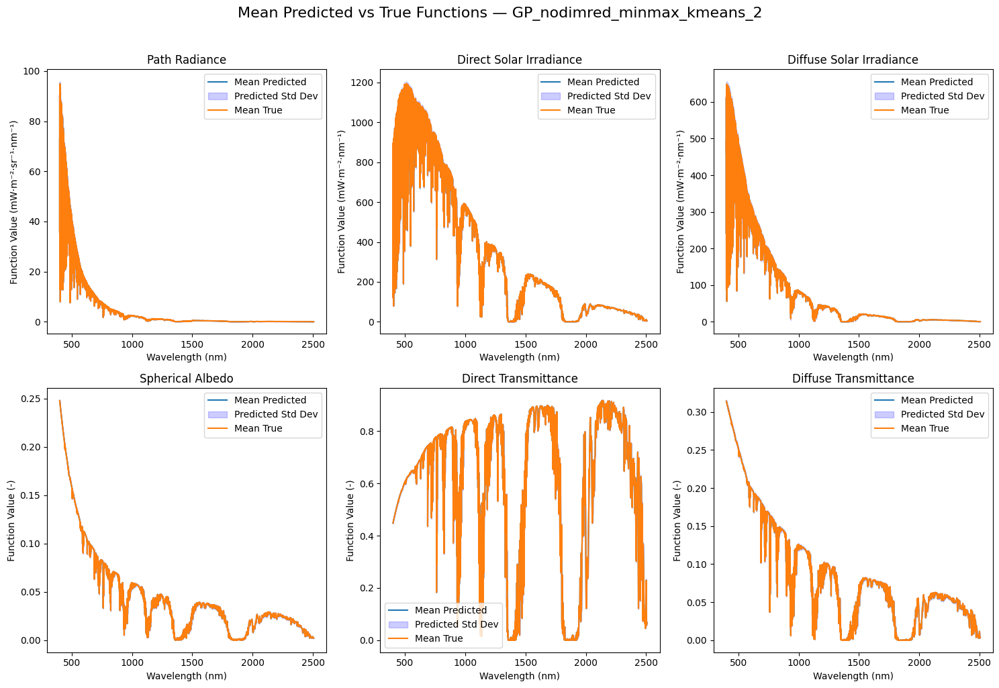

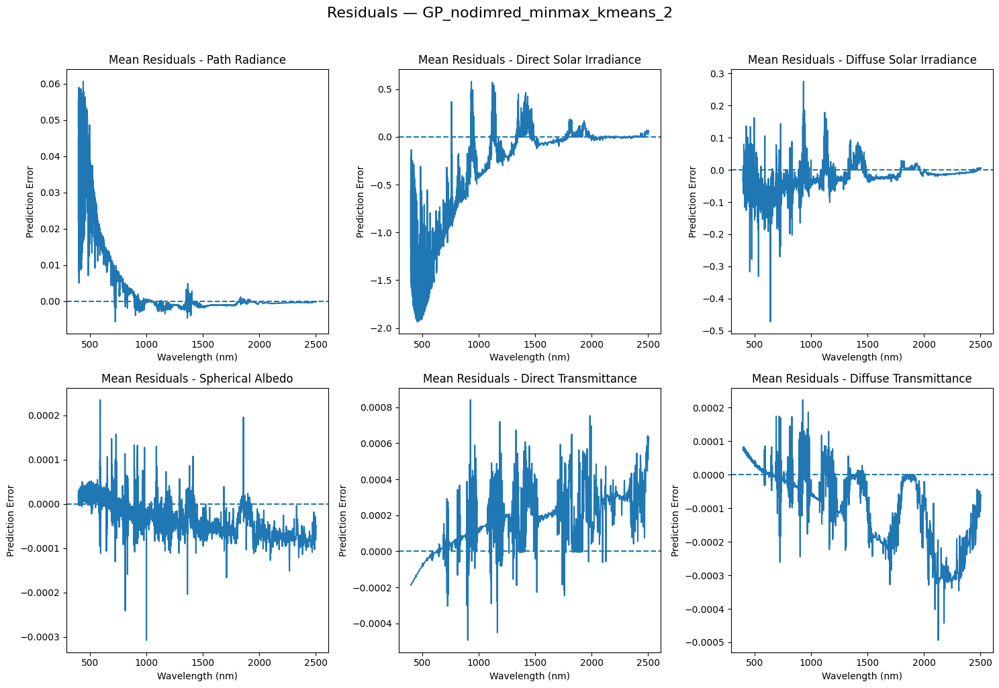

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 18 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.24s

Global Coverage Probability (2σ): 96.40%
------------------------------
Path Radiance   Coverage: 95.51%
Direct Solar Irradiance Coverage: 96.61%
Diffuse Solar Irradiance Coverage: 97.60%
Spherical Albedo Coverage: 96.71%
Direct Transmittance Coverage: 96.12%
Diffuse Transmittance Coverage: 95.85%

0.0037620514327403876
0.5523438864334881
Testing MRE: 0.0037620514327403876
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0030
Diffuse Solar Irradiance MRE: 0.0053
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


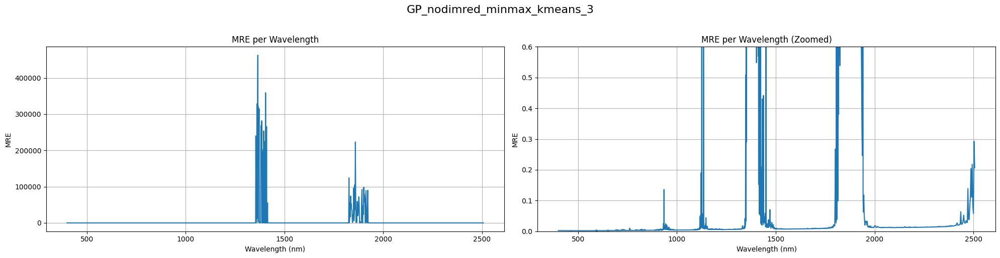

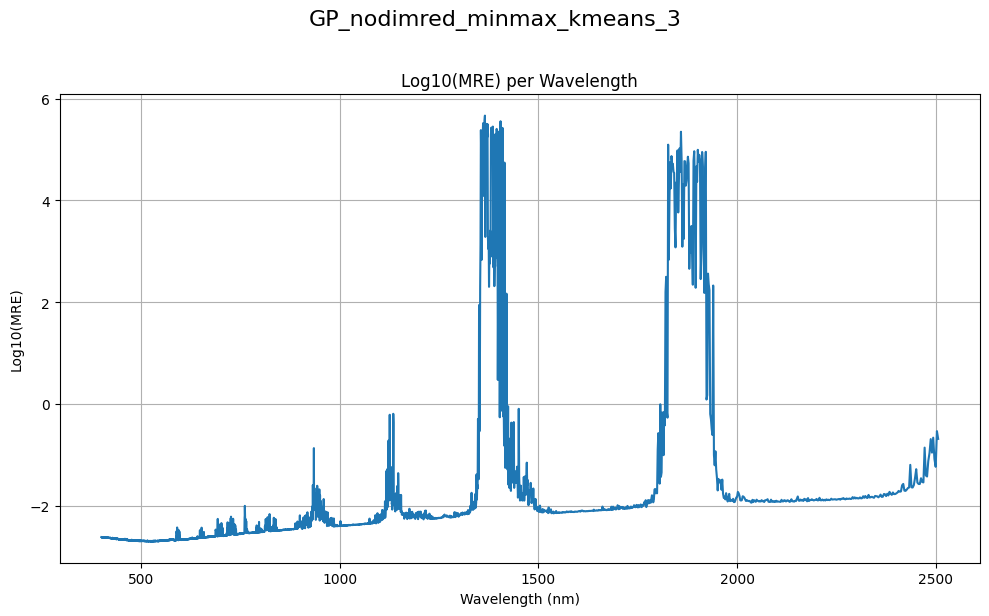

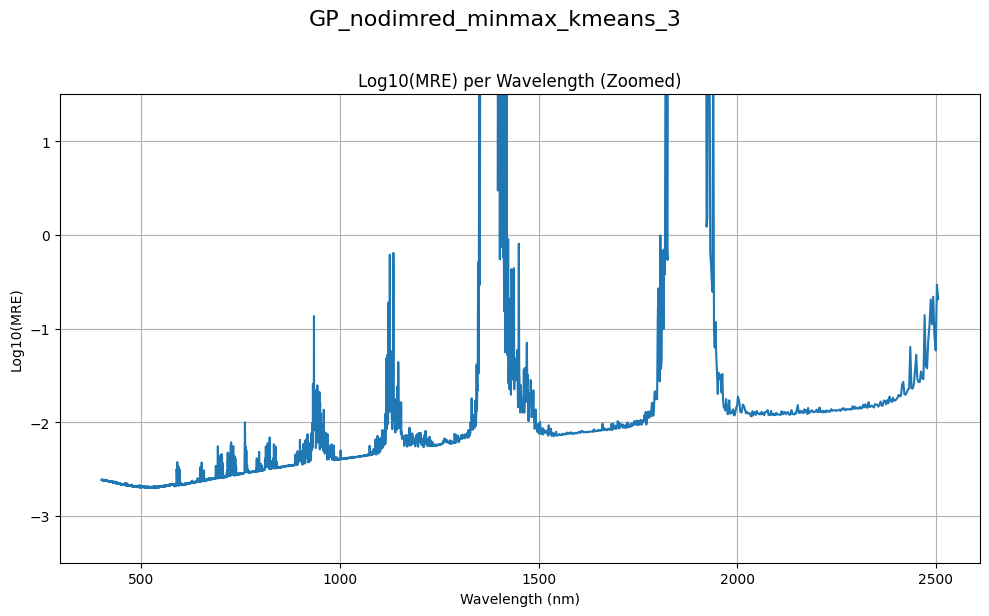

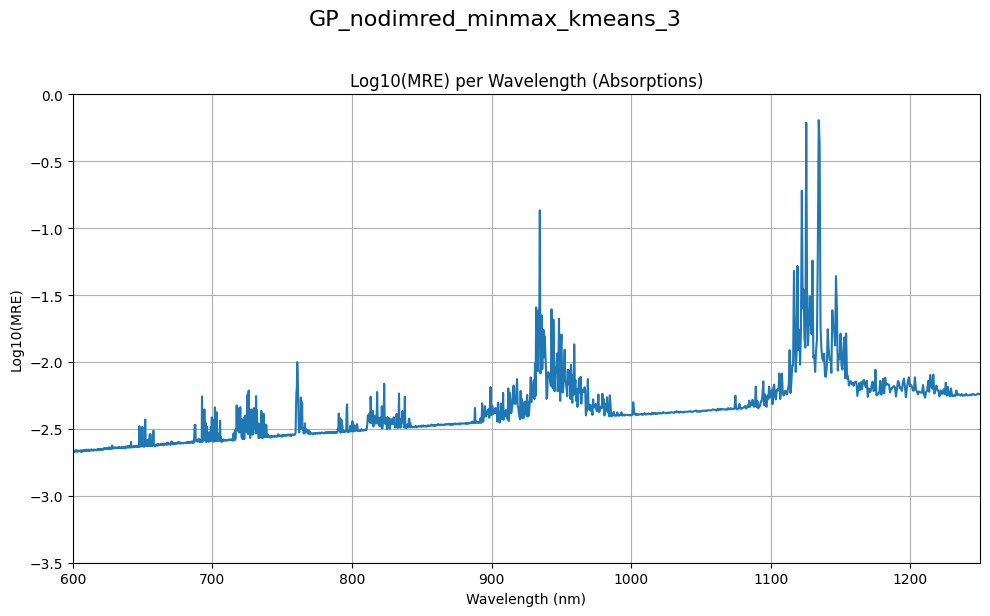

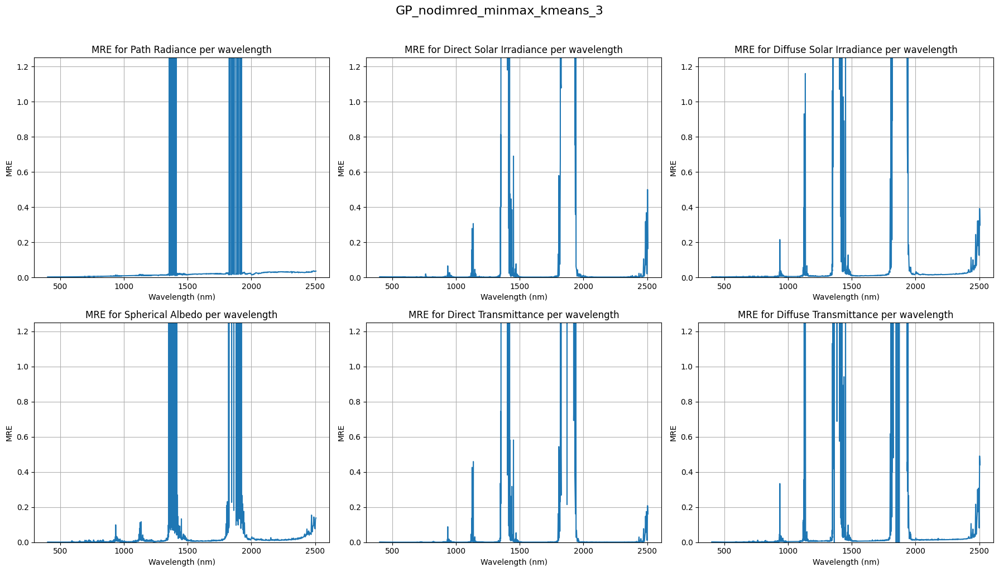

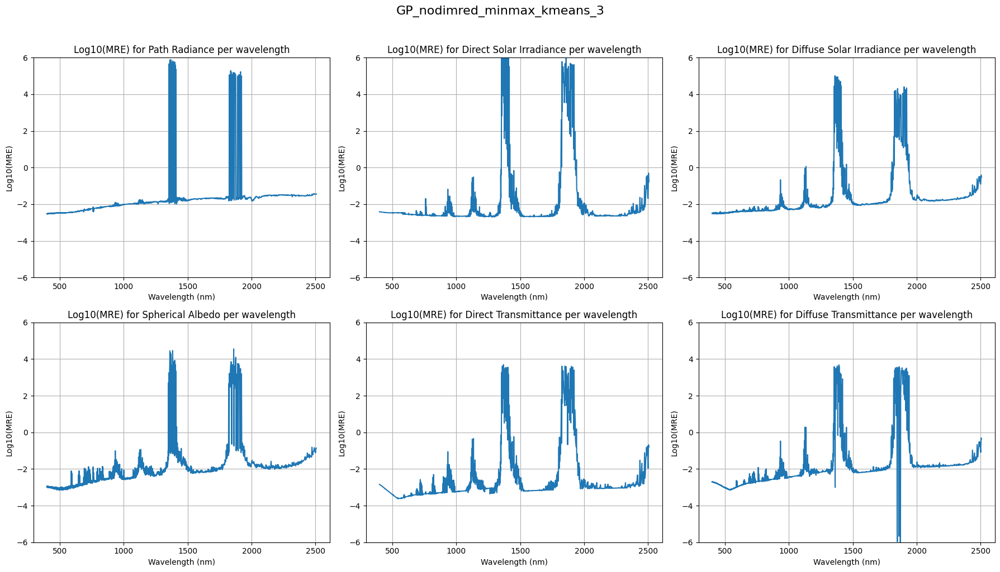

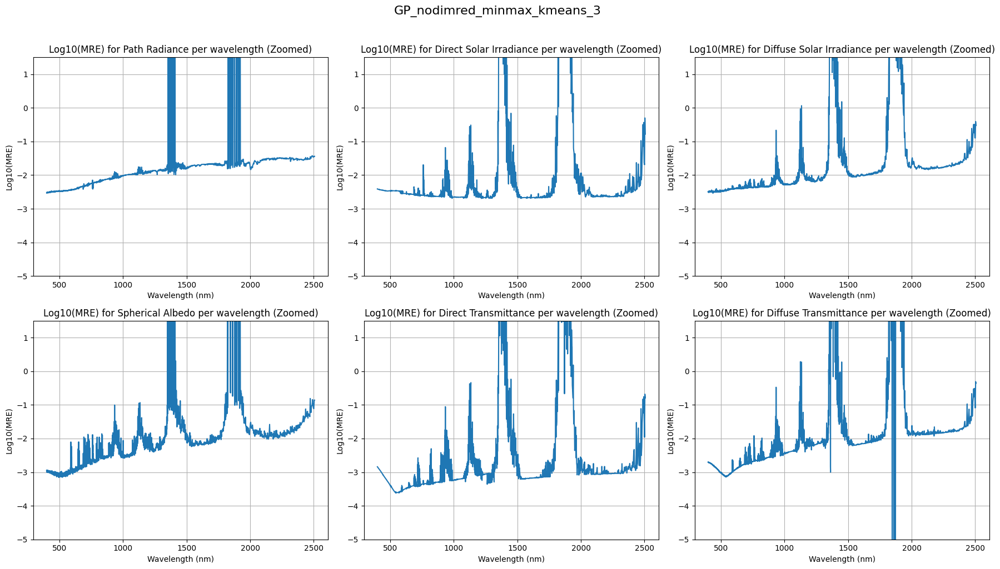

Testing MAE: 0.5523438864334881
Path Radiance MAE: 0.0753
Direct Solar Irradiance MAE: 2.2879
Diffuse Solar Irradiance MAE: 0.9499
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


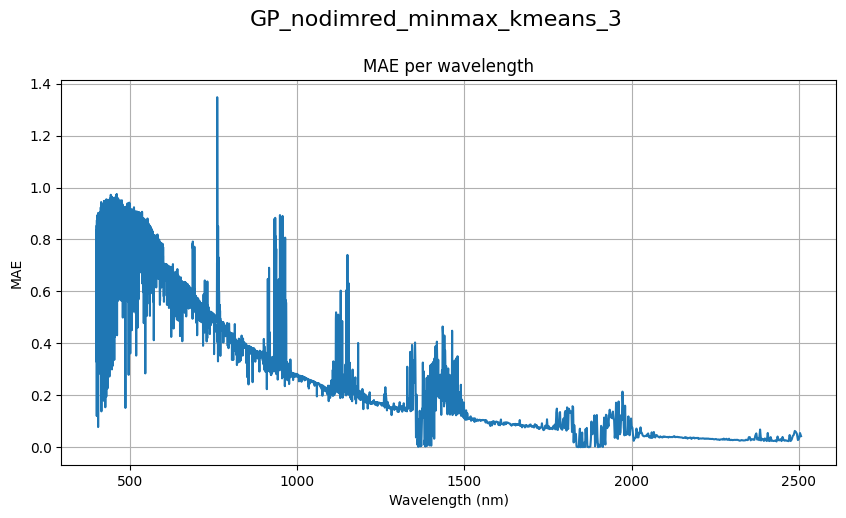

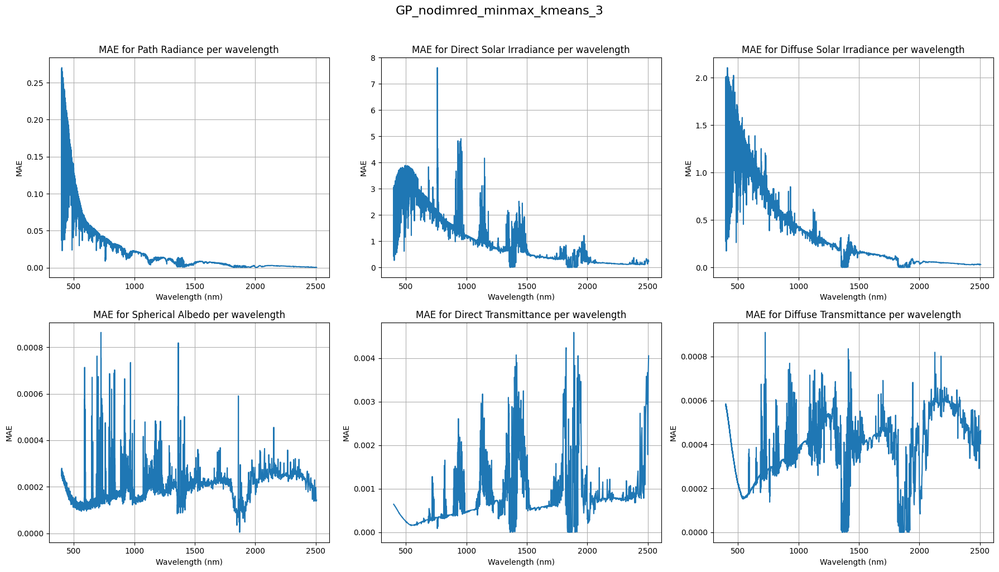

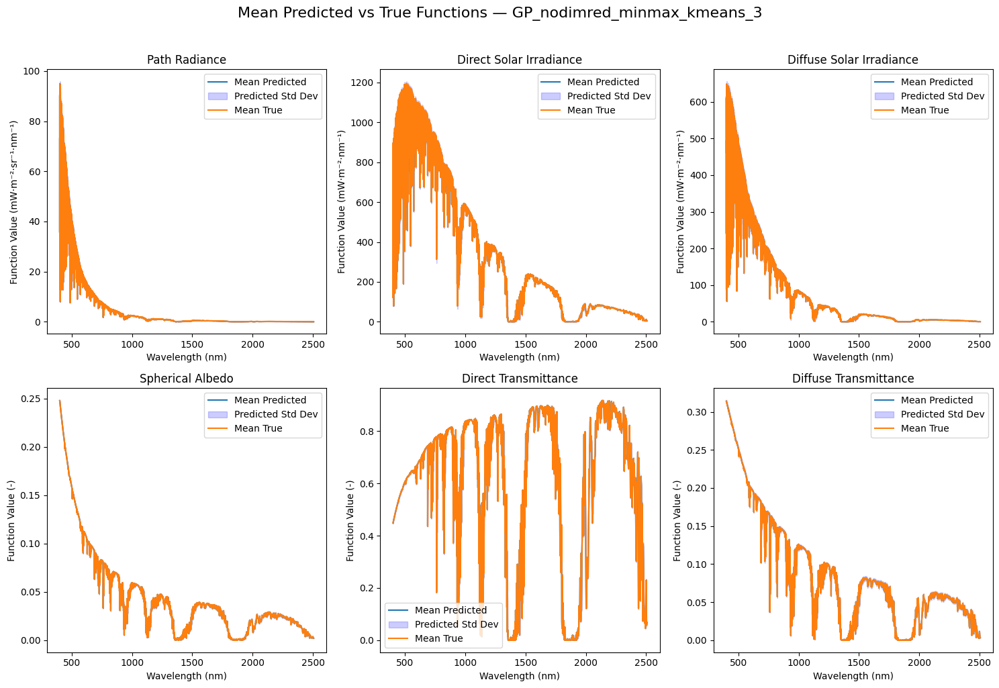

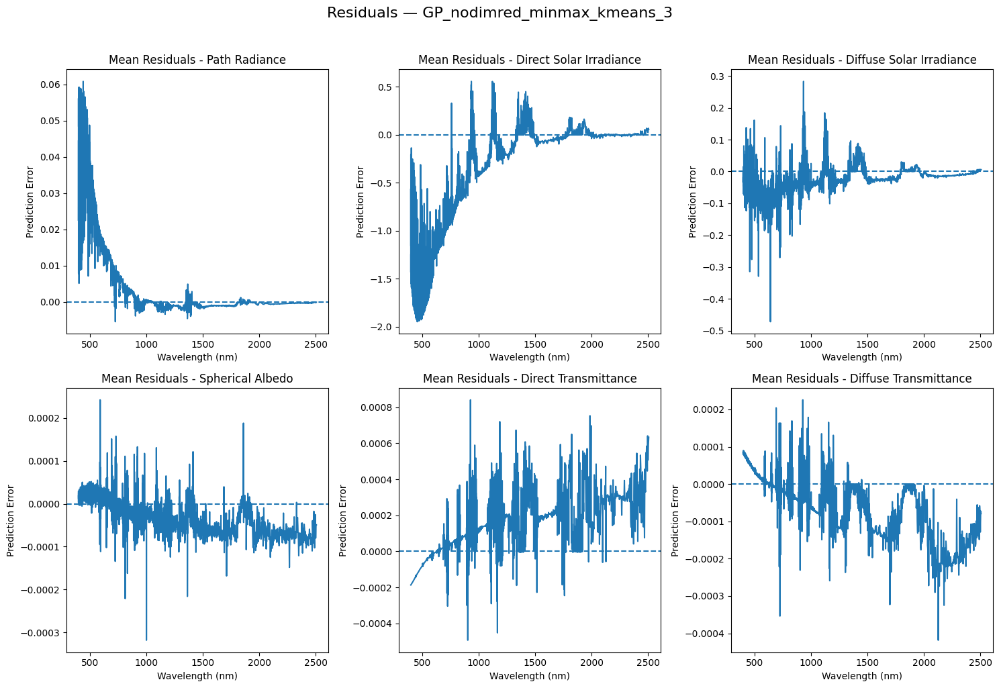

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 24 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.29s

Global Coverage Probability (2σ): 96.78%
------------------------------
Path Radiance   Coverage: 96.49%
Direct Solar Irradiance Coverage: 96.97%
Diffuse Solar Irradiance Coverage: 97.78%
Spherical Albedo Coverage: 97.28%
Direct Transmittance Coverage: 96.25%
Diffuse Transmittance Coverage: 95.89%

0.0037549525181281317
0.5551285015710433
Testing MRE: 0.0037549525181281317
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0053
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


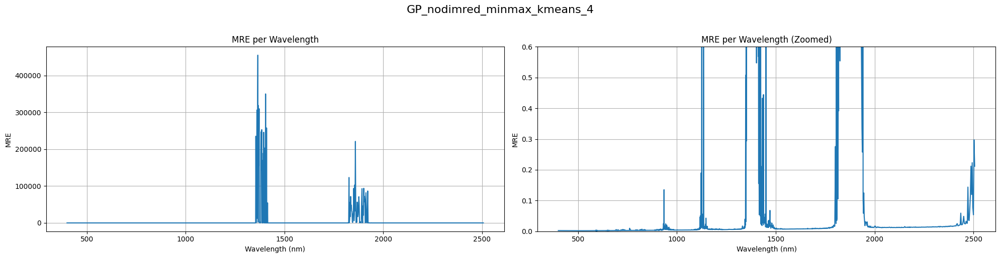

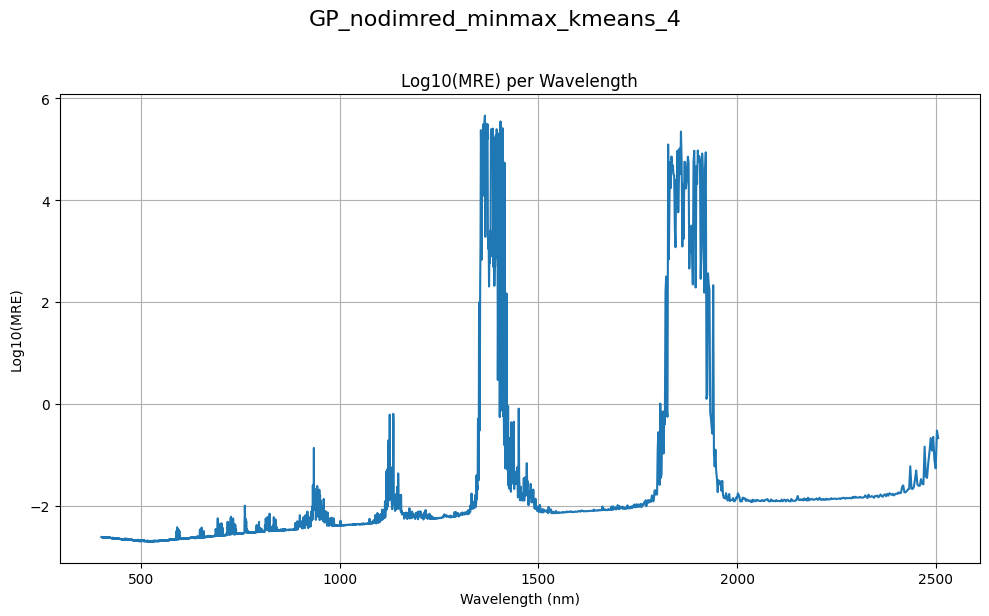

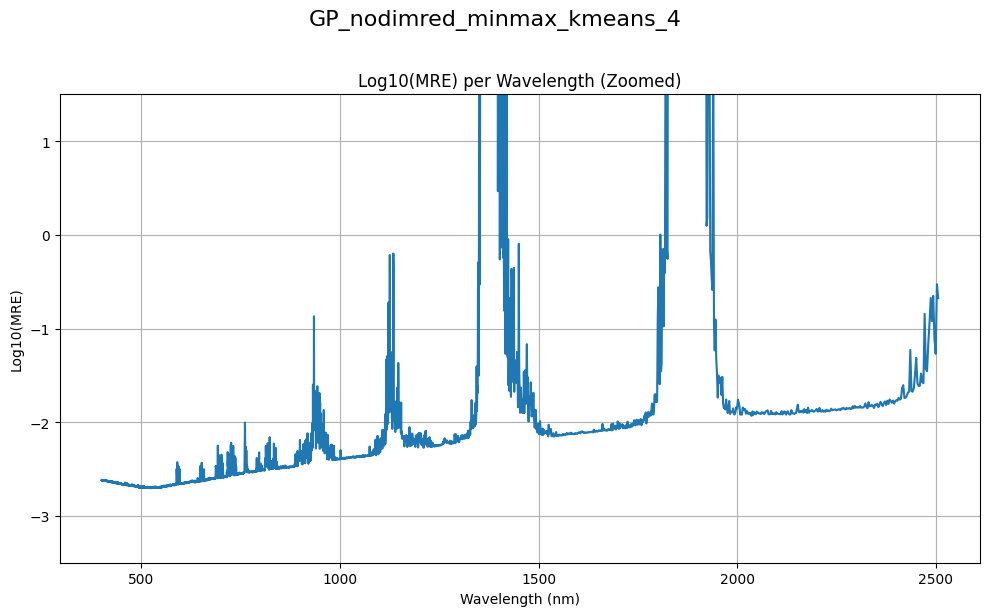

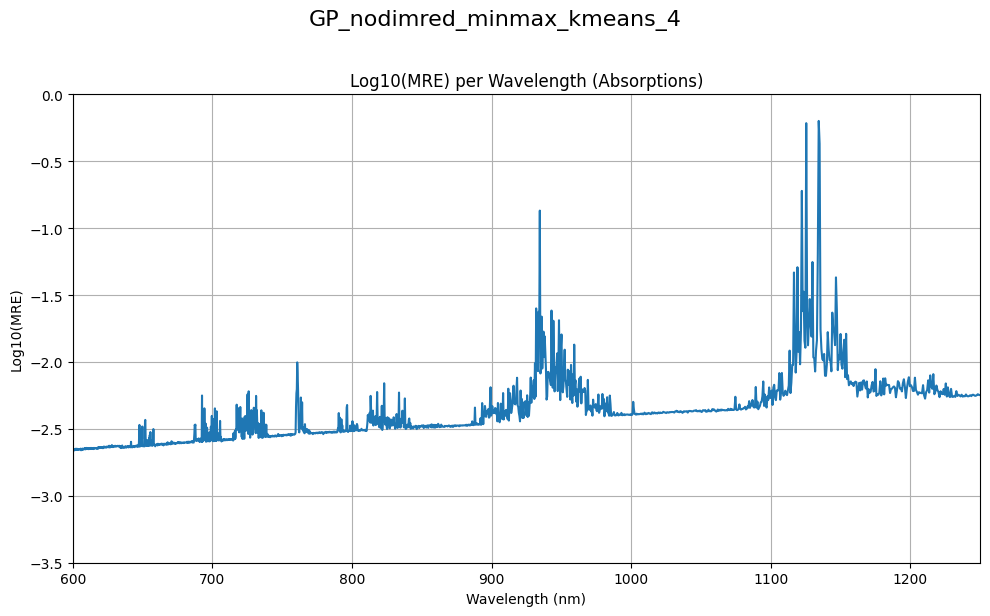

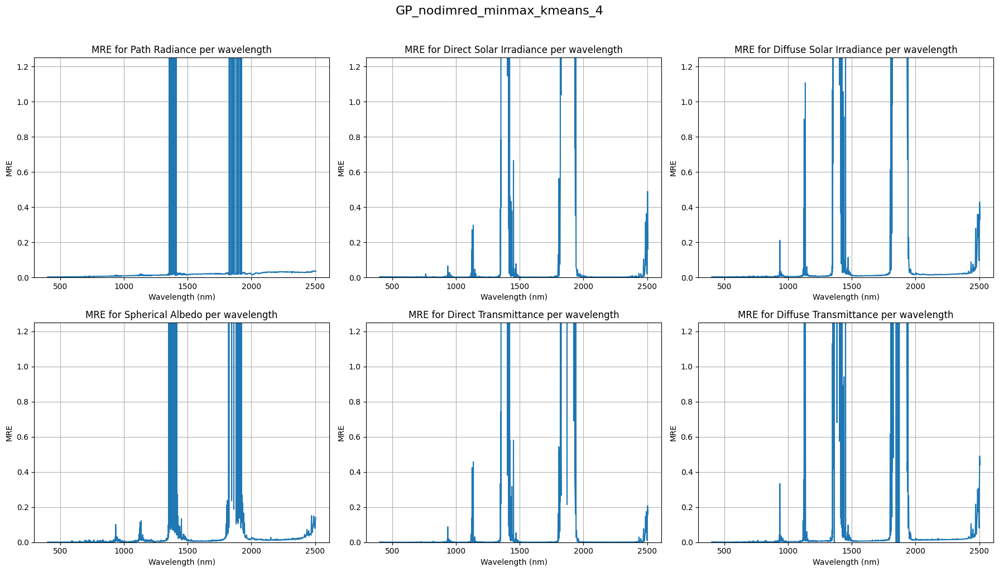

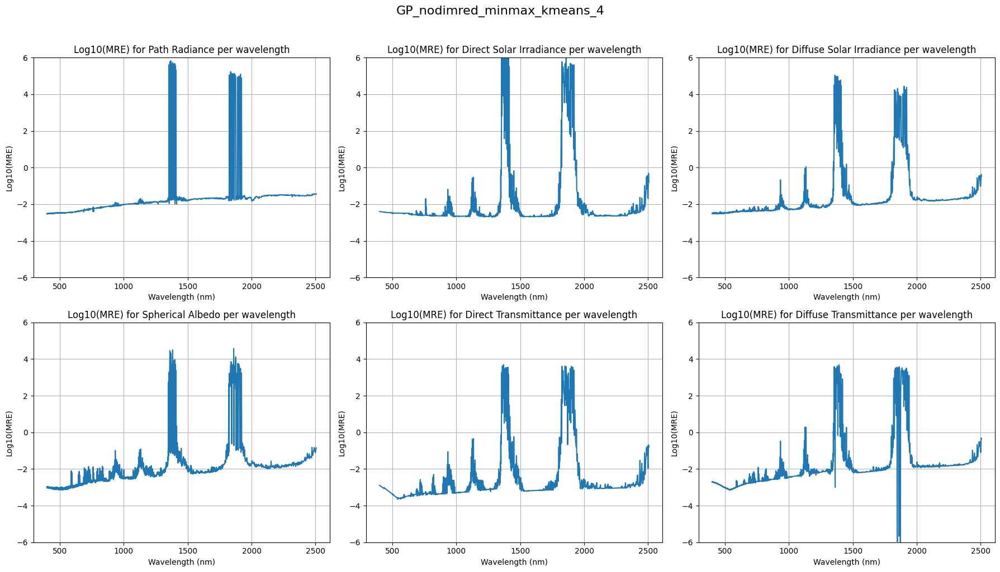

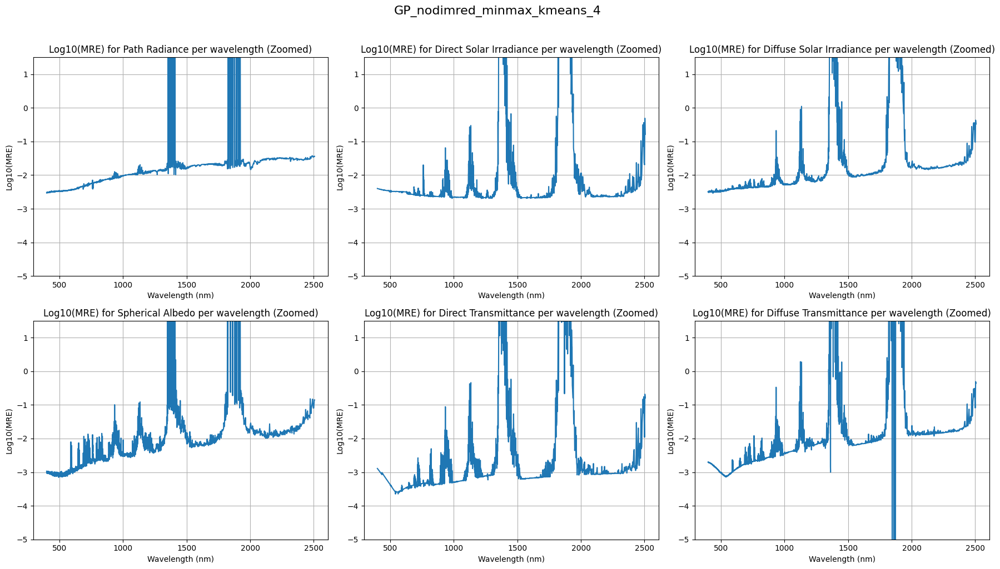

Testing MAE: 0.5551285015710433
Path Radiance MAE: 0.0755
Direct Solar Irradiance MAE: 2.3045
Diffuse Solar Irradiance MAE: 0.9498
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


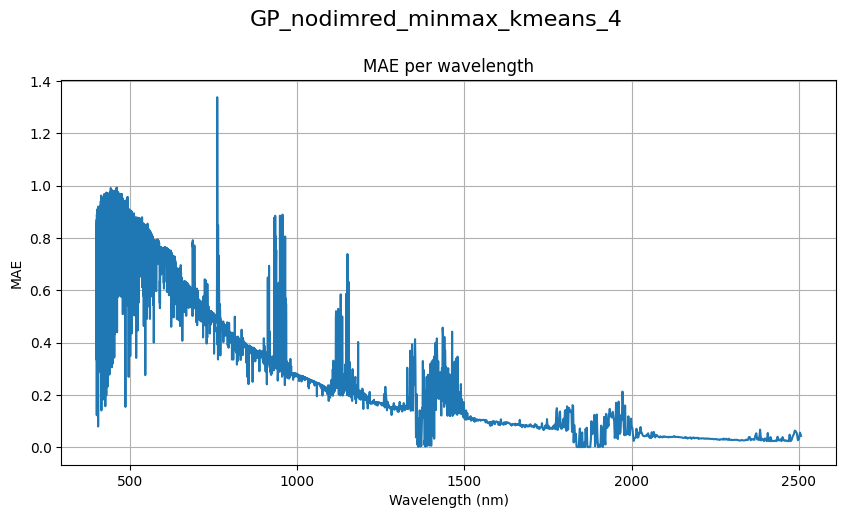

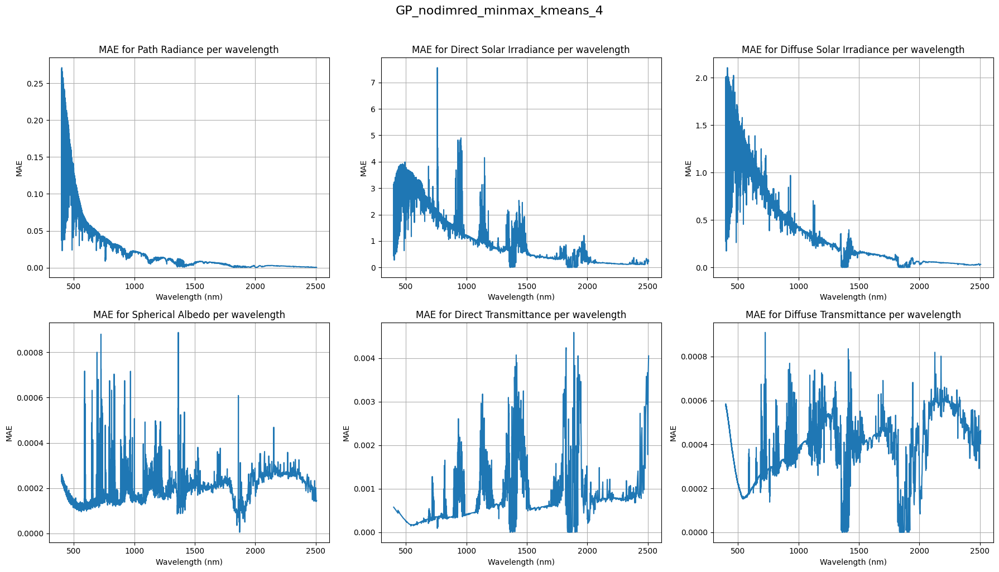

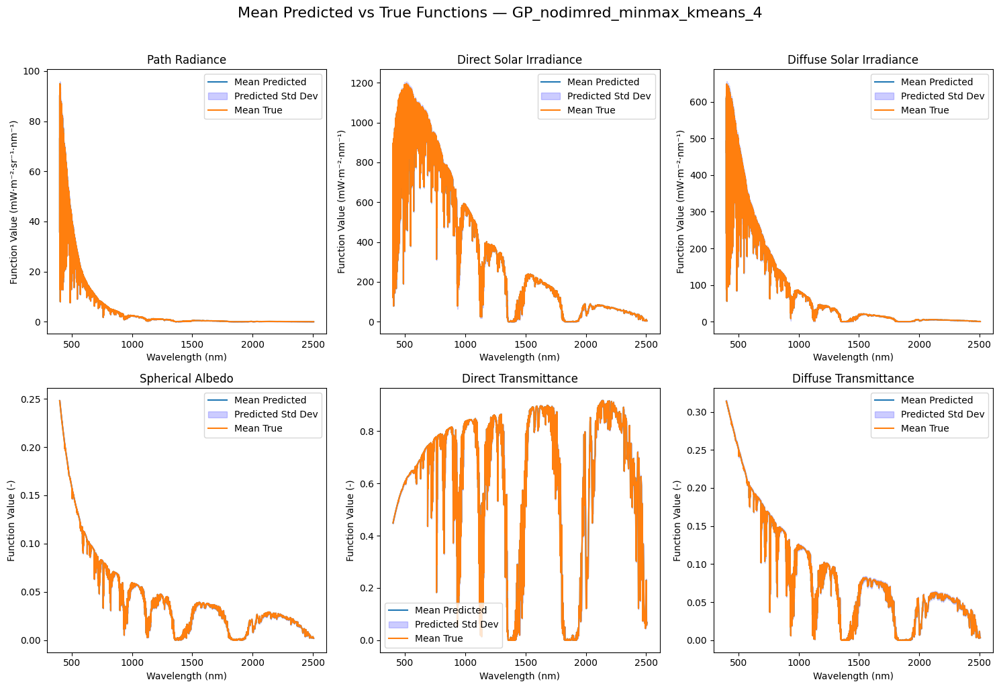

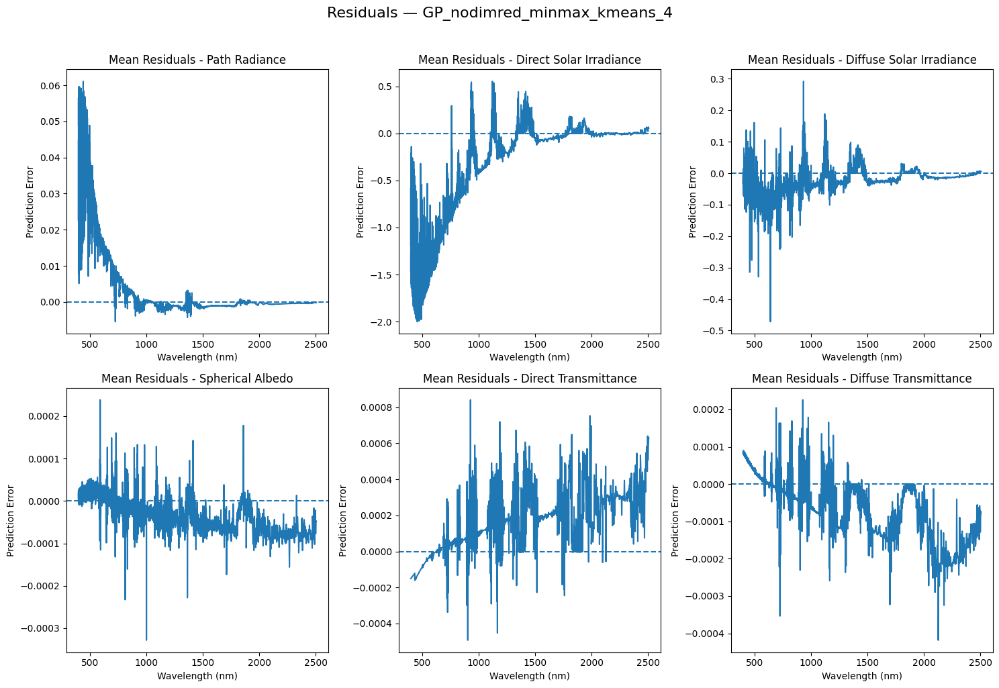

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 30 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.32s

Global Coverage Probability (2σ): 96.95%
------------------------------
Path Radiance   Coverage: 96.60%
Direct Solar Irradiance Coverage: 96.86%
Diffuse Solar Irradiance Coverage: 97.76%
Spherical Albedo Coverage: 97.65%
Direct Transmittance Coverage: 96.62%
Diffuse Transmittance Coverage: 96.19%

0.003752064755948833
0.5548173725047427
Testing MRE: 0.003752064755948833
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0053
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


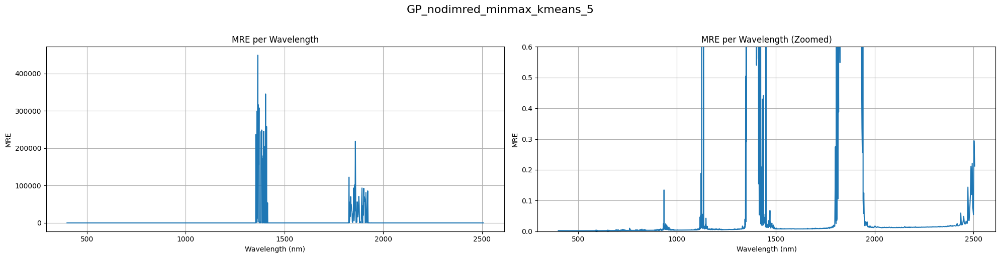

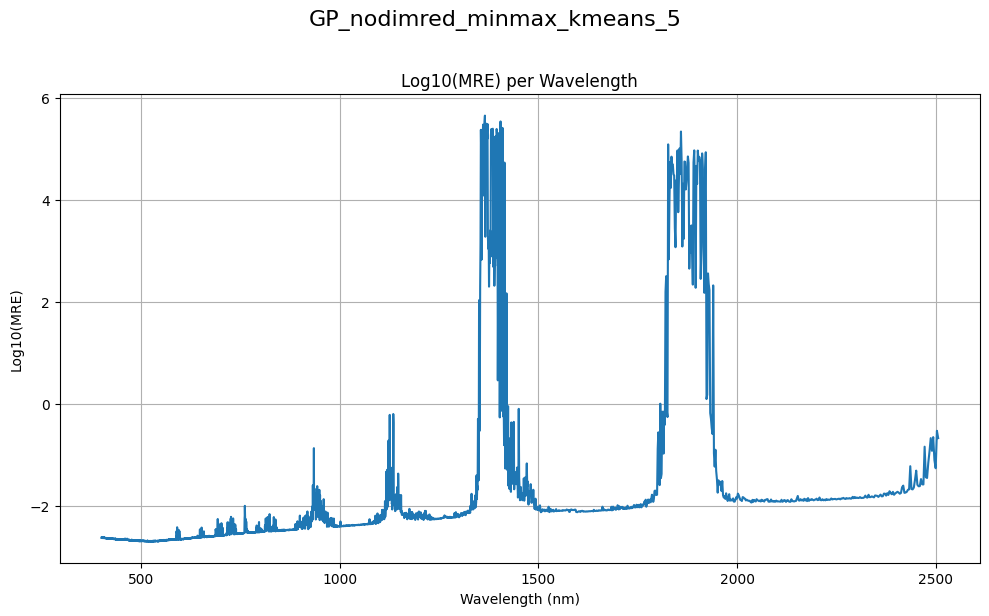

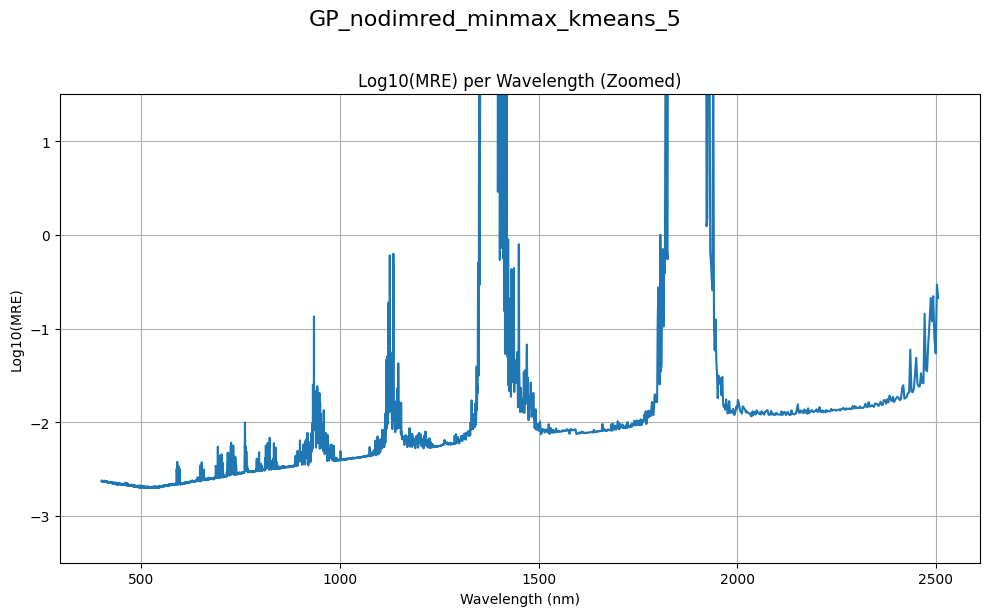

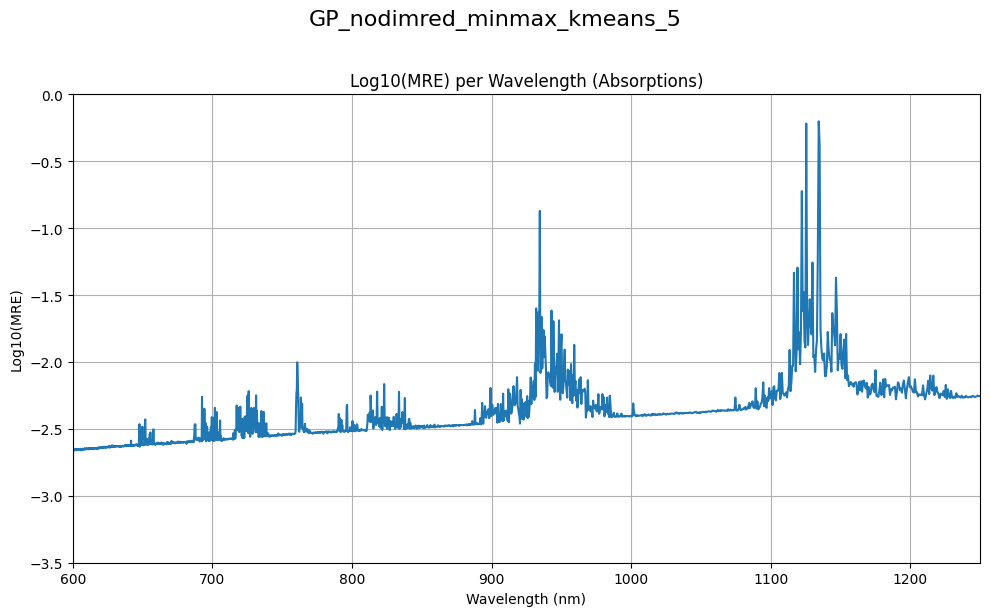

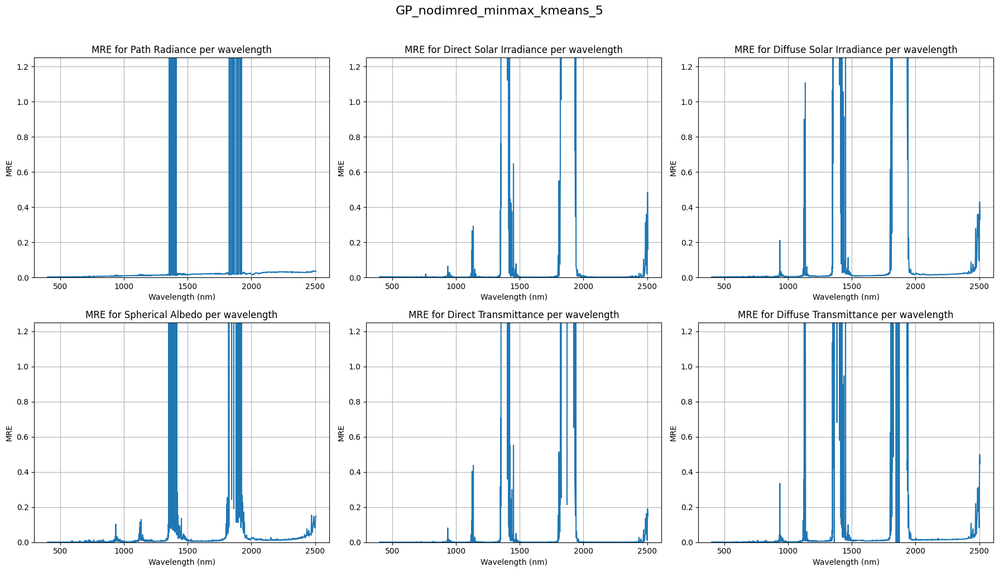

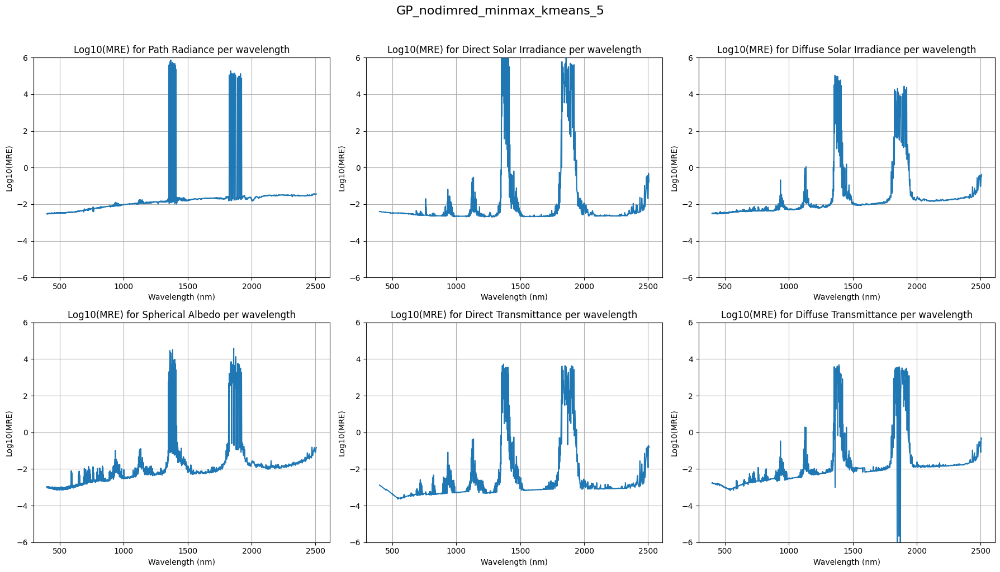

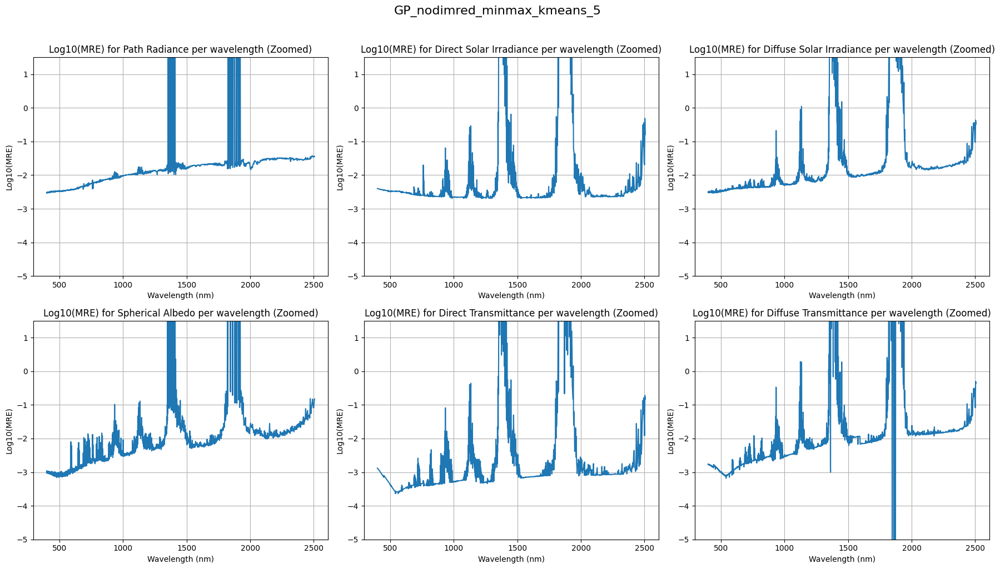

Testing MAE: 0.5548173725047427
Path Radiance MAE: 0.0755
Direct Solar Irradiance MAE: 2.3088
Diffuse Solar Irradiance MAE: 0.9437
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


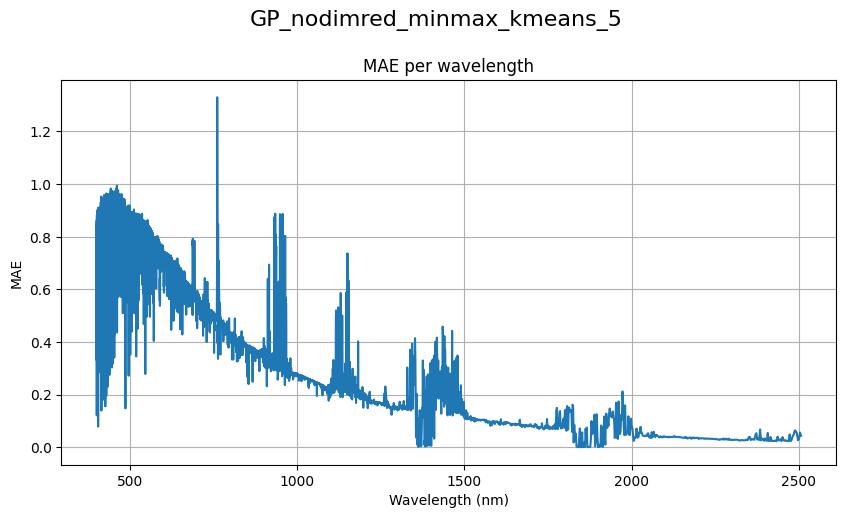

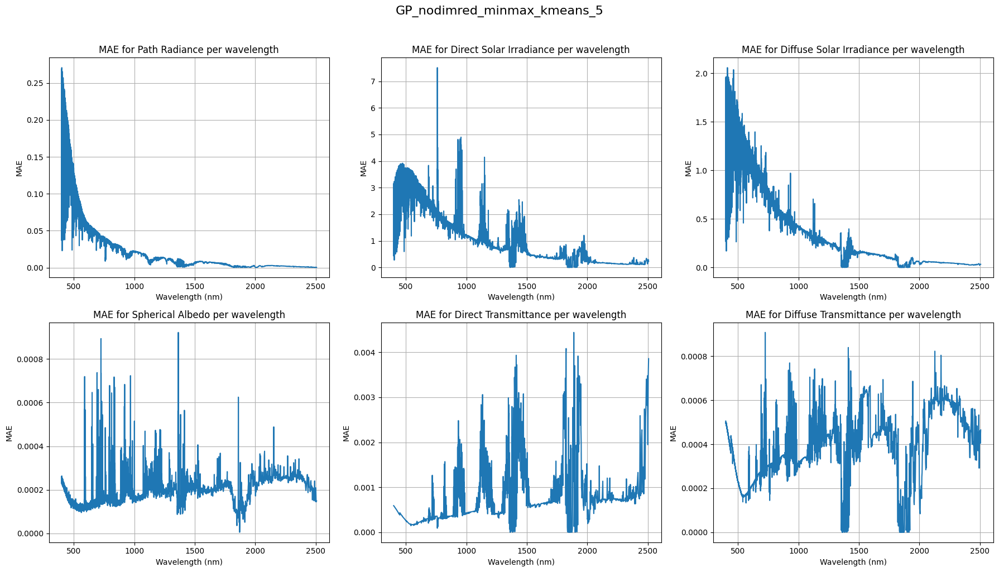

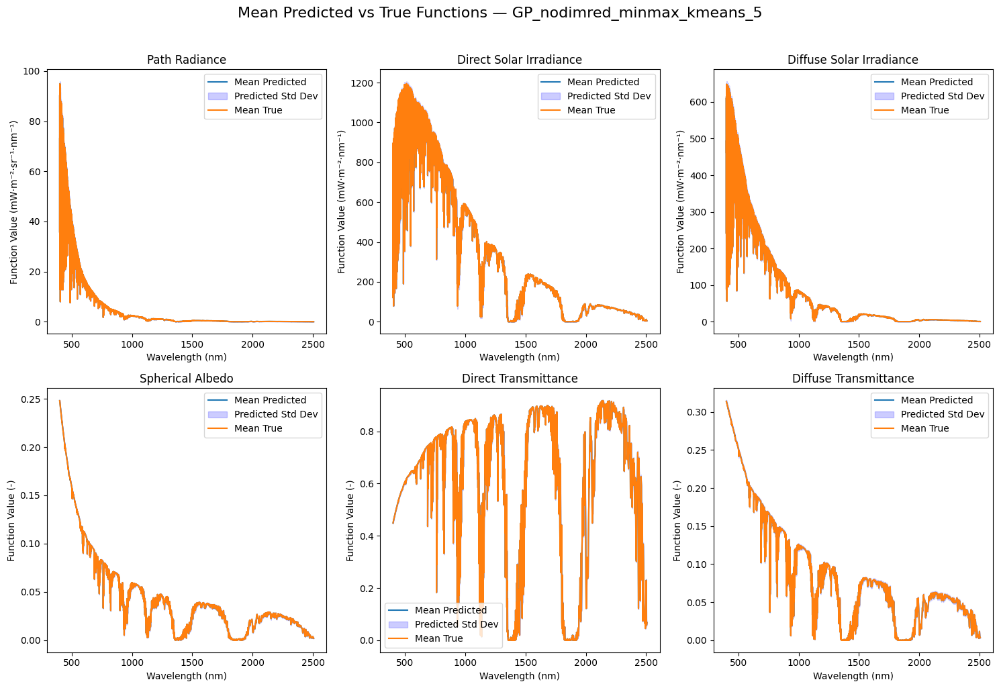

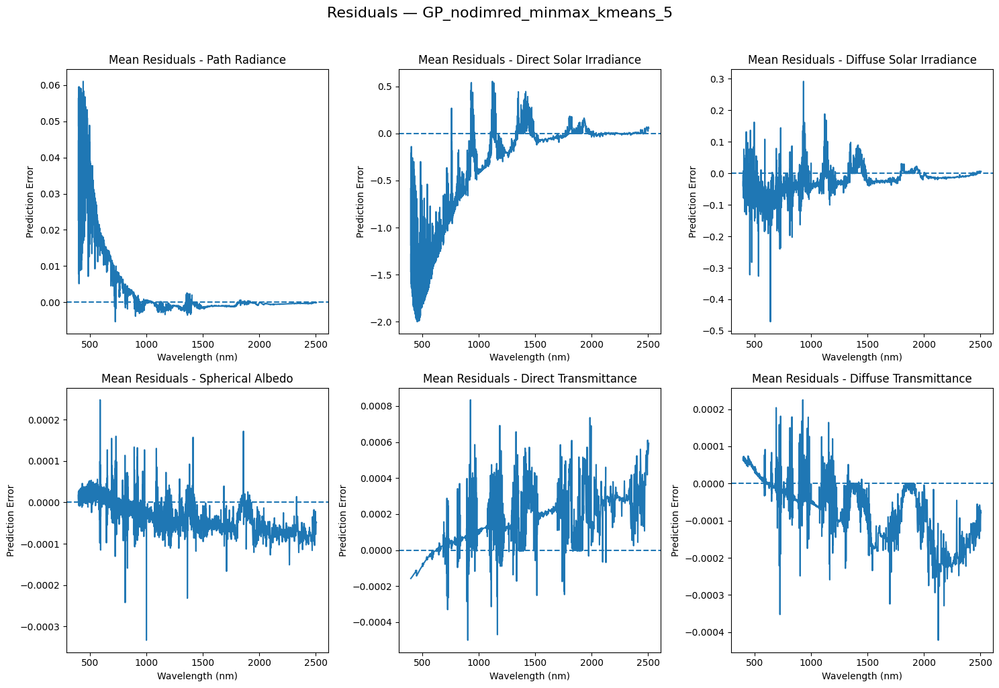

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 36 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.35s

Global Coverage Probability (2σ): 97.29%
------------------------------
Path Radiance   Coverage: 96.32%
Direct Solar Irradiance Coverage: 97.14%
Diffuse Solar Irradiance Coverage: 97.81%
Spherical Albedo Coverage: 97.89%
Direct Transmittance Coverage: 97.00%
Diffuse Transmittance Coverage: 97.59%

0.0037625591484906603
0.5548681452116986
Testing MRE: 0.0037625591484906603
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0033


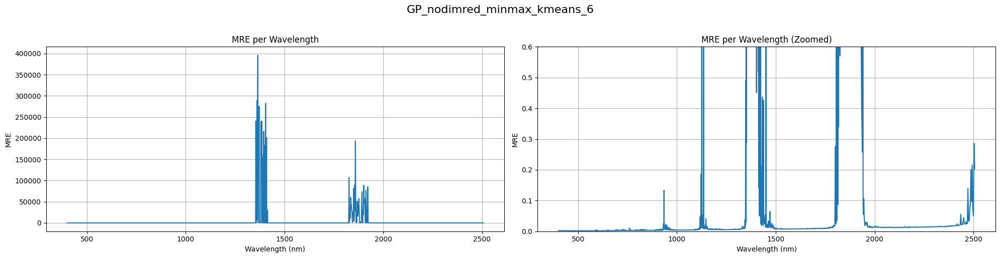

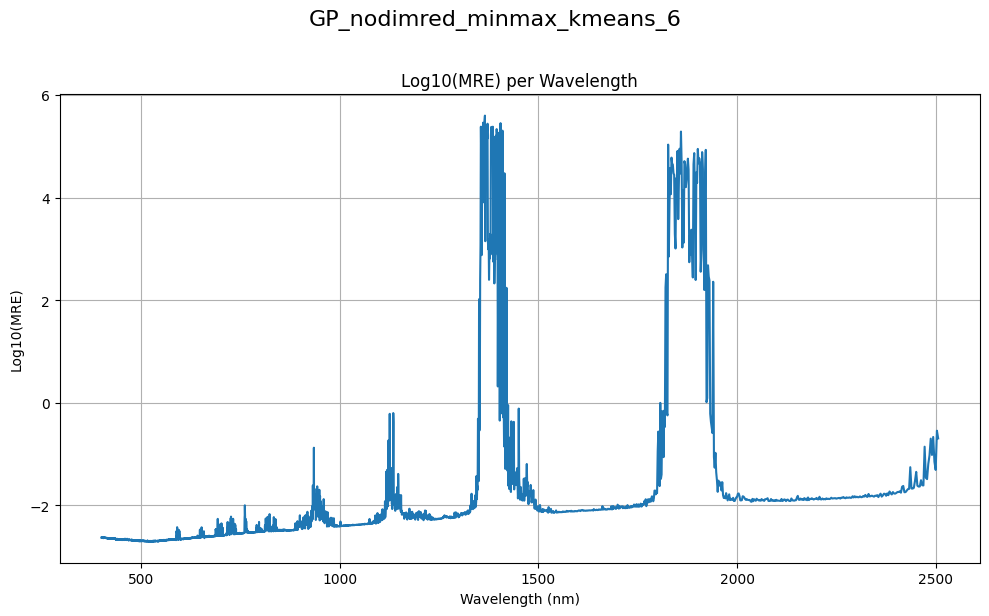

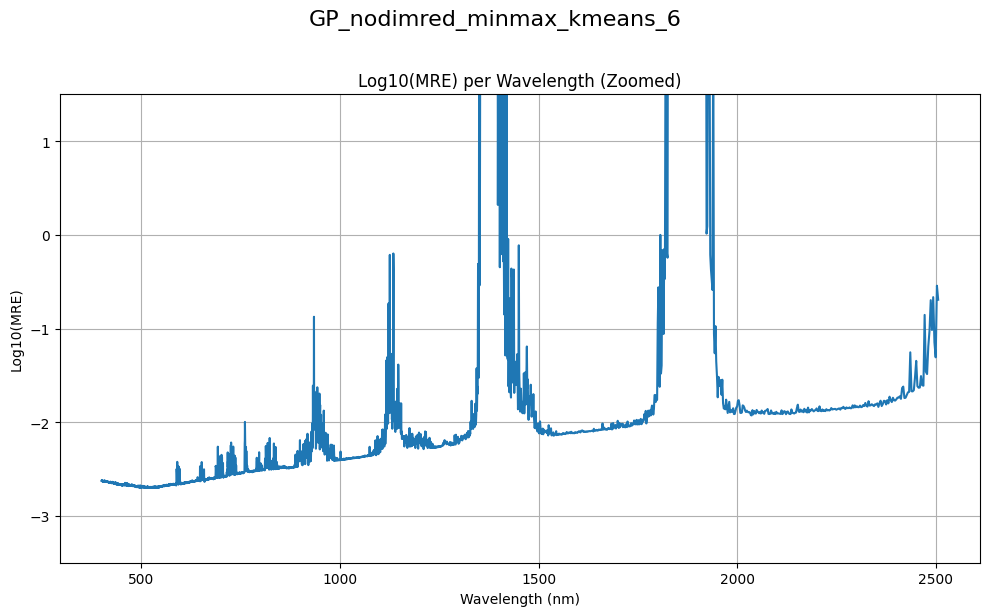

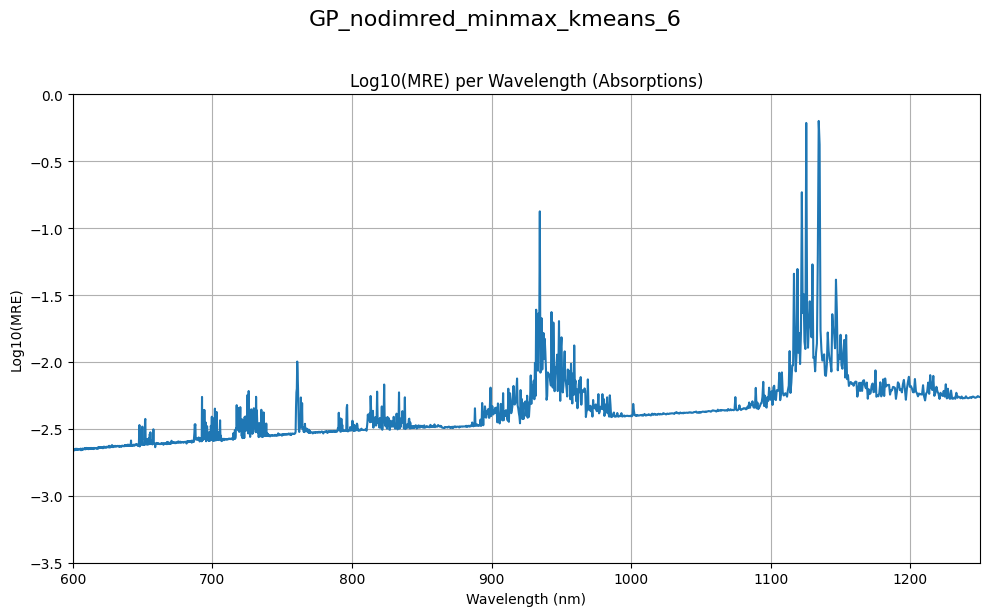

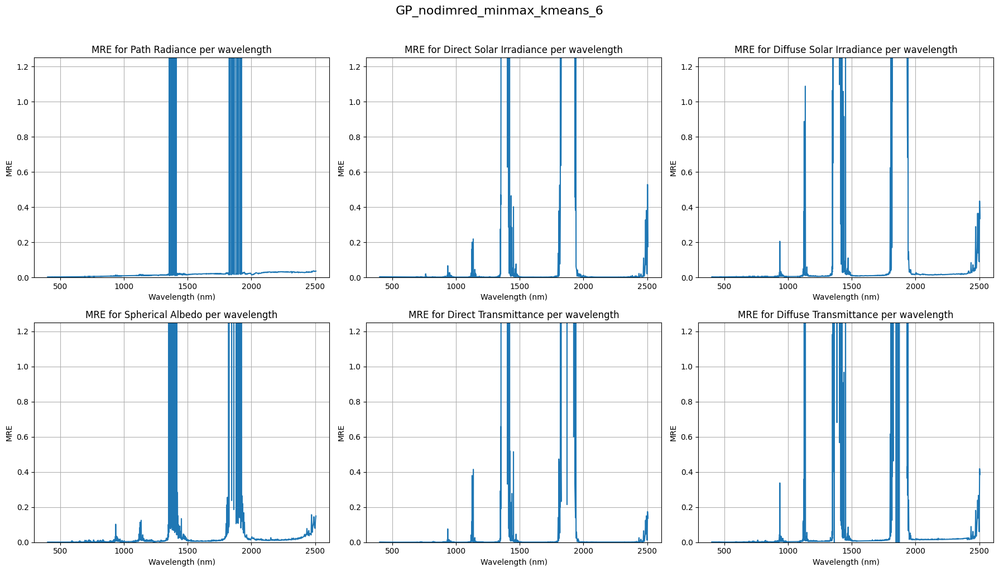

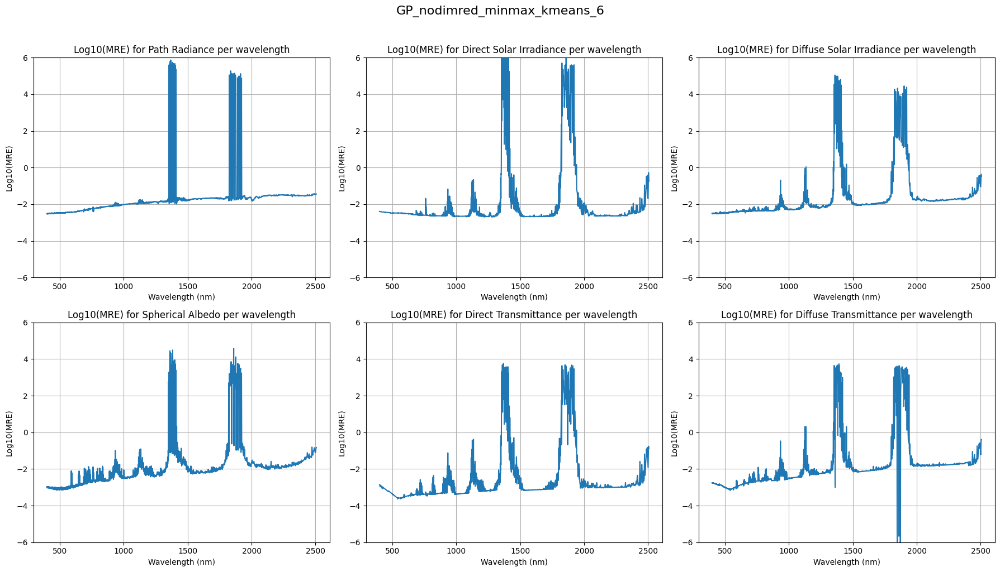

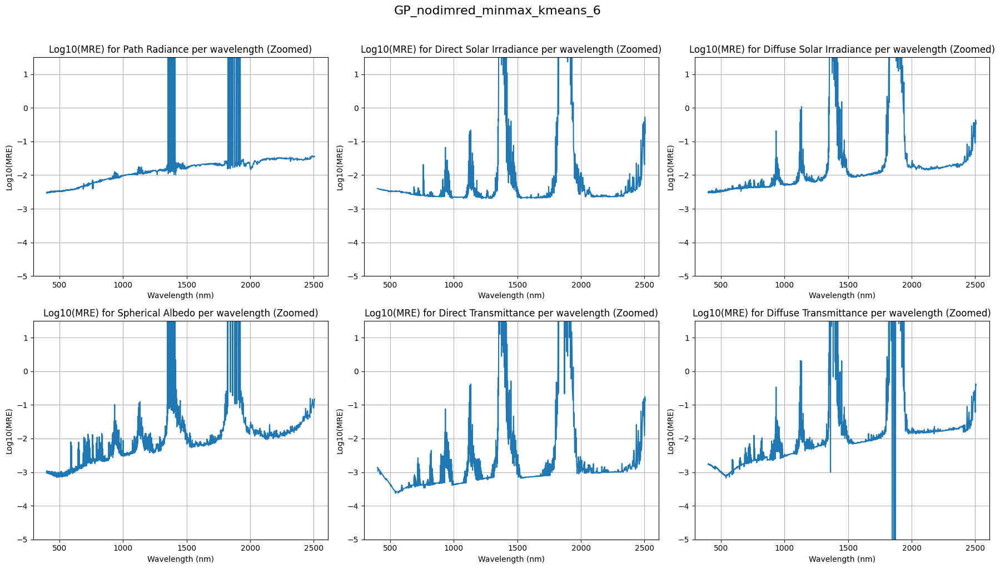

Testing MAE: 0.5548681452116986
Path Radiance MAE: 0.0756
Direct Solar Irradiance MAE: 2.3097
Diffuse Solar Irradiance MAE: 0.9430
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


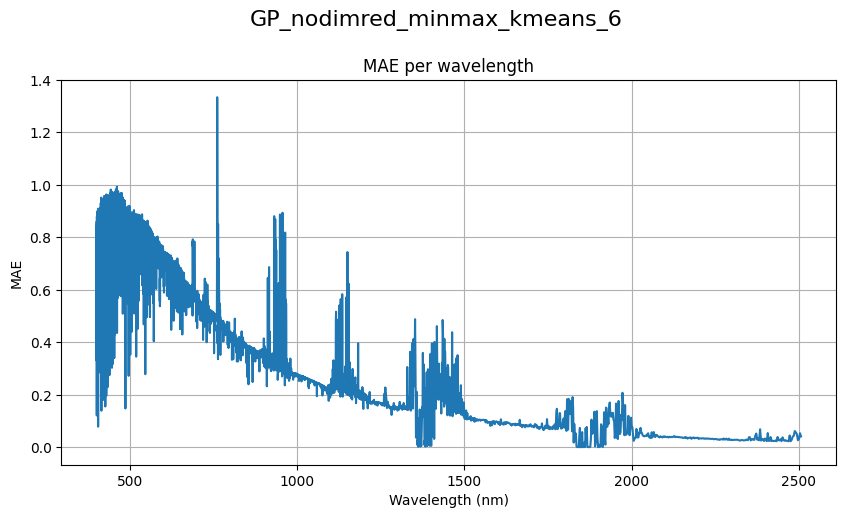

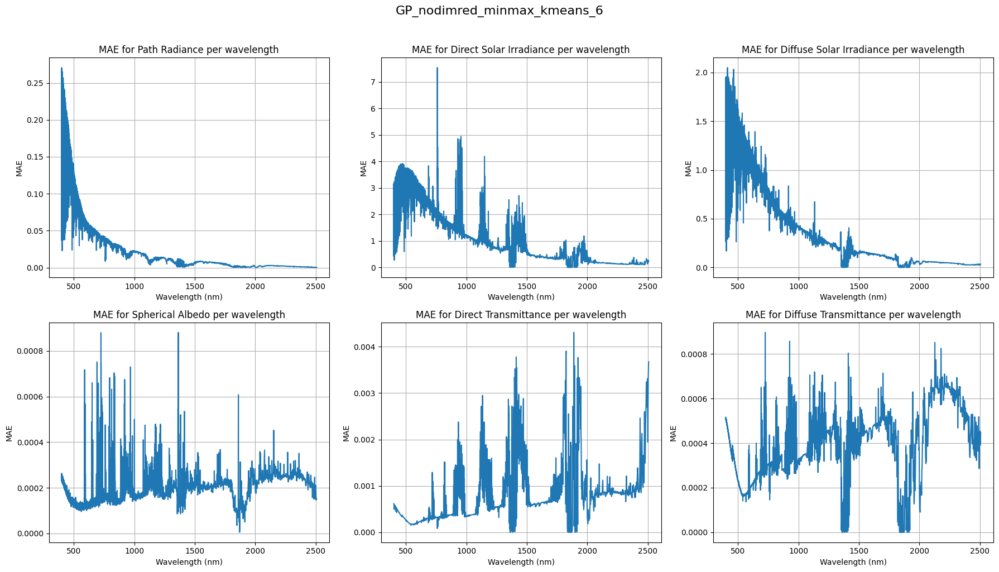

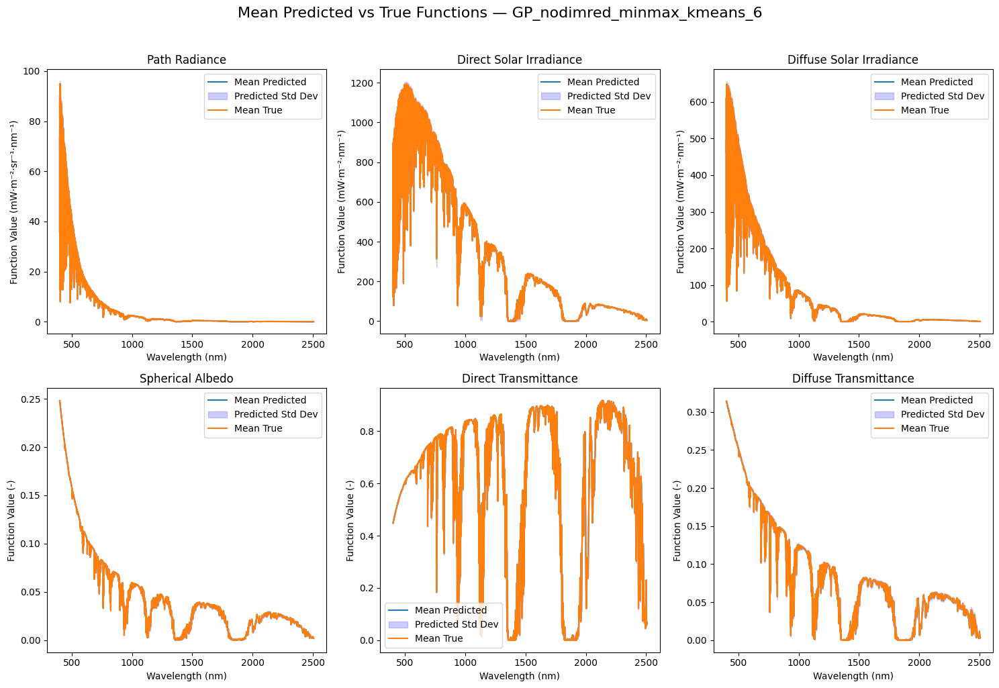

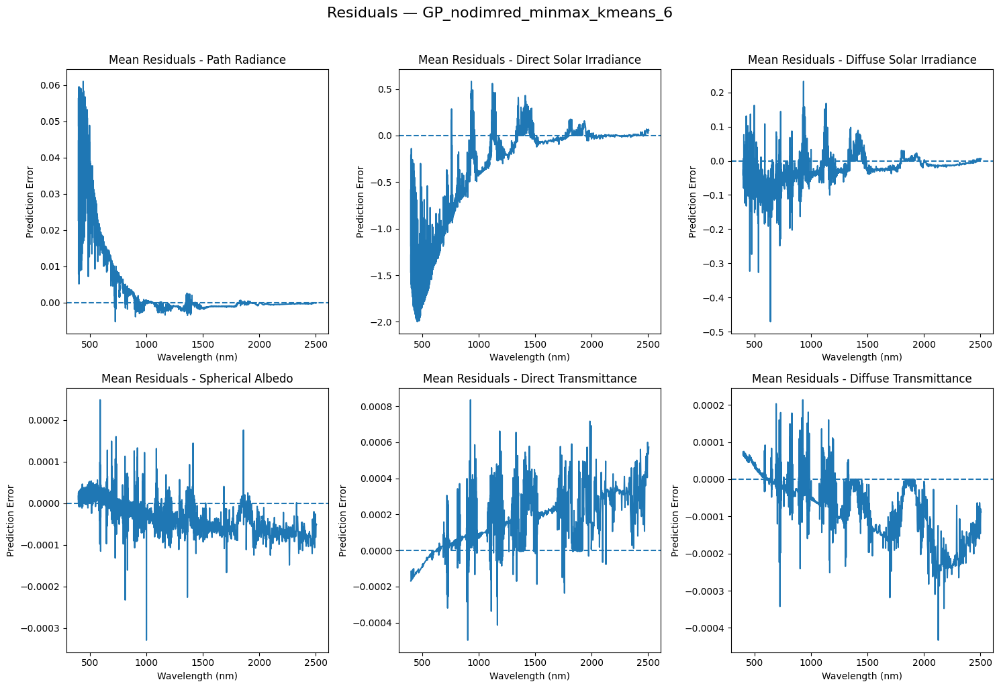

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 42 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.42s

Global Coverage Probability (2σ): 97.62%
------------------------------
Path Radiance   Coverage: 96.23%
Direct Solar Irradiance Coverage: 97.12%
Diffuse Solar Irradiance Coverage: 97.77%
Spherical Albedo Coverage: 97.91%
Direct Transmittance Coverage: 99.08%
Diffuse Transmittance Coverage: 97.64%

0.0037613105625884423
0.5549518643623723
Testing MRE: 0.0037613105625884423
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0033


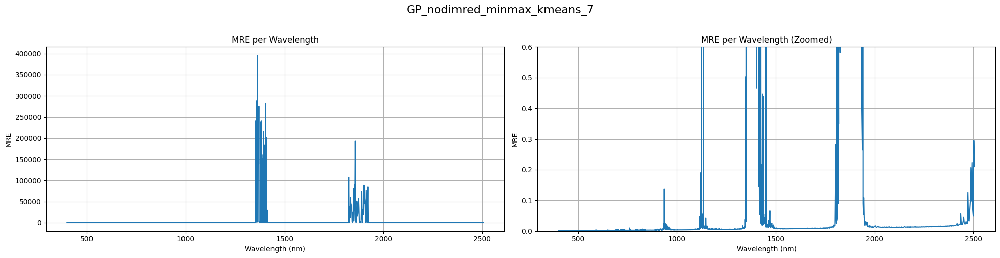

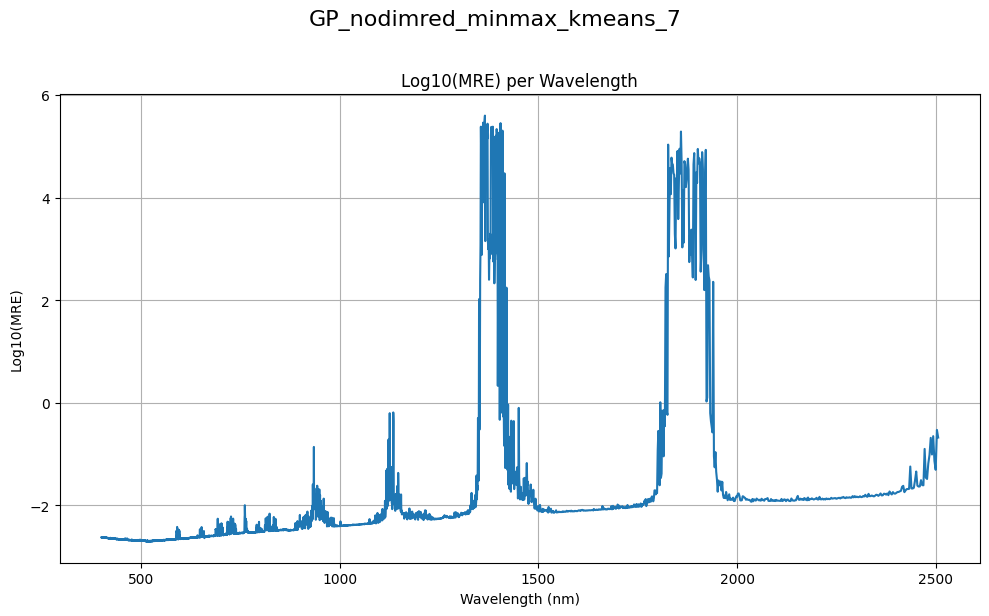

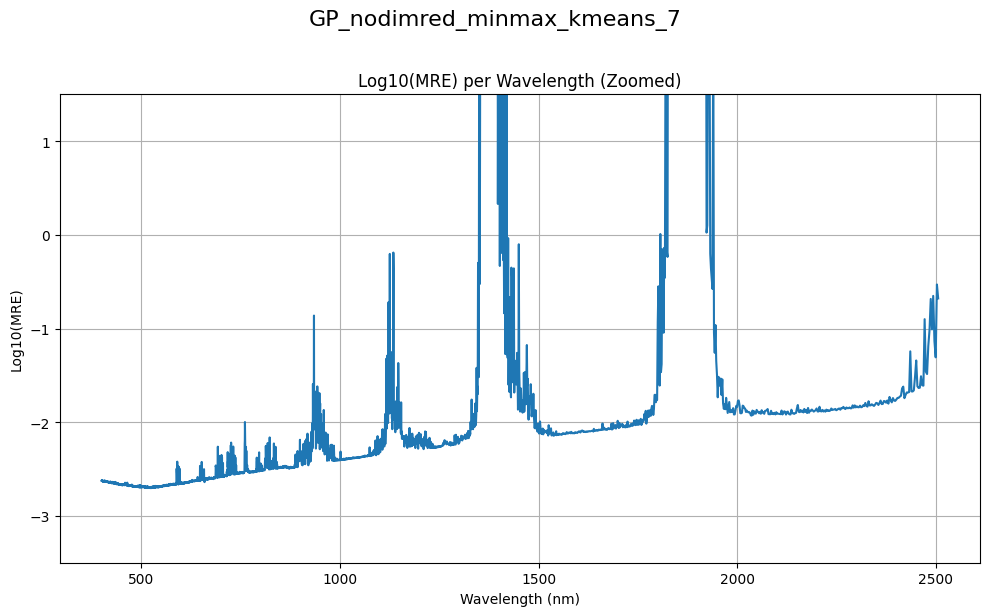

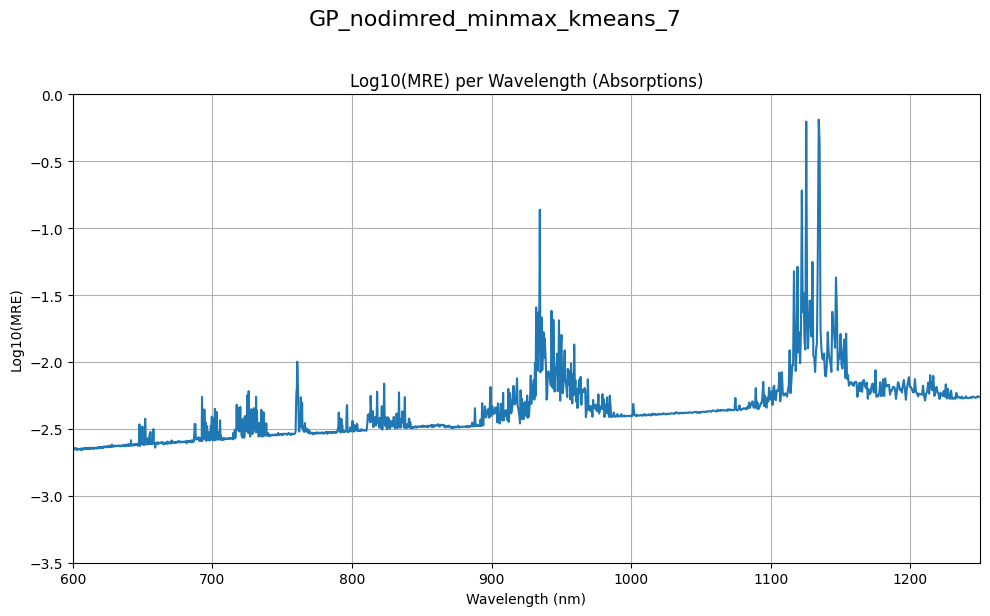

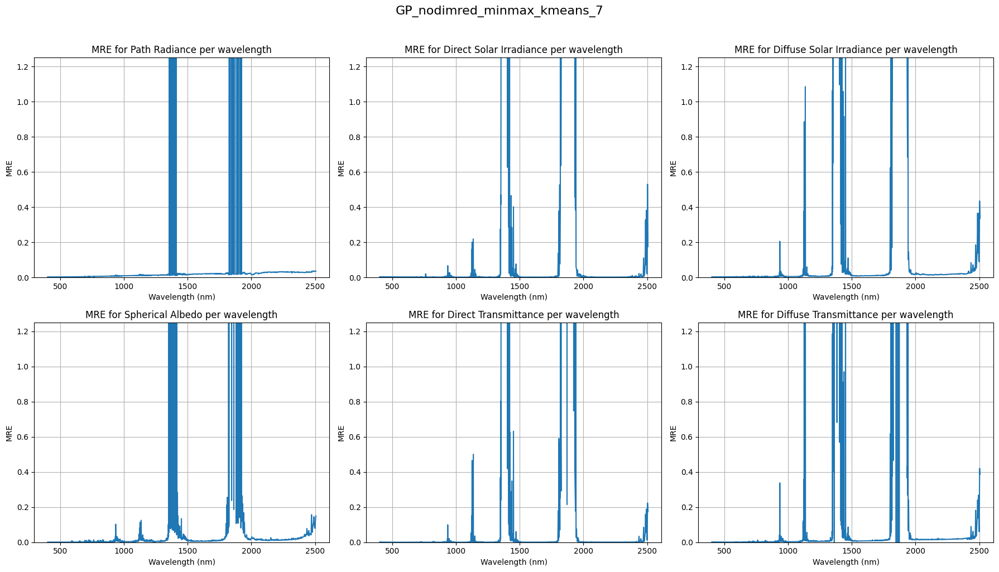

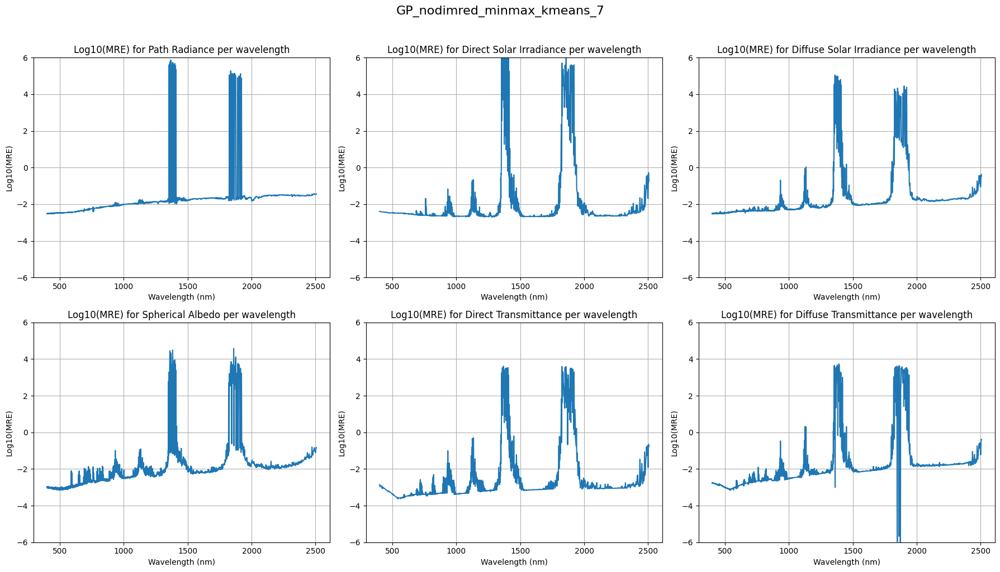

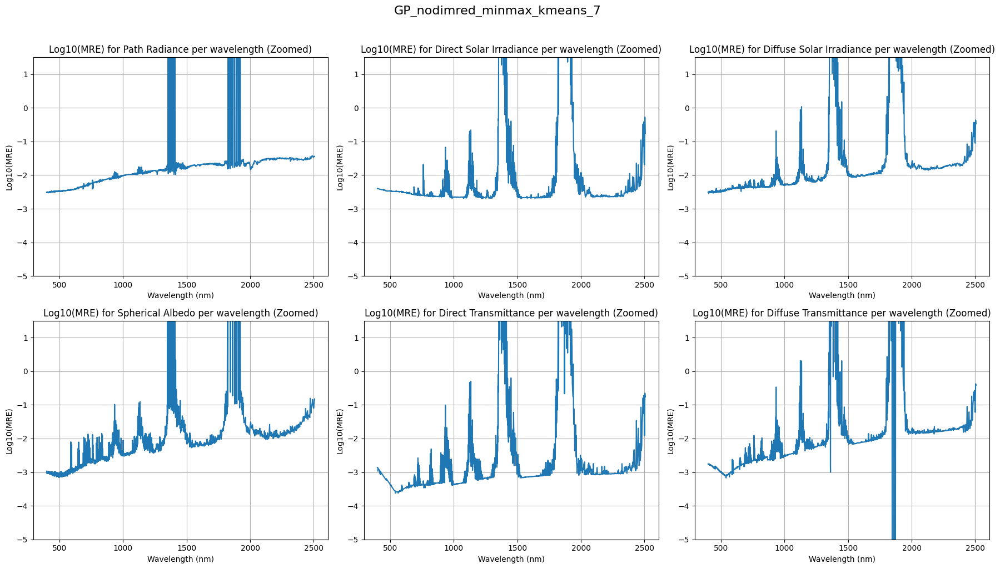

Testing MAE: 0.5549518643623723
Path Radiance MAE: 0.0757
Direct Solar Irradiance MAE: 2.3080
Diffuse Solar Irradiance MAE: 0.9450
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


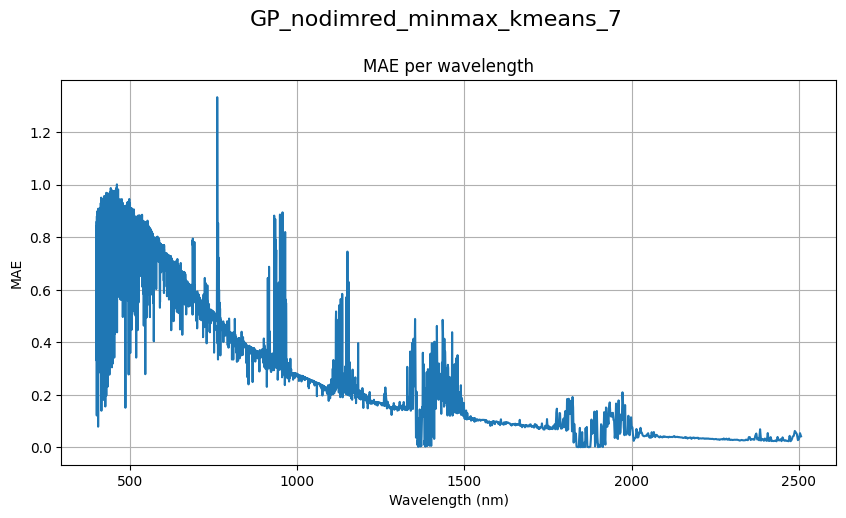

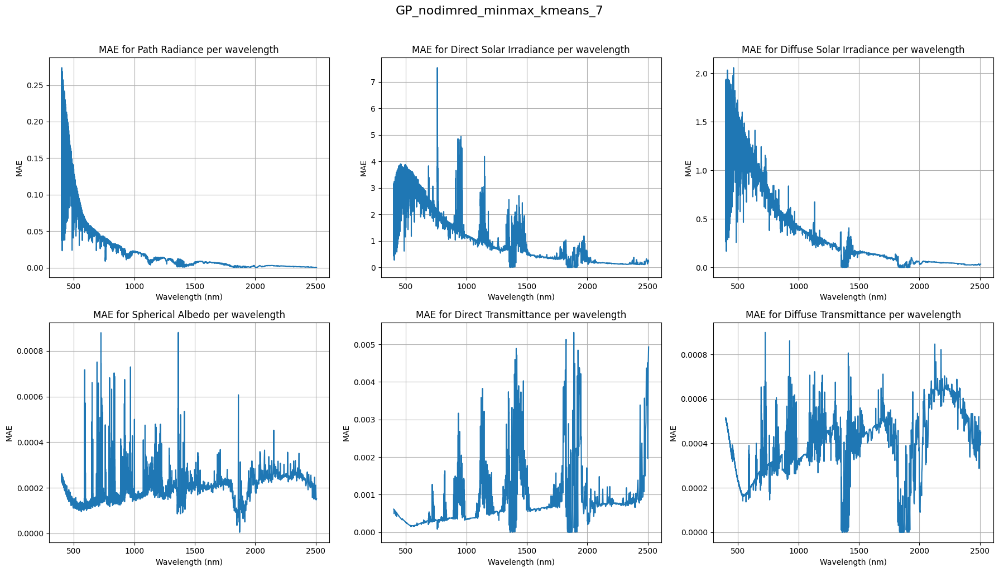

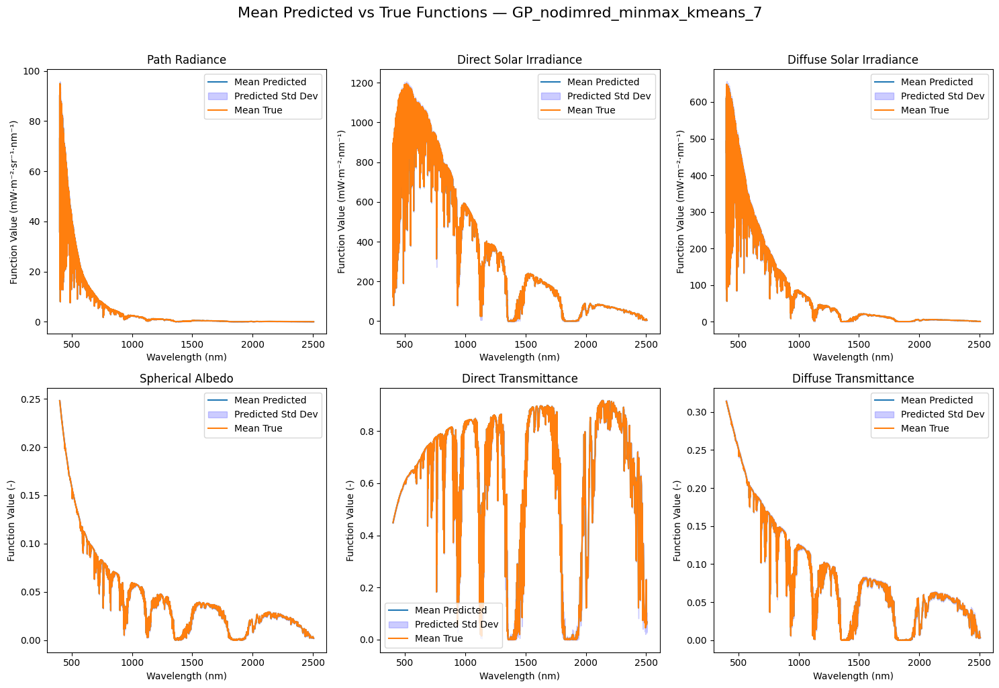

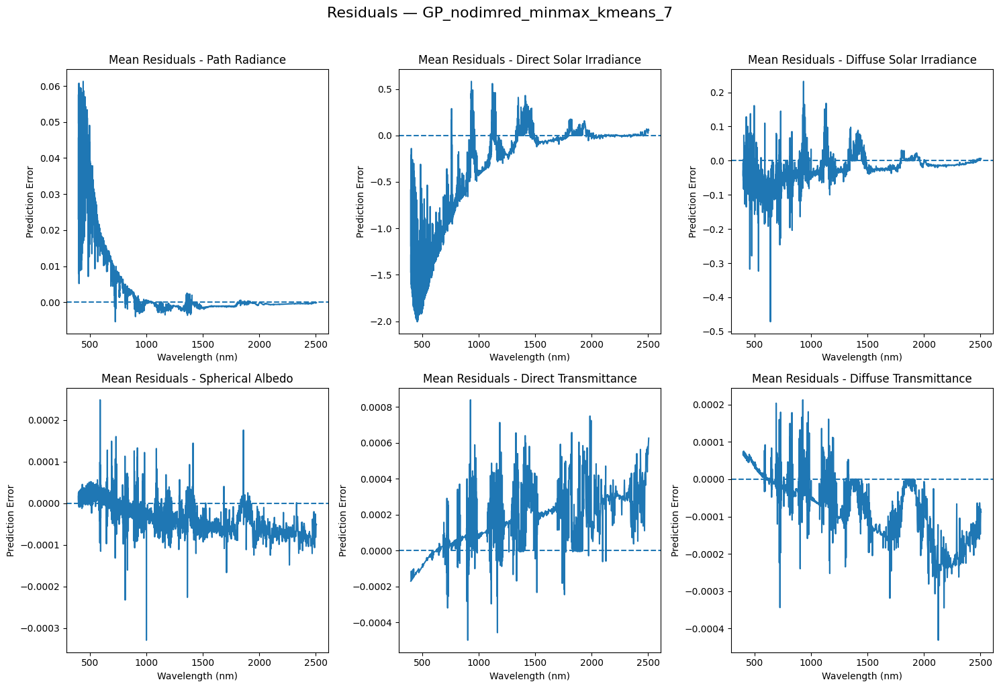

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 48 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.43s

Global Coverage Probability (2σ): 97.83%
------------------------------
Path Radiance   Coverage: 96.44%
Direct Solar Irradiance Coverage: 97.01%
Diffuse Solar Irradiance Coverage: 97.77%
Spherical Albedo Coverage: 98.10%
Direct Transmittance Coverage: 99.14%
Diffuse Transmittance Coverage: 98.54%

0.0037523687230762975
0.5558523450854266
Testing MRE: 0.0037523687230762975
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


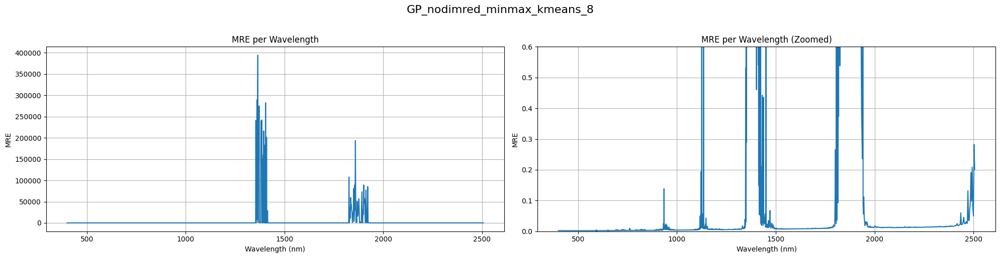

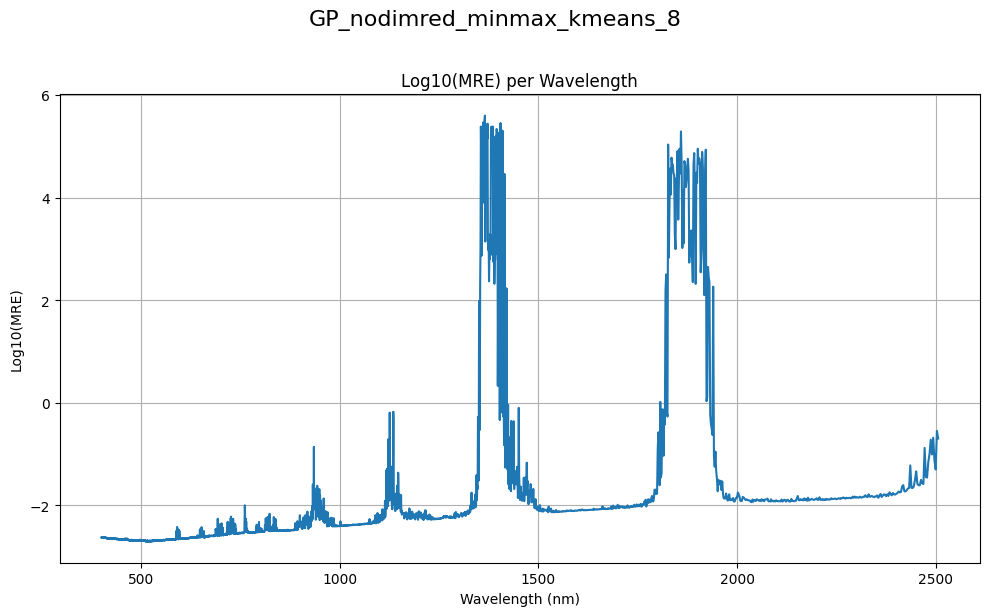

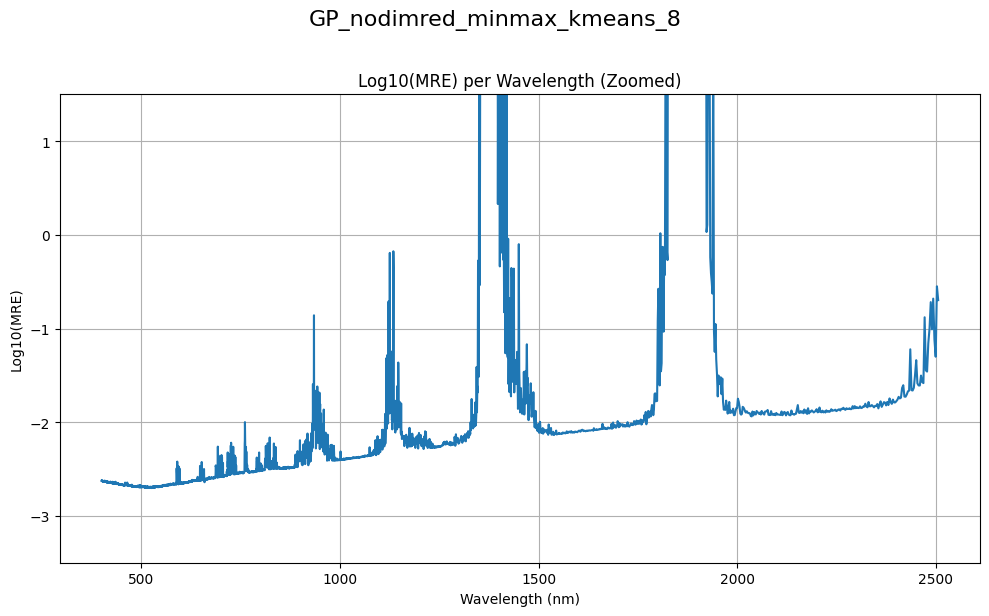

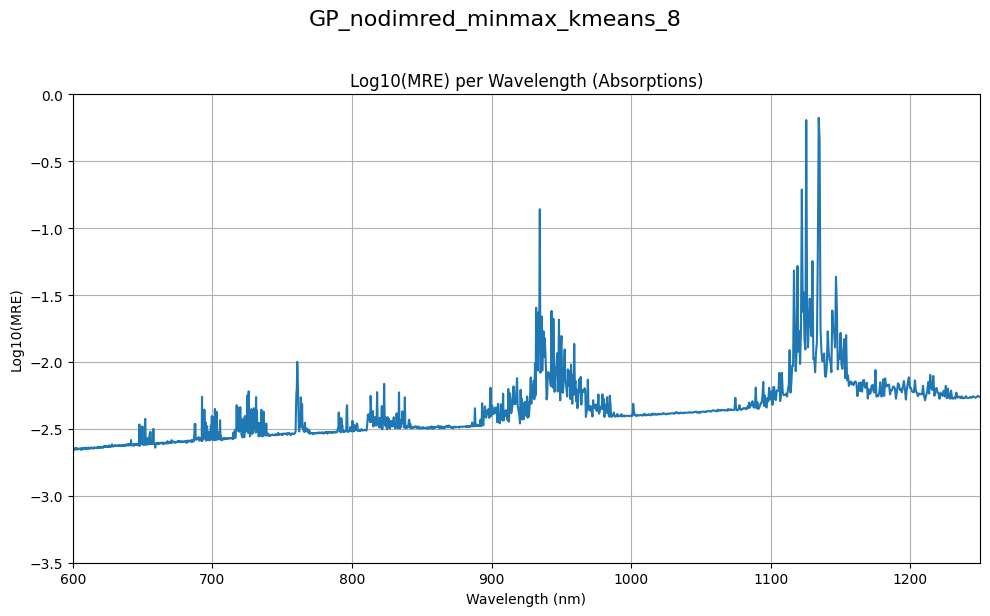

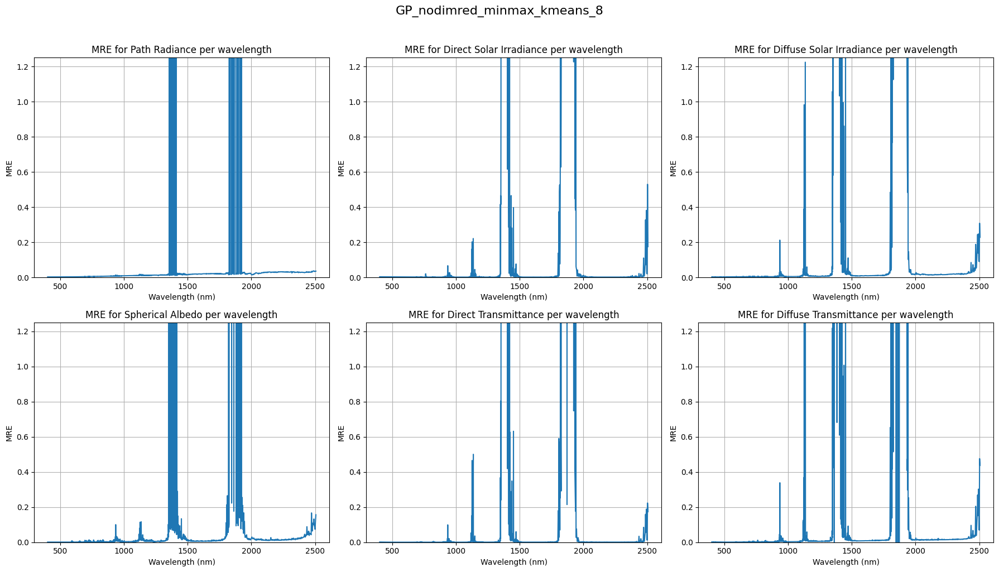

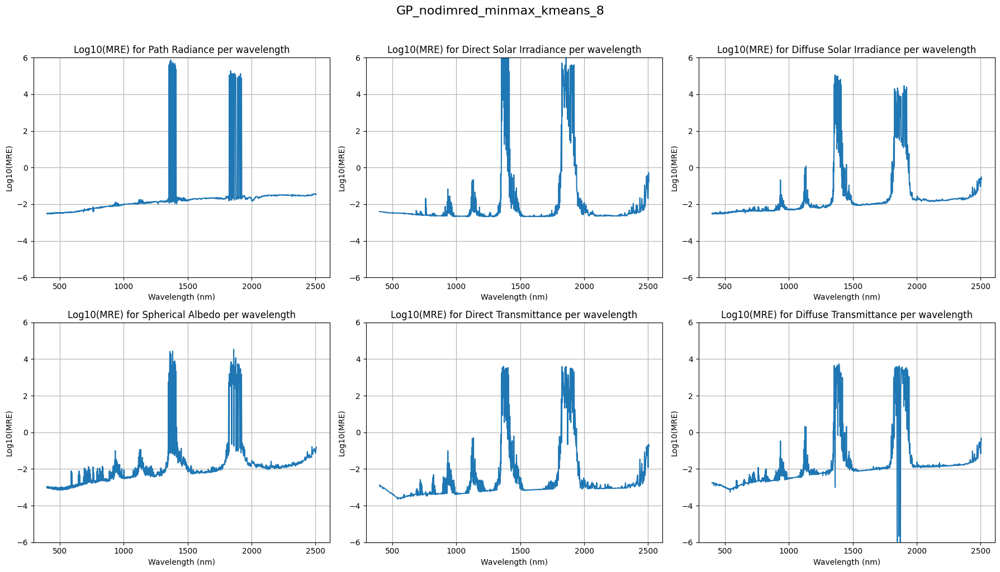

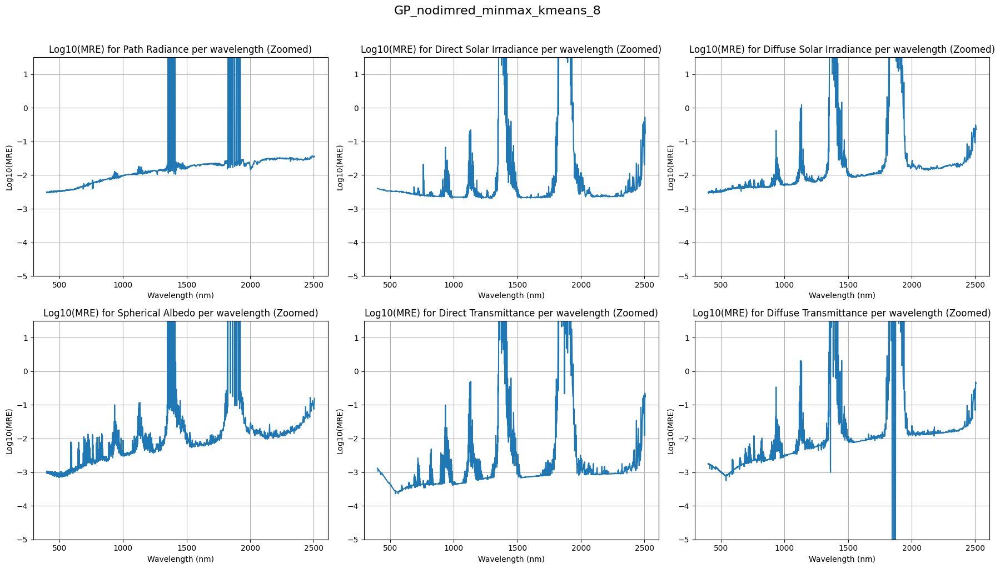

Testing MAE: 0.5558523450854266
Path Radiance MAE: 0.0759
Direct Solar Irradiance MAE: 2.3135
Diffuse Solar Irradiance MAE: 0.9448
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


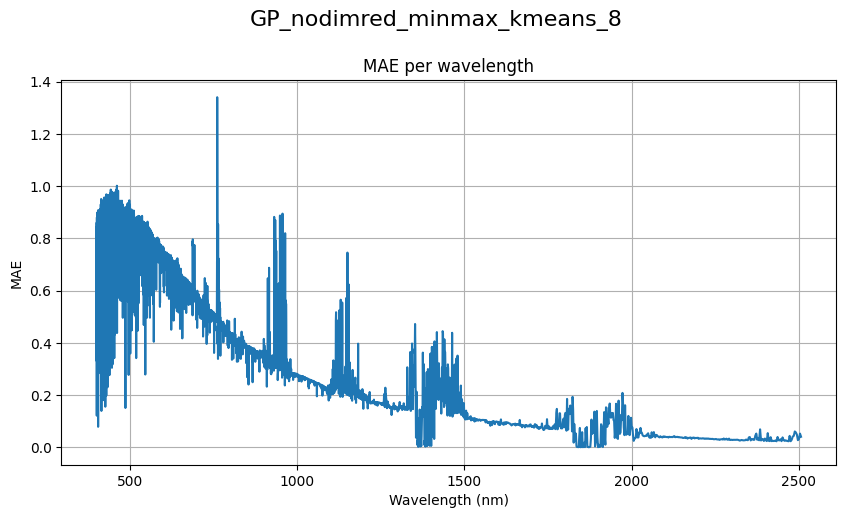

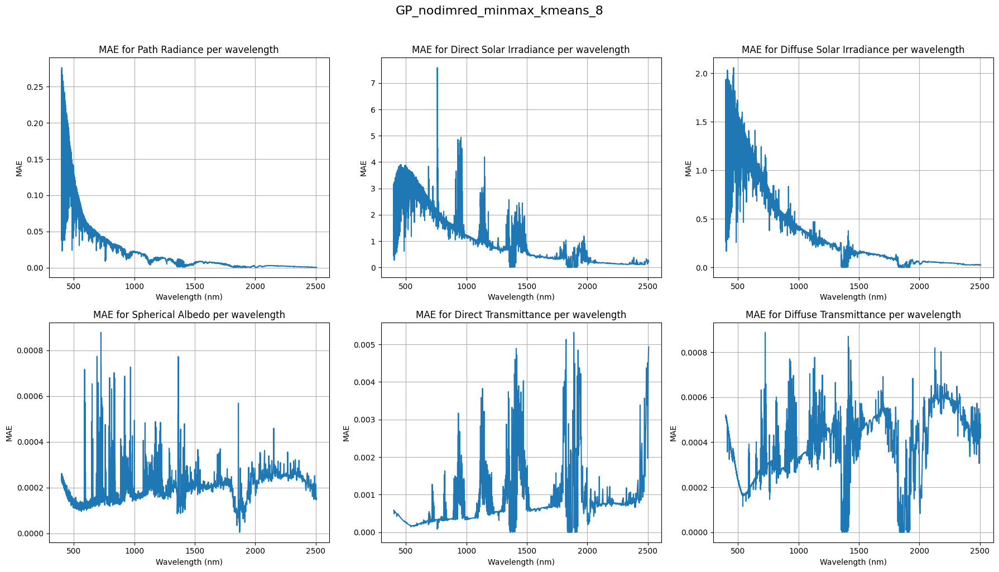

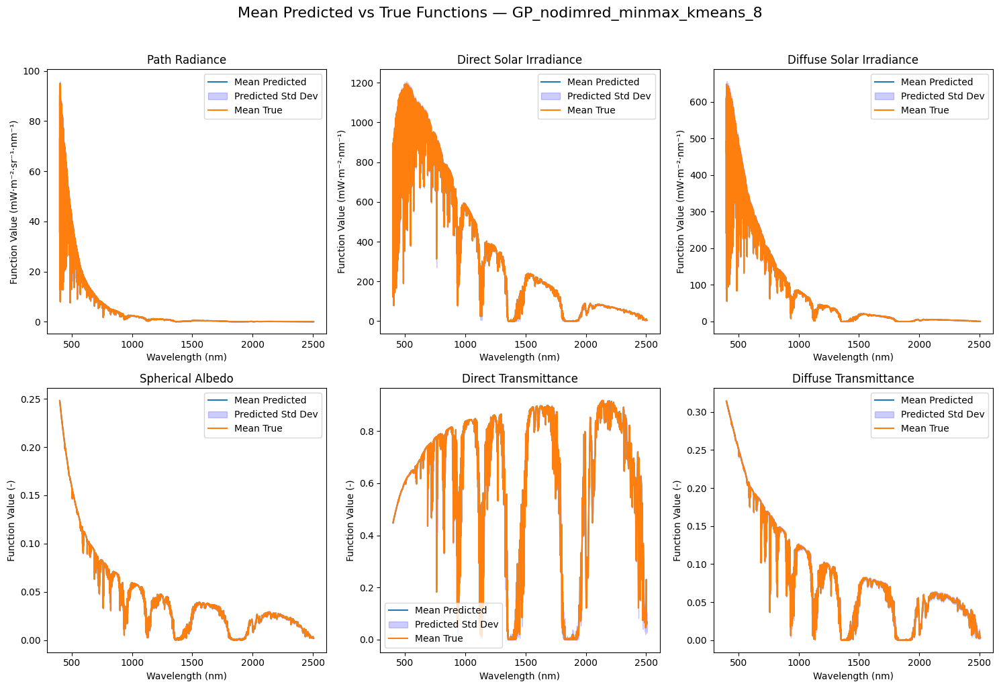

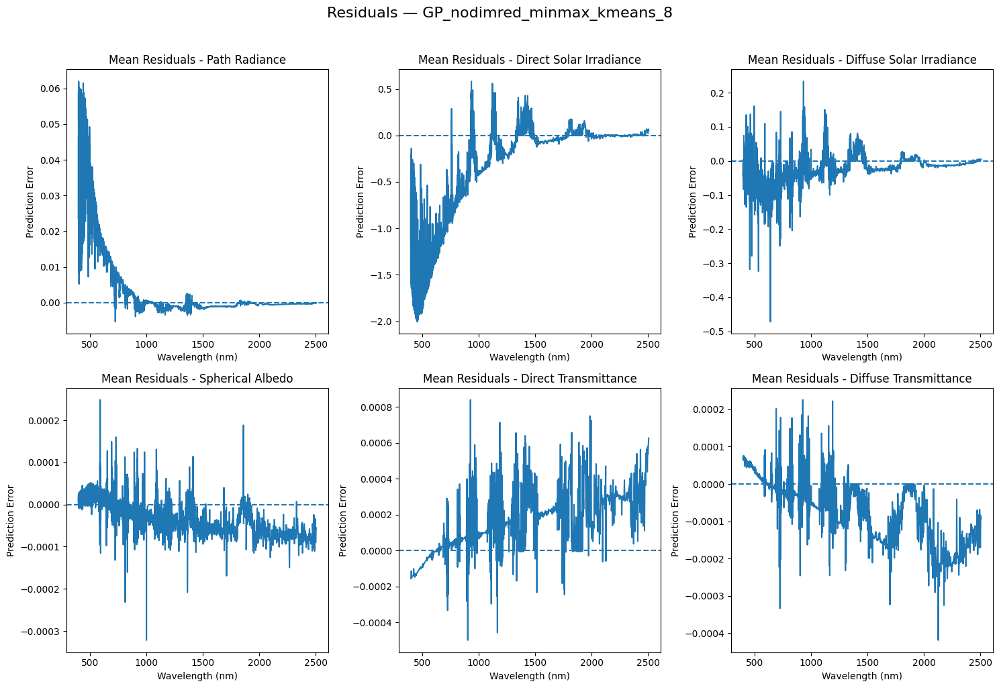

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 54 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.47s

Global Coverage Probability (2σ): 97.86%
------------------------------
Path Radiance   Coverage: 96.45%
Direct Solar Irradiance Coverage: 97.01%
Diffuse Solar Irradiance Coverage: 97.80%
Spherical Albedo Coverage: 98.12%
Direct Transmittance Coverage: 99.17%
Diffuse Transmittance Coverage: 98.62%

0.0037517976599009246
0.5559139564812874
Testing MRE: 0.0037517976599009246
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


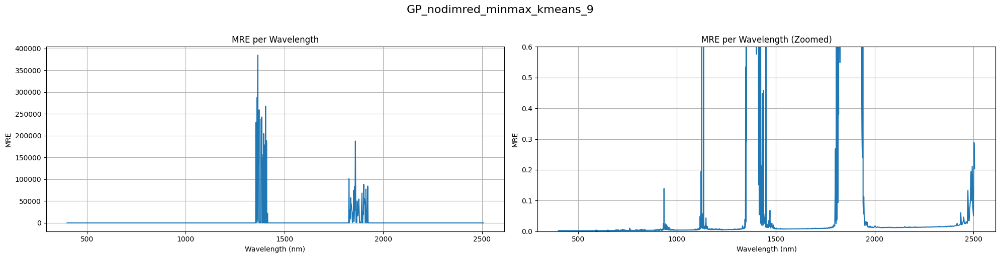

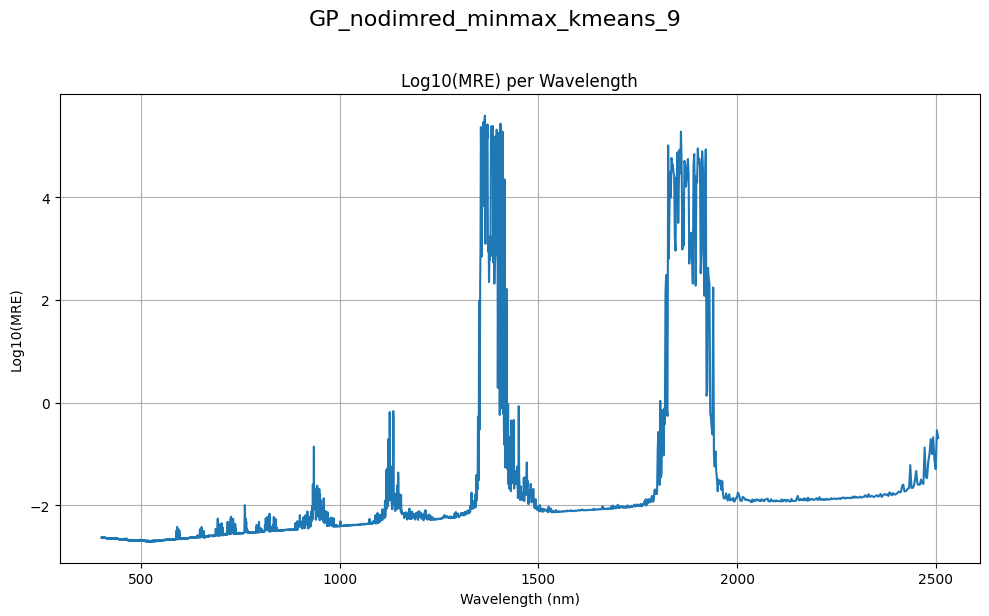

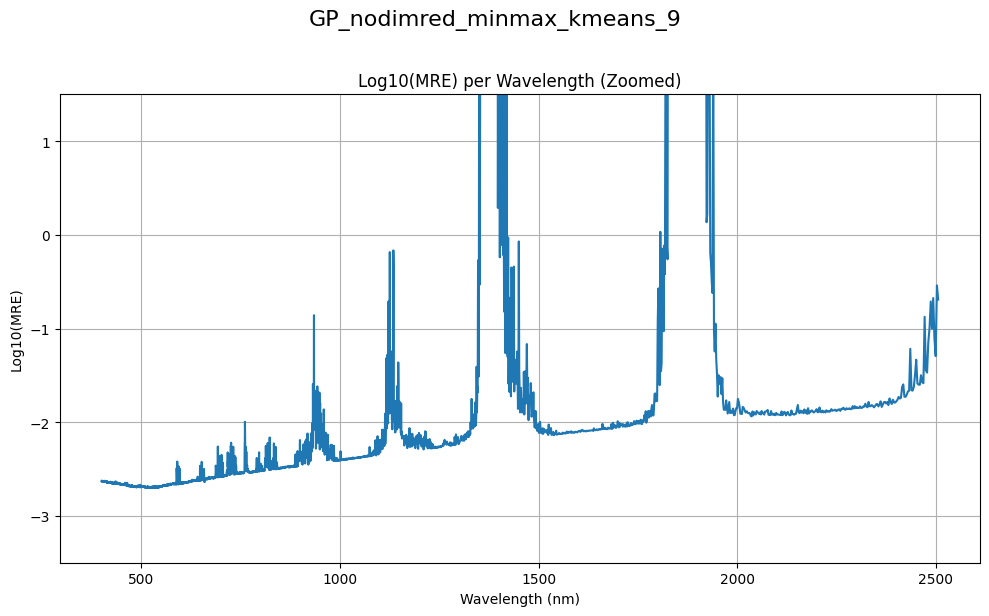

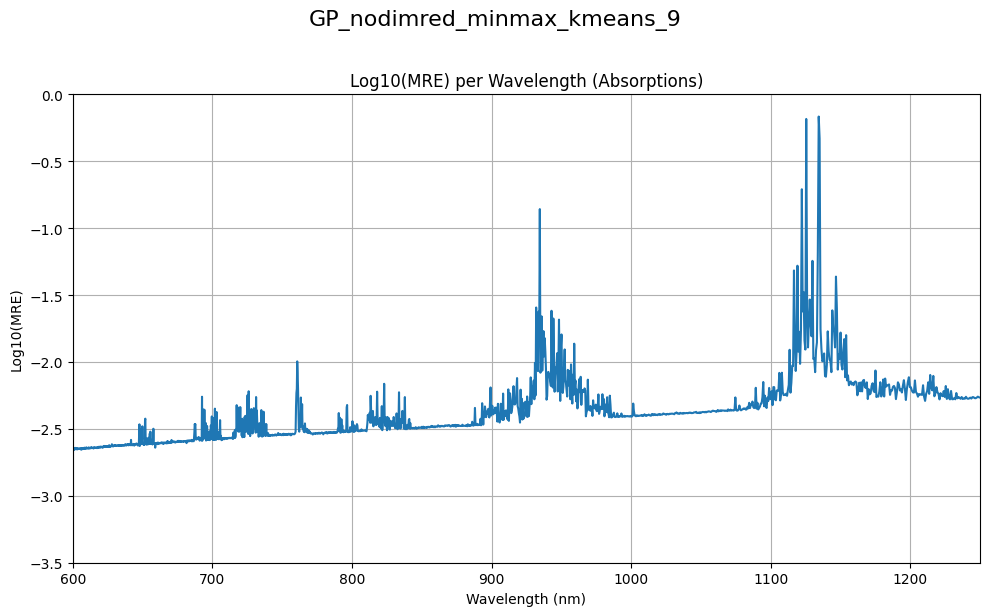

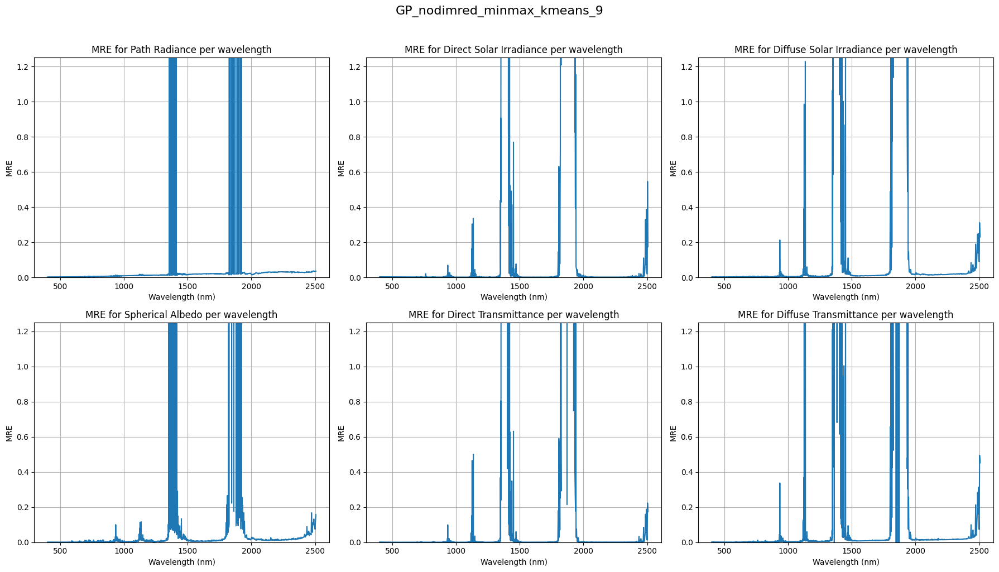

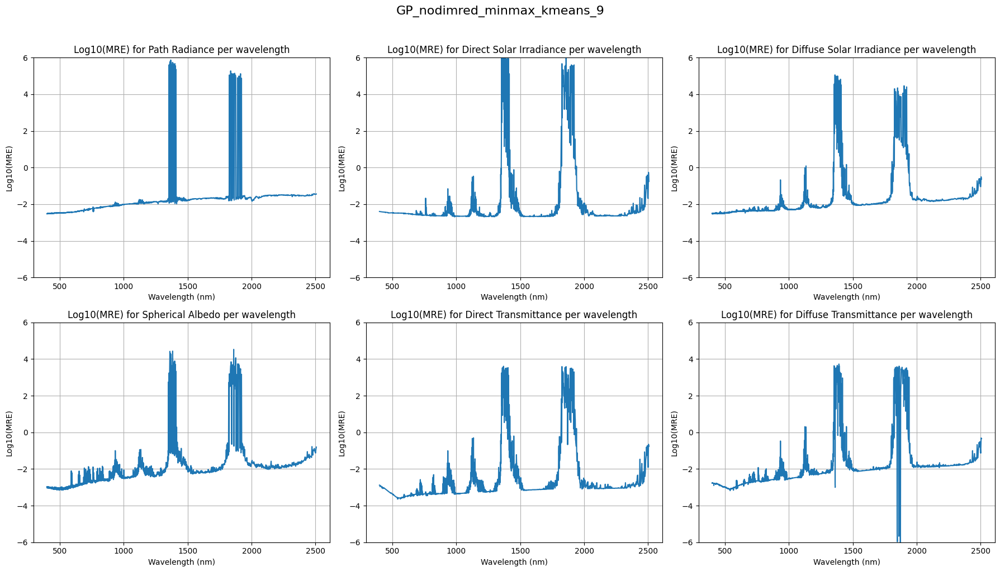

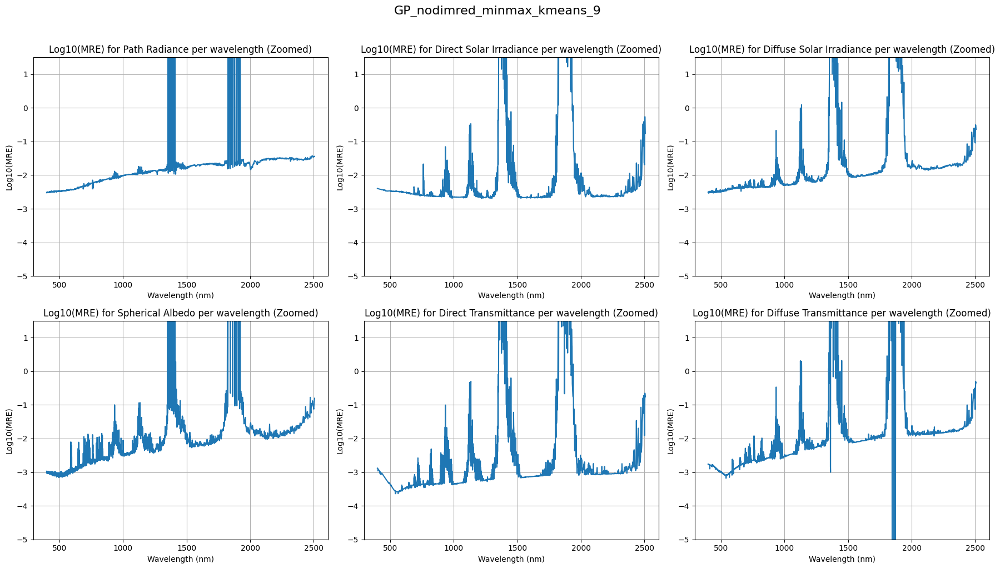

Testing MAE: 0.5559139564812874
Path Radiance MAE: 0.0758
Direct Solar Irradiance MAE: 2.3134
Diffuse Solar Irradiance MAE: 0.9454
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


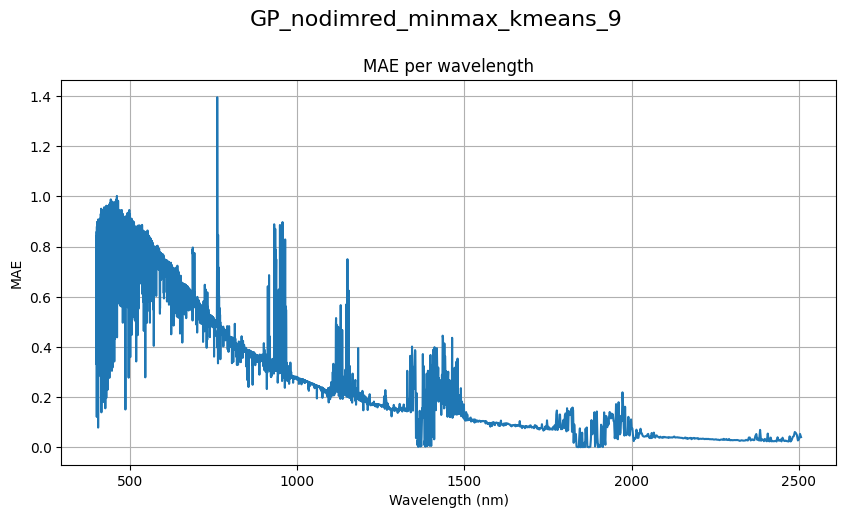

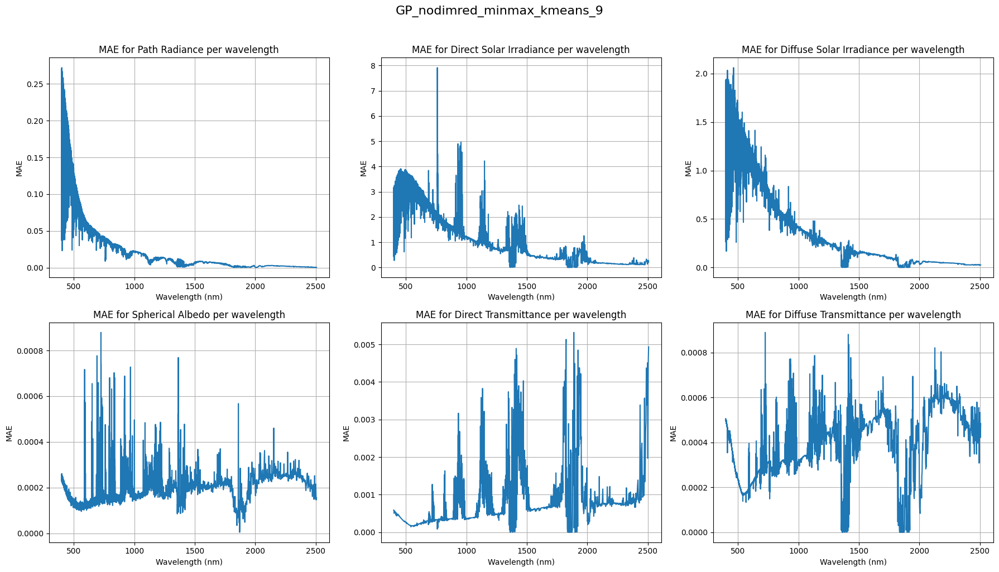

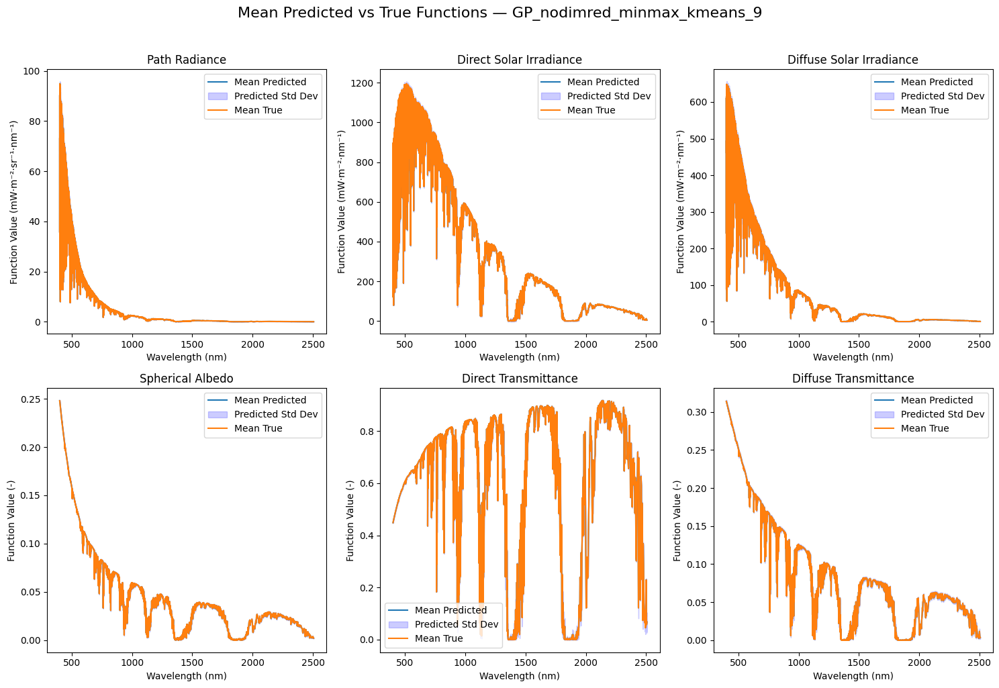

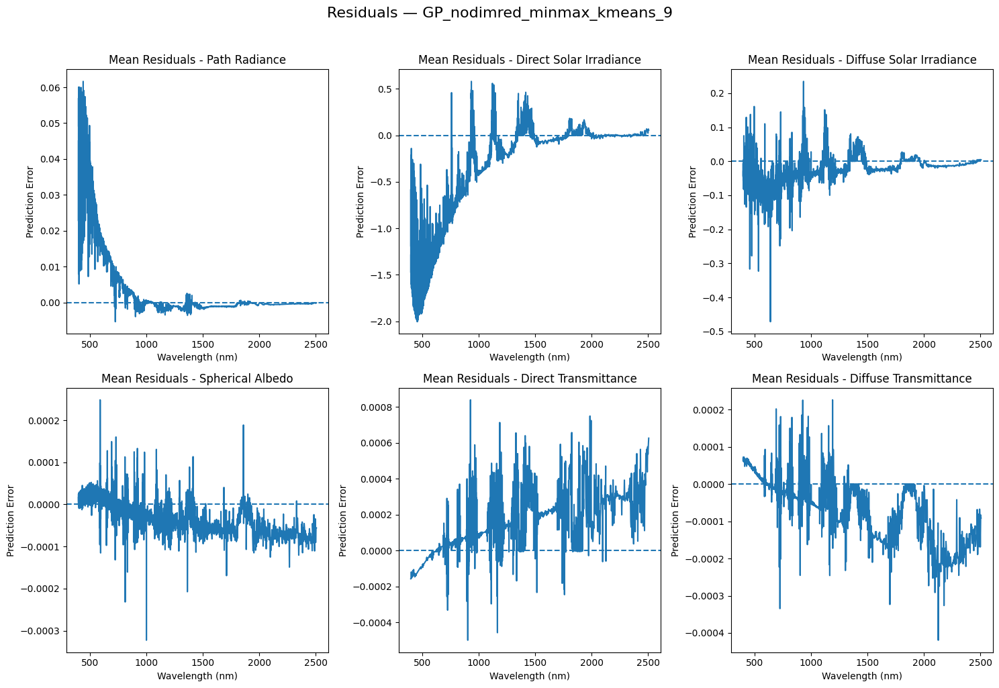

---PREDICTING WITH WINDOWED METHOD---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.

Total Cholesky factorizations: 60 (vs. 25230 for the per-wavelength approach)
Wavelengths covered by shared-kernel windows: 25230/25230
Total time: 0.51s

Global Coverage Probability (2σ): 97.84%
------------------------------
Path Radiance   Coverage: 96.37%
Direct Solar Irradiance Coverage: 96.98%
Diffuse Solar Irradiance Coverage: 97.81%
Spherical Albedo Coverage: 98.09%
Direct Transmittance Coverage: 99.17%
Diffuse Transmittance Coverage: 98.62%

0.0037493683094394128
0.5557909806206432
Testing MRE: 0.0037493683094394128
Path Radiance MRE: 0.0071
Direct Solar Irradiance MRE: 0.0031
Diffuse Solar Irradiance MRE: 0.0052
Spherical Albedo MRE: 0.0032
Direct Transmittance MRE: 0.0007
Diffuse Transmittance MRE: 0.0032


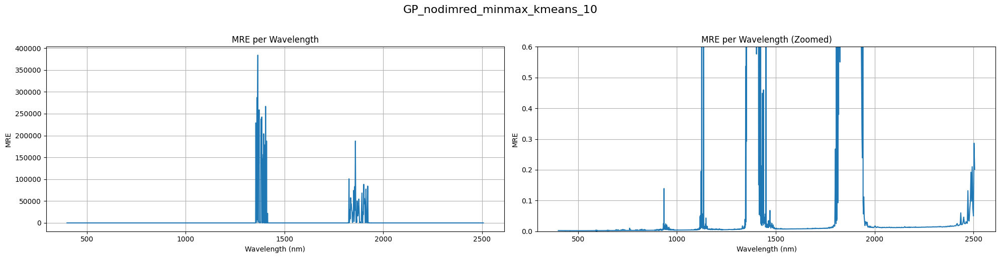

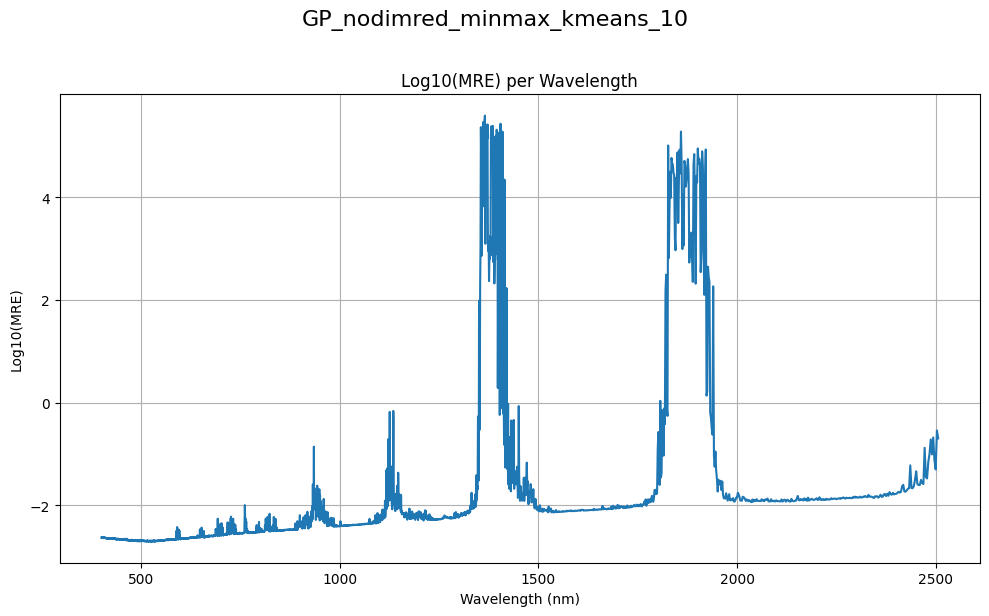

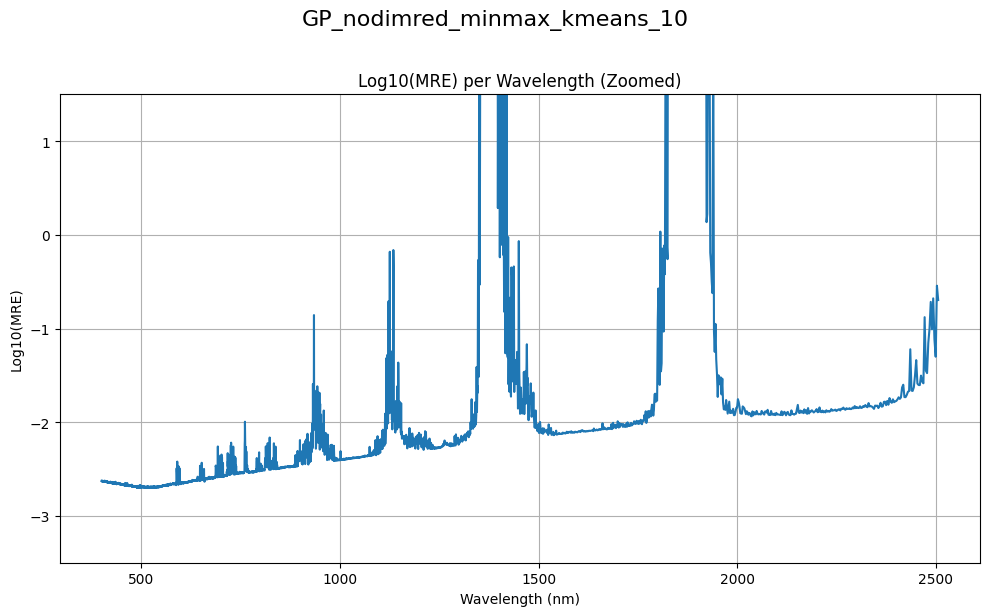

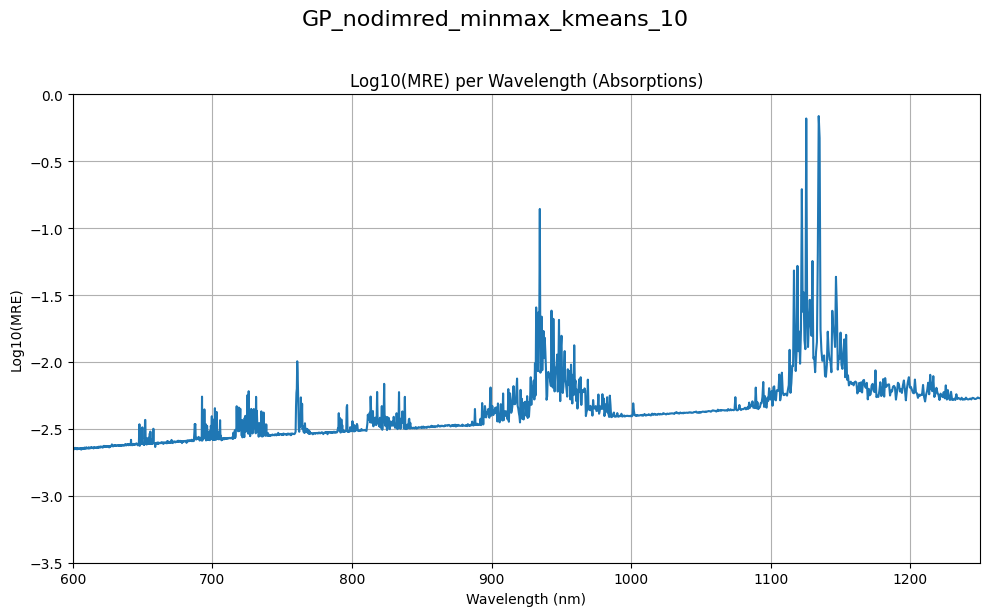

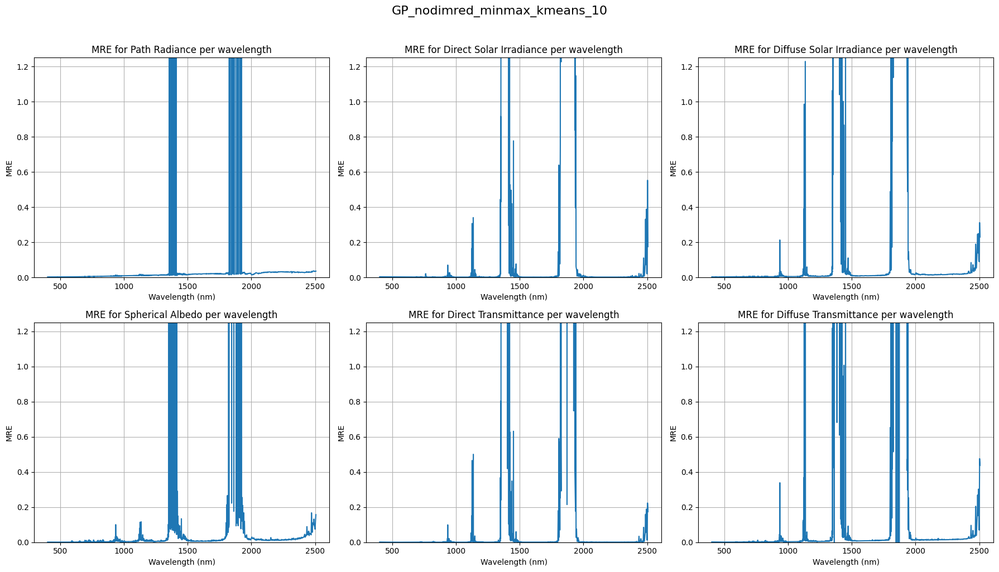

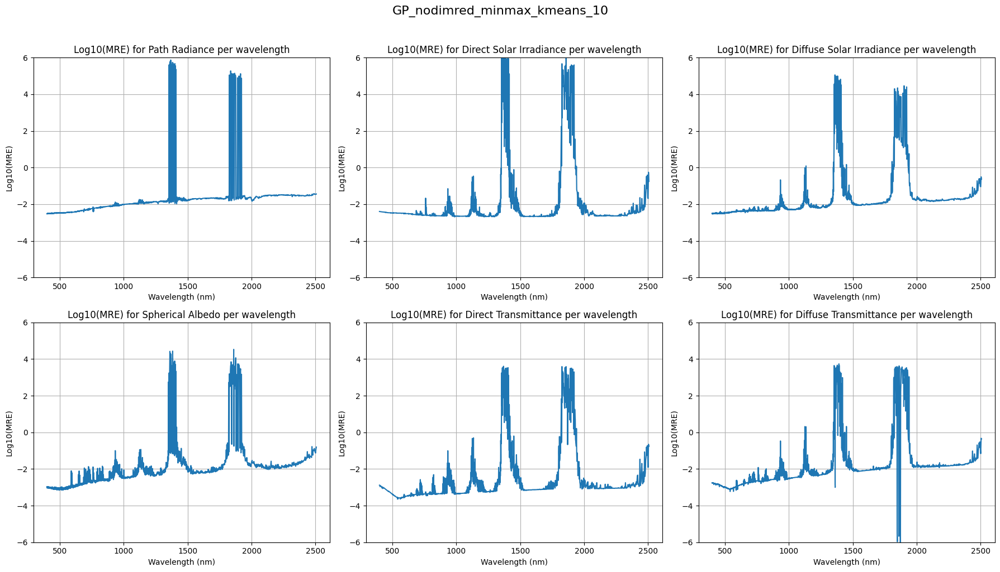

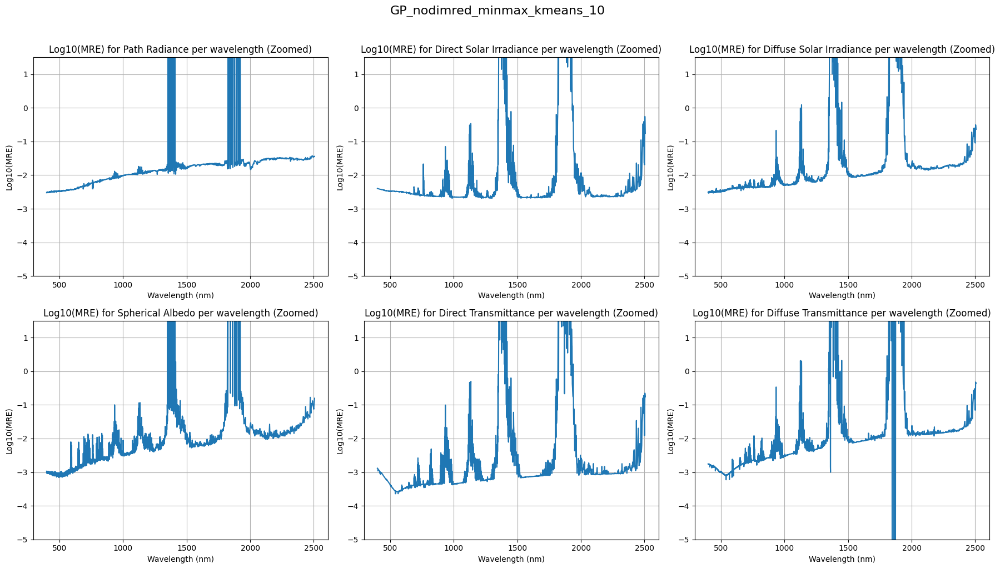

Testing MAE: 0.5557909806206432
Path Radiance MAE: 0.0759
Direct Solar Irradiance MAE: 2.3124
Diffuse Solar Irradiance MAE: 0.9455
Spherical Albedo MAE: 0.0002
Direct Transmittance MAE: 0.0004
Diffuse Transmittance MAE: 0.0003


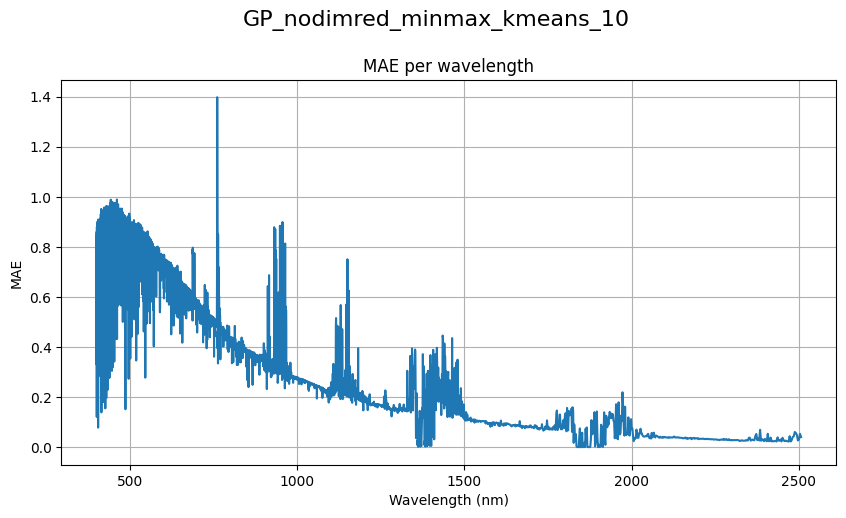

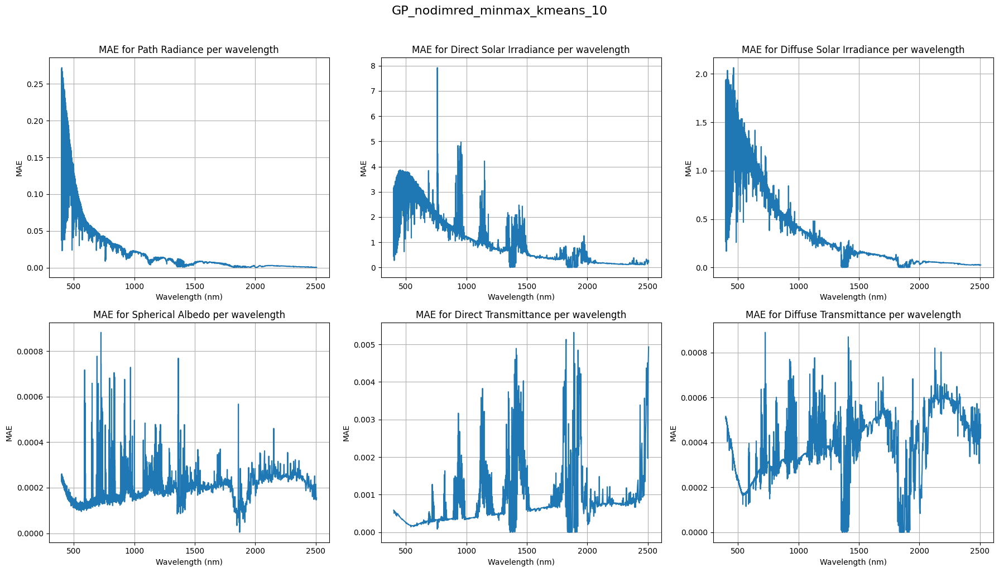

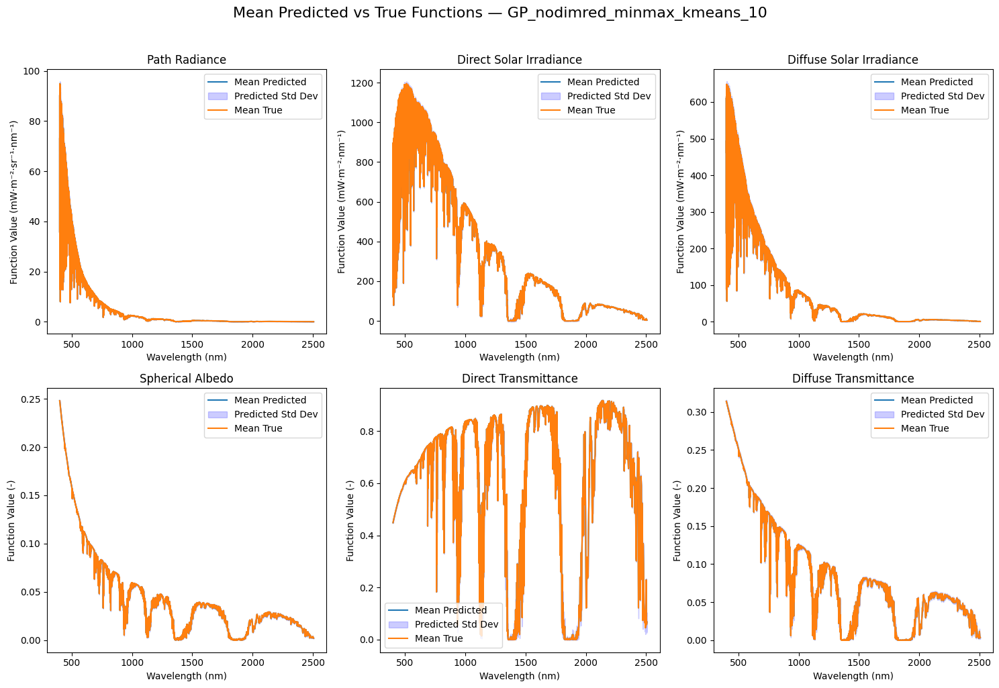

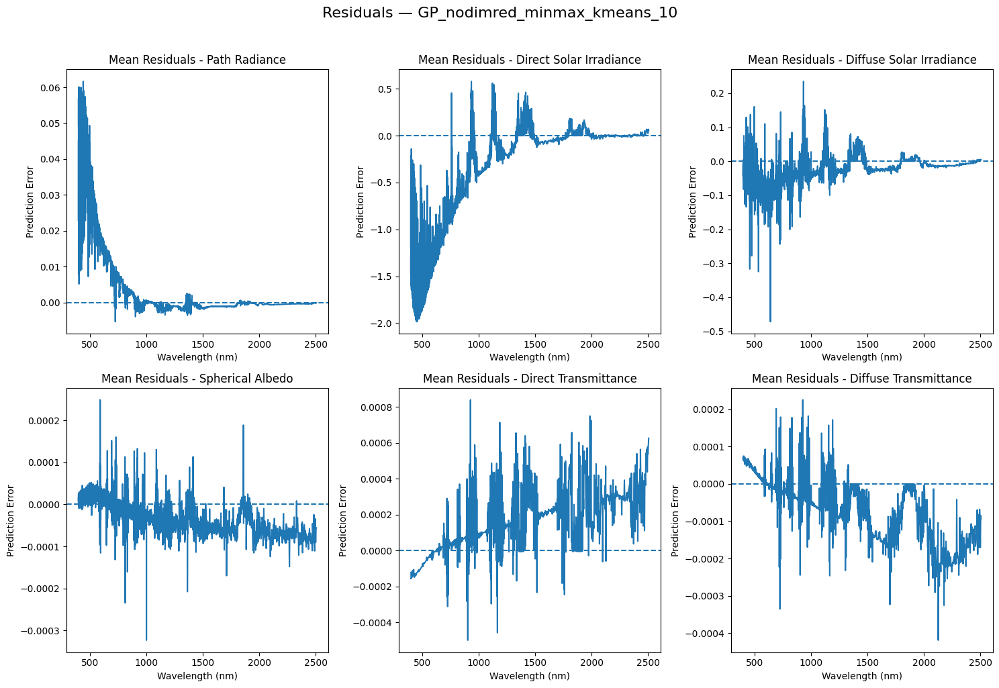

In [39]:
for k in range(K_CLUSTERS):

    with open(globals.gp_input_path(f"gp_saves/nodimred_resources/gpr_list_nodimred_windows_{k+1}.pkl"), "rb") as f:
        windows_per_function = pickle.load(f)

    preds_windowed_median, stds_windowed_median, test_time_windowed_median = predict_windowed_shared_kernel(gpr_list, X_test_scaled, X_tr_scaled, Y_tr_scaled, windows_per_function, y_scalers, len(wavelengths))

    global_cov, func_cov = utils.calculate_coverage(Y_test, preds_windowed_median, stds_windowed_median)
    print(f"\nGlobal Coverage Probability ({2}σ): {global_cov:.2f}%")
    print("-" * 30)
    for i, name in enumerate(globals.function_names_plots):
        print(f"{name:15} Coverage: {func_cov[i]:.2f}%")
    print()

    print(utils.mre_score(Y_test, preds_windowed_median, wavelengths))
    print(utils.mae_score(Y_test, preds_windowed_median, wavelengths))

    experiment_id = f"GP_nodimred_{scale_type}_kmeans_{k+1}"
    test_mre, test_mre_per_func = utils.show_test_results_mre(Y_test, preds_windowed_median, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
    test_mae, test_mae_per_func = utils.show_test_results_mae(Y_test, preds_windowed_median, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
    utils.show_predicted_vs_true(Y_test, preds_windowed_median, stds_windowed_median, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))
    utils.show_residuals(Y_test, preds_windowed_median, wavelengths, exp_id=experiment_id, save_path=globals.gp_output_path("gp_saves/testing_results/nodimred/"))

    entry = {
        "experiment_id": experiment_id,
        "gp_kernel_full_name": "nodimred_windowed_median",
        "model": "nodimred_windowed_median",
        "scale_type": "minmax",
        "dataset_size": "500",
        "inference_time": test_time_windowed_median,
        "test_mre": test_mre,
        "test_mae": test_mae,
        "global_cov": global_cov
    }

    for name, value in zip(globals.function_names_results, test_mre_per_func):
        entry[f"test_mre_{name}"] = value

    for name, value in zip(globals.function_names_results, test_mae_per_func):
        entry[f"test_mae_{name}"] = value

    for name, value in zip(globals.function_names_plots, func_cov):
        entry[f"coverage_{name}"] = value

    results_df = pd.DataFrame([entry])
    results_df.to_csv(globals.gp_output_path("./gp_saves/testing_results/gp_test_results.csv"), mode="a", header=not Path(globals.gp_output_path("./gp_saves/testing_results/gp_test_results.csv")).exists(), index=False)

In [20]:
from matplotlib.ticker import FuncFormatter

def extract_experiment_data(df, regex_pattern, x_col_name):
    """Extract x-axis and metric values for the requested experiments.

        Args:
        df: Dataframe containing experiment results.
        regex_pattern: Regular expression selecting the experiment rows.
        x_col_name: Column name used to obtain x-axis values.

        Returns:
            Extracted x-axis values and corresponding experiment metrics.
        """
    filtered_df = df[df["experiment_id"].str.match(regex_pattern)].copy()
    filtered_df[x_col_name] = (
        filtered_df["experiment_id"].str.extract(regex_pattern)[0].astype(int)
    )
    return filtered_df.sort_values(x_col_name)


def plot_combined_metrics(experiments, x_label, x_ticks=range(2, 11), dataset_name="Ref-Interp"):
    """Plot combined metric results across experiments.

        Args:
        experiments: Experiment data to plot.
        x_label: Label for the horizontal axis.
        x_ticks: Horizontal-axis tick locations.
        dataset_name: Dataset label used in the plot.

        Returns:
            None. Displays the combined metric figure.
        """
    metrics = [
        ("test_mre", "MRE (%)", f"MRE vs. {x_label}"),
        ("test_mae", "MAE", f"MAE vs. {x_label}"),
        ("global_cov", "Uncertainty (2σ)", f"Uncertainty vs. {x_label}"),
        ("inference_time", "Runtime (seconds)", f"Runtime vs. {x_label}"),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(15, 5), dpi=300)
    fig.suptitle(f"{dataset_name}", fontsize=16)
    for ax, (y_col, y_label, title) in zip(axes, metrics):
        for exp in experiments:
            ax.plot(exp["df"][exp["x_col"]], exp["df"][y_col], marker="o", label=exp["label"],)
        ax.set_xlabel(x_label if x_label != "Parameter Count" else x_label + " (Windows / PCs)")
        ax.set_ylabel(y_label)
        ax.set_title(title)
        if "MRE" in y_label:
            ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.2f}"))
        if x_ticks is not None:
            ax.set_xticks(x_ticks)
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()

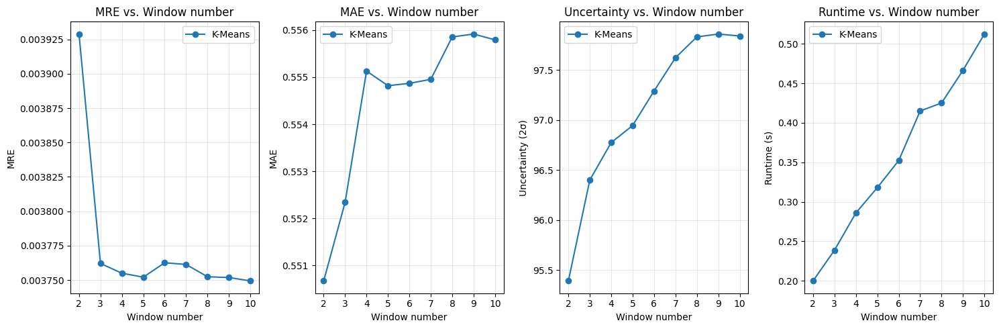

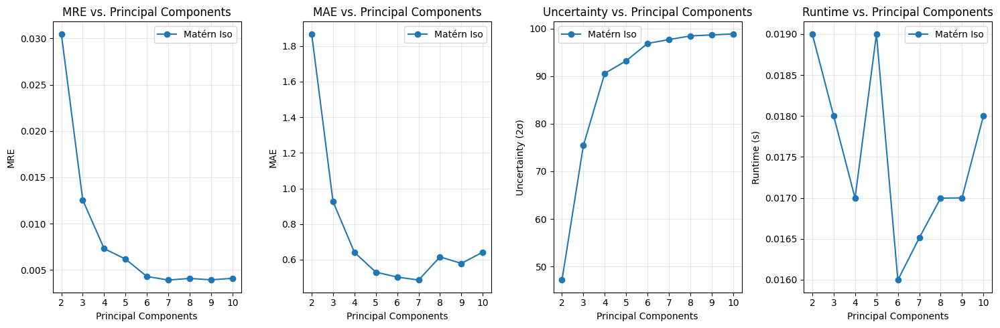

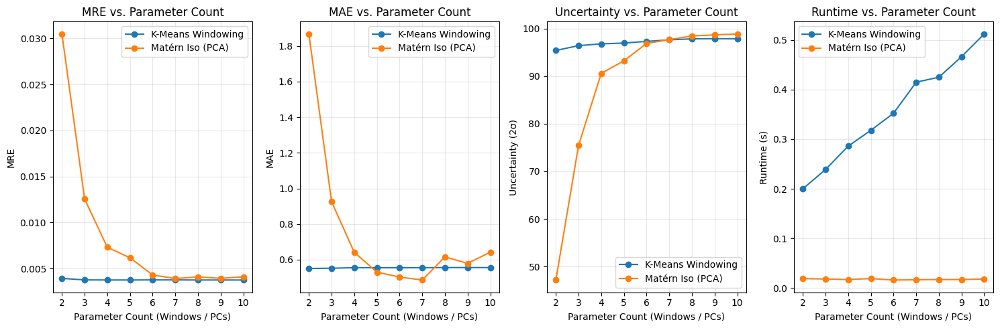

In [ ]:
results_df = pd.read_csv(globals.gp_input_path("./gp_saves/testing_results/gp_test_results.csv"))
kmeans_df = extract_experiment_data(results_df, r"GP_nodimred_minmax_kmeans_((?:[2-9]|10))$", "window")
matern_df = extract_experiment_data(results_df, r"Matern_iso_minmax_500_((?:[2-9]|10))$", "PCs")

plot_combined_metrics([{"df": kmeans_df, "x_col": "window", "label": "K-Means"}], "Window number")
plot_combined_metrics([{"df": matern_df, "x_col": "PCs", "label": "Matérn Iso"}], "Principal Components",)
plot_combined_metrics(
    [
        {"df": kmeans_df, "x_col": "window", "label": "K-Means Windowing"},
        {"df": matern_df, "x_col": "PCs", "label": "Matérn Iso (PCA)"},
    ],
    "Parameter Count",
)

#### AMLEC Testing

In [10]:
X_test_amlec_interp, Y_test_amlec_interp, _ = utils.load_train_h5(globals.TEST_FILE_A_INTERP)
X_test_amlec_extrap, Y_test_amlec_extrap, _ = utils.load_train_h5(globals.TEST_FILE_A_EXTRAP)

rho_data = pd.read_csv(globals.REF_LDB, header=None, names=['Wavelength', 'Column 1', 'Column 2'])
rho_ref = rho_data['Column 1']

sza = X_test_amlec_extrap[:, 6]  # shape (n_samples,)
sza = sza.reshape(1, -1).T

In [12]:
x_scaler, X_tr_scaled, X_test_amlec_scaled = utils.scale_input_data(X_tr, X_test_amlec_extrap, scale_type=scale_type)

---------- Scaling input data using minmax scaling... ----------
---------- Input data scaling completed. ----------



In [13]:
rho_ref_resampled = utils.resample_reference_spectrum(
    rho_data["Wavelength"].values,
    rho_data["Column 1"].values,
    wavelengths,
)

New shape: (4205,)


In [9]:
dataset_name = "interp"

---PREDICTING WITH ACTUAL FITTED GPRs---
Function 1 done.
Function 2 done.
Function 3 done.
Function 4 done.
Function 5 done.
Function 6 done.
Total time: 1343.39s
Testing MRE: 0.08552122699999368


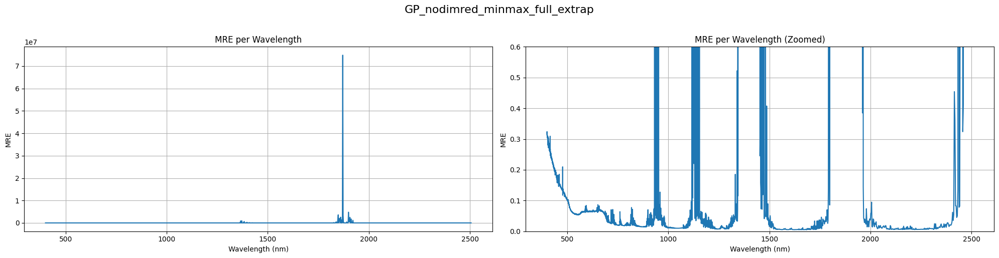

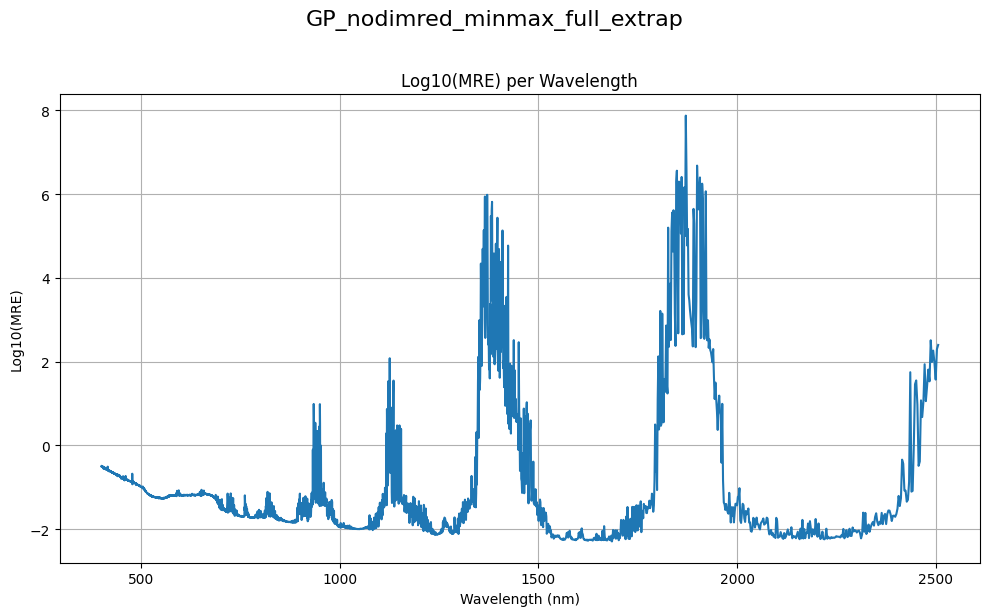

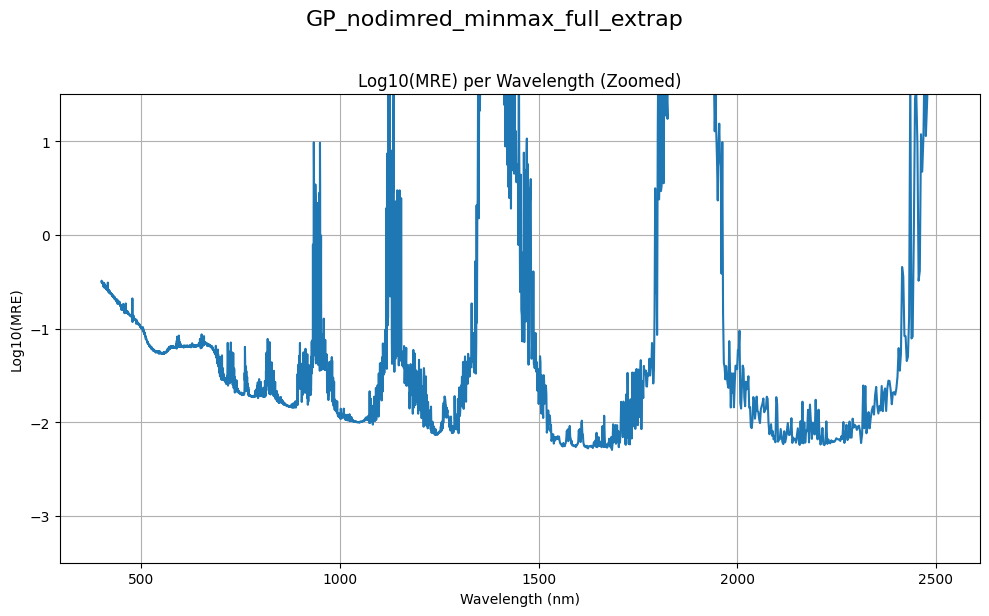

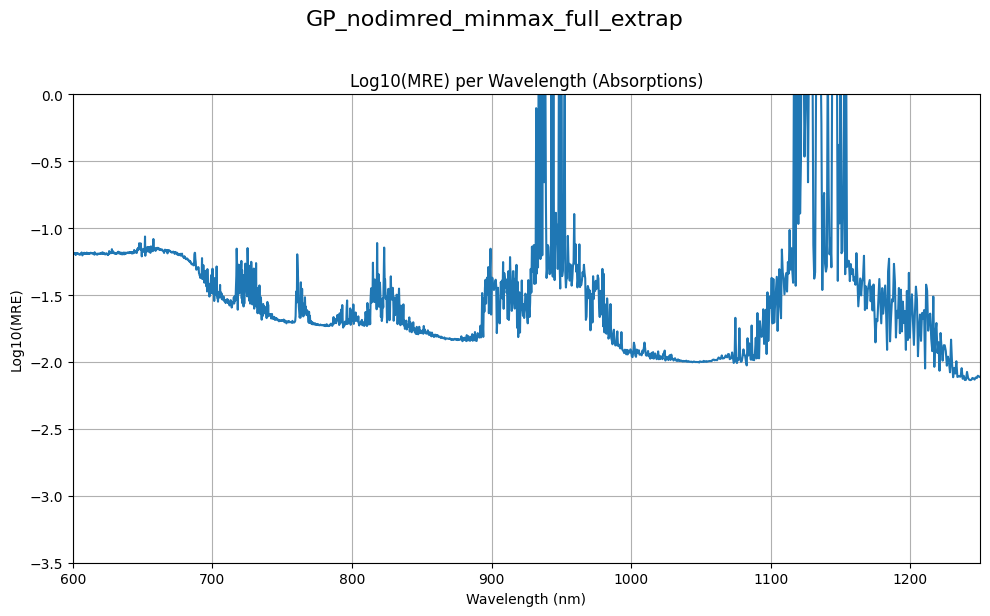

Testing MAE: 0.009675012495090049


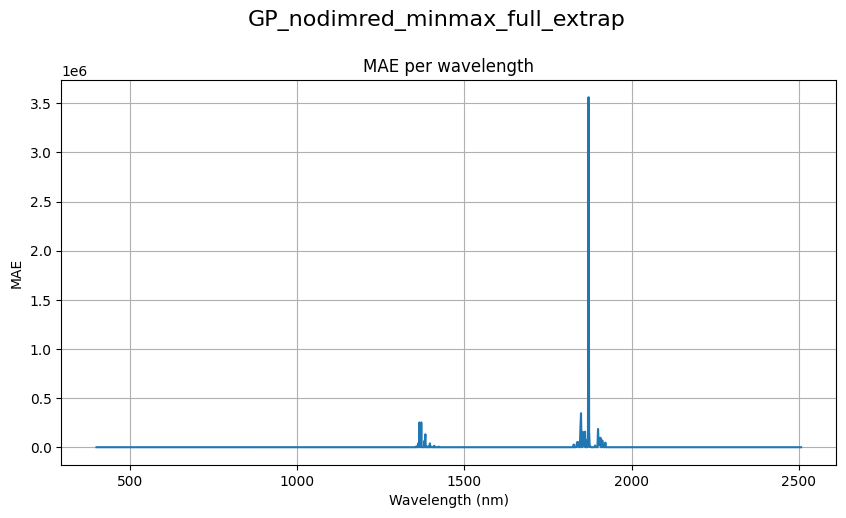

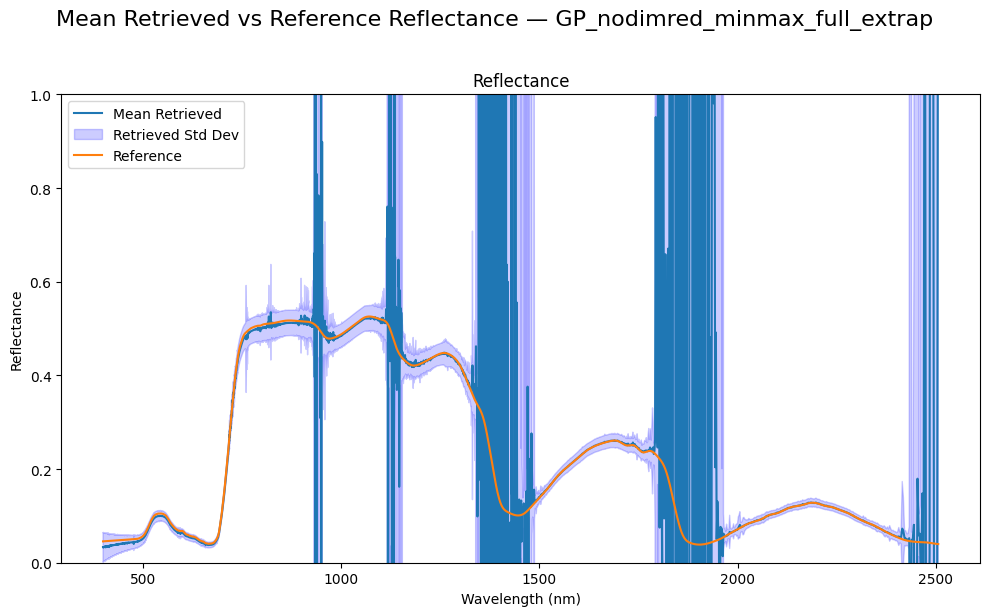

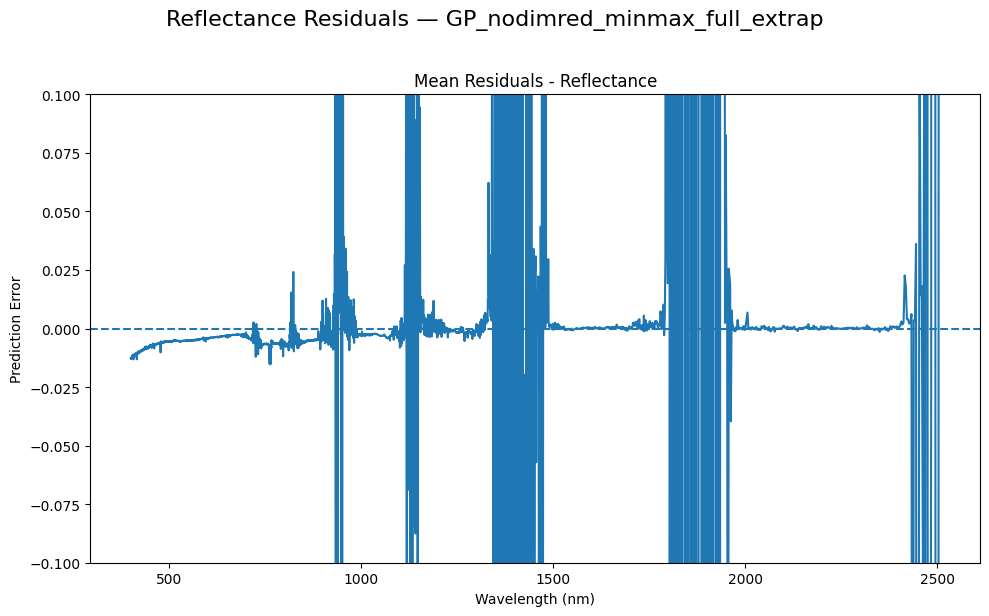

In [15]:
Y_test_pred, Y_test_std, elapsed = predict_all(gpr_list, X_test_amlec_scaled, y_scalers, len(wavelengths))

Y_pred_flat = Y_test_pred.reshape(Y_test_pred.shape[0], -1)

rho_ret = utils.retrieve_reflectance(Y_test_amlec_extrap, Y_pred=Y_pred_flat, sza=sza, n_wvl=len(wavelengths))

exp_id = f"GP_nodimred_{scale_type}_full"
full_id = f"GP_nodimred_{scale_type}_full_{dataset_name}"
test_mre, _ = utils.show_test_results_mre(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))
test_mae, _ = utils.show_test_results_mae(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))

Y_std_flat = Y_test_std.reshape(Y_test_std.shape[0], -1)  # (n_samples, 6*n_wvl)
rho_std = utils.propagate_reflectance_uncertainty(Ltoa=Y_test_amlec_extrap, Y_pred=Y_pred_flat, Y_std=Y_std_flat, sza=sza, n_wvl=len(wavelengths))
lower = rho_ret - 2 * rho_std
upper = rho_ret + 2 * rho_std
is_inside = (rho_ref_resampled >= lower) & (rho_ref_resampled <= upper)
global_coverage = np.mean(is_inside) * 100

utils.show_predicted_vs_true_reflectance(rho_ref_resampled, rho_ret, rho_std, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))
utils.show_residuals_reflectance(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))

entry = {
    "experiment_id": exp_id,
    "gp_kernel_full_name": "nodimred_full",
    "model": "nodimred_full",
    "scale_type": "minmax",
    "dataset_size": "500",
    "inference_time": elapsed,
    "test_mre": test_mre,
    "test_mae": test_mae,
    "global_cov": global_coverage
}

results_df = pd.DataFrame([entry])
results_df.to_csv(globals.gp_output_path(f"./gp_saves/amlec_testing_results/{dataset_name}_gp_test_results.csv"), mode="a", header=not Path(globals.gp_output_path(f"./gp_saves/amlec_testing_results/{dataset_name}_gp_test_results.csv")).exists(), index=False)

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08026983735070928


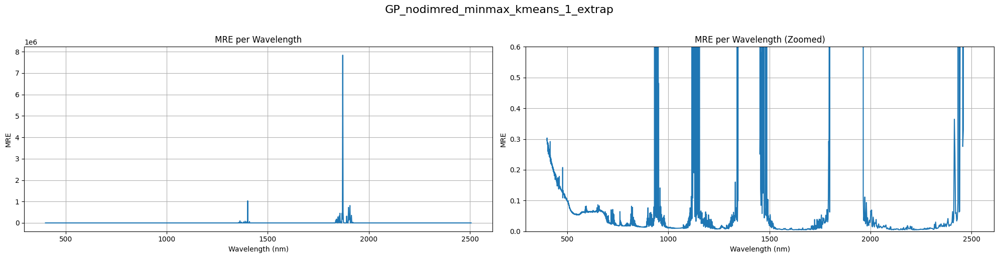

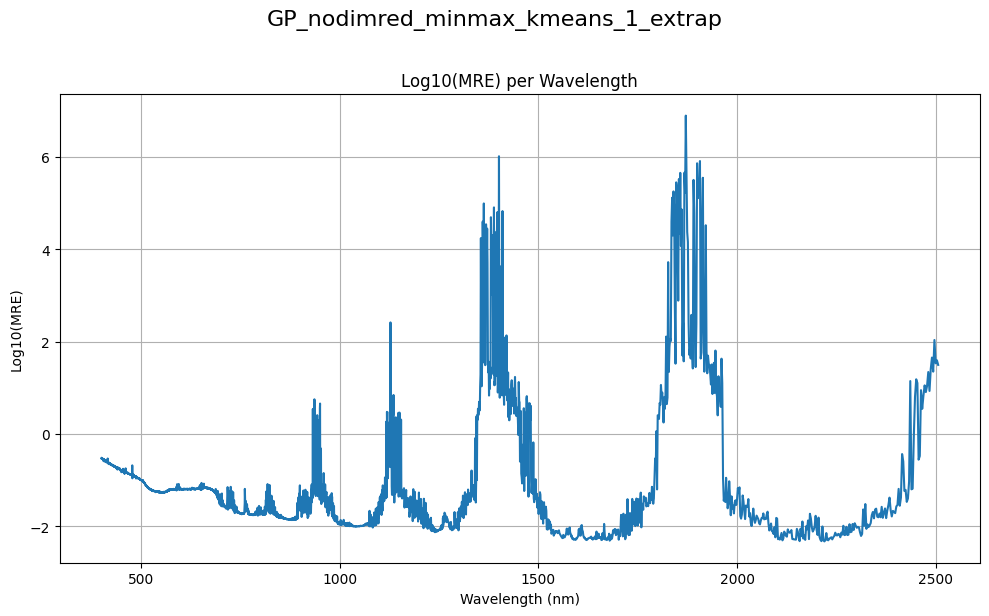

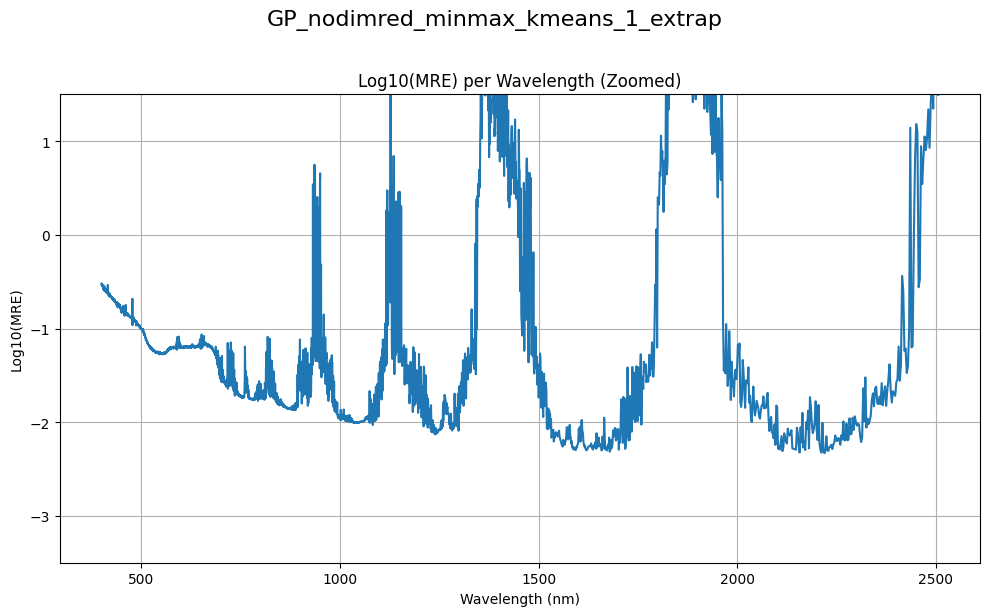

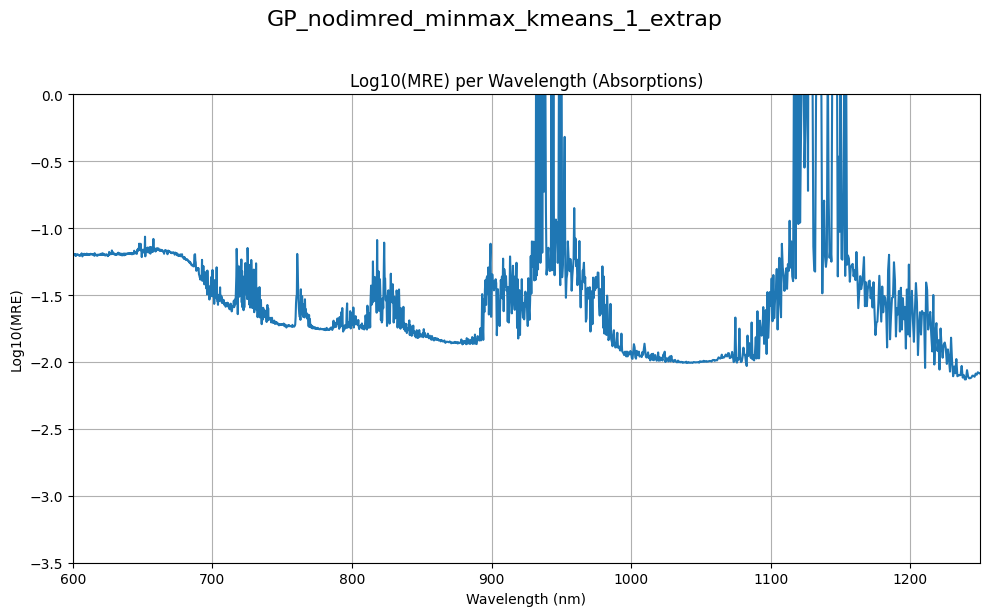

Testing MAE: 0.008638074600128717


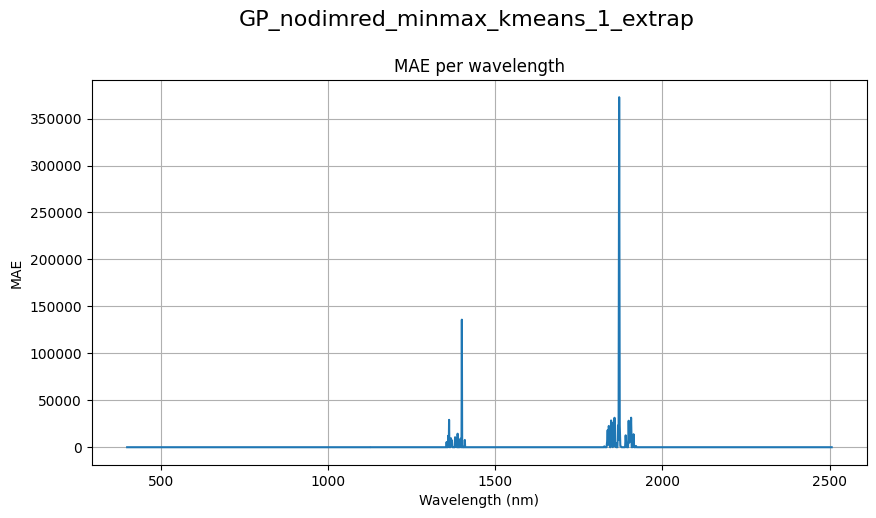

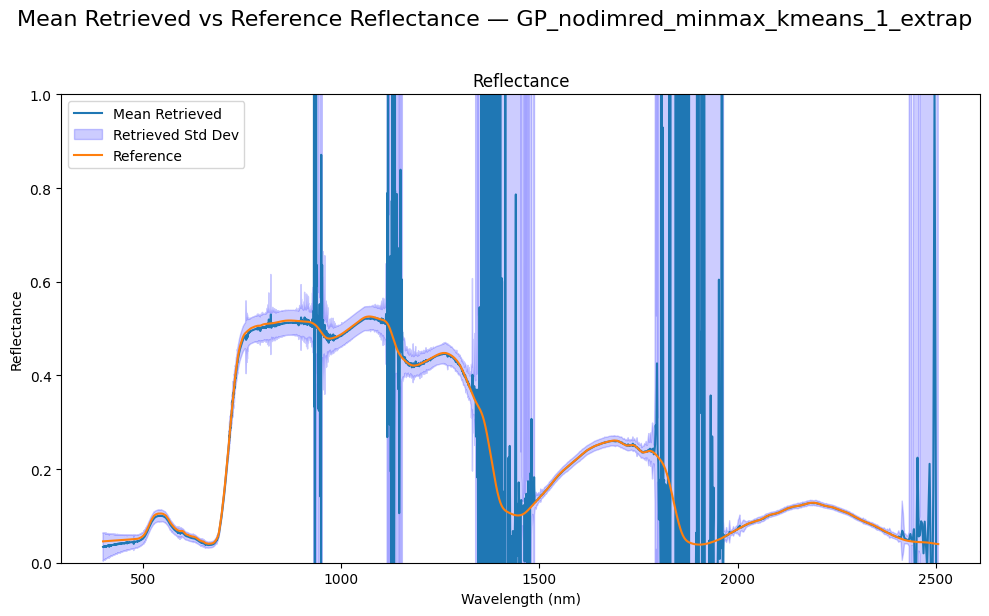

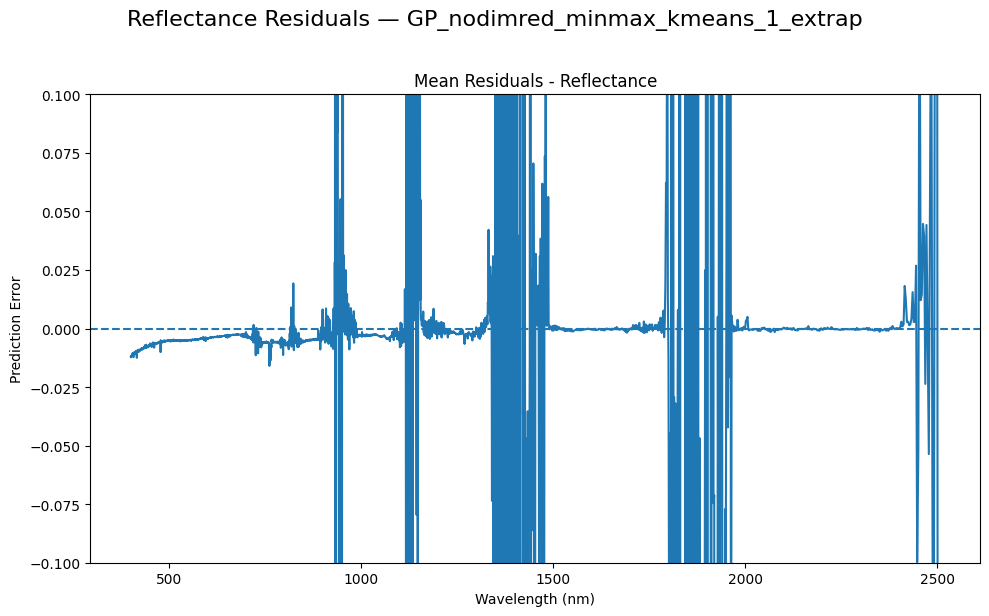

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.09296111589770295


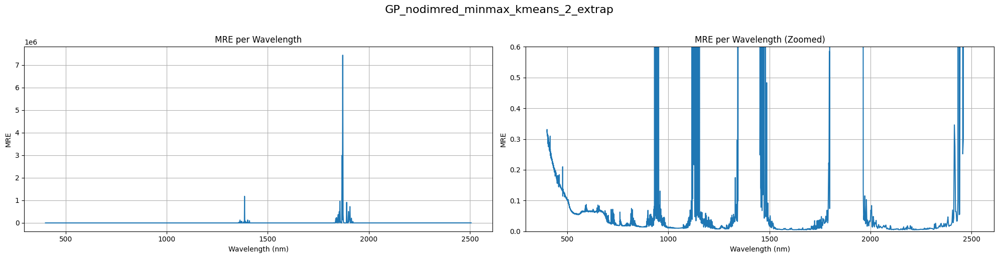

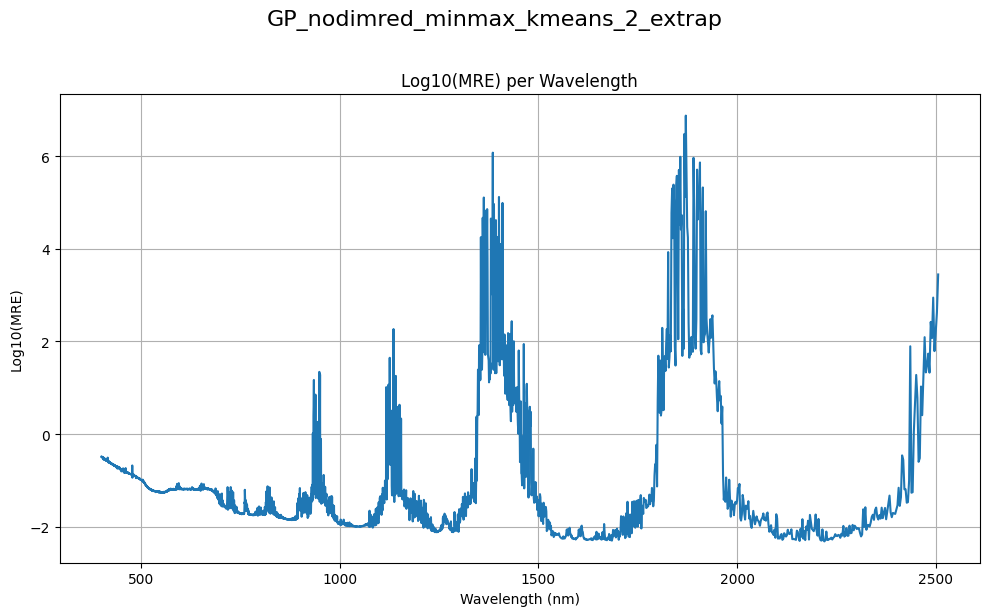

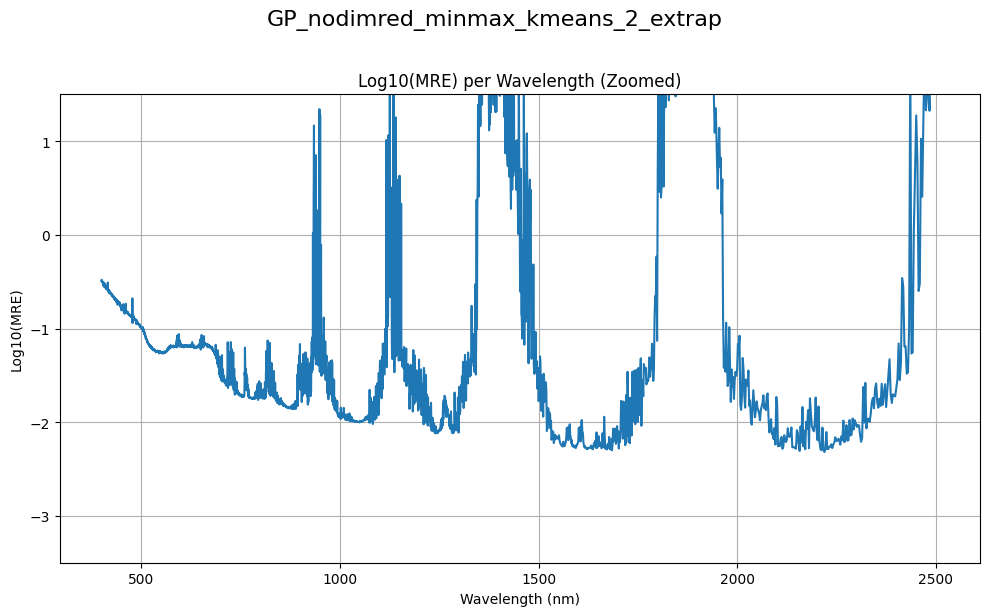

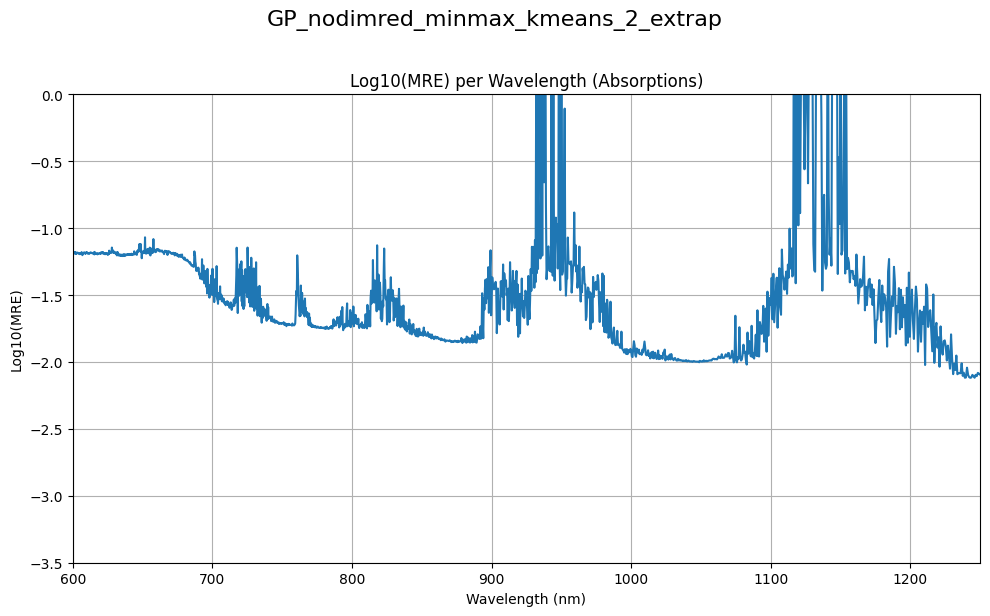

Testing MAE: 0.013359596180552814


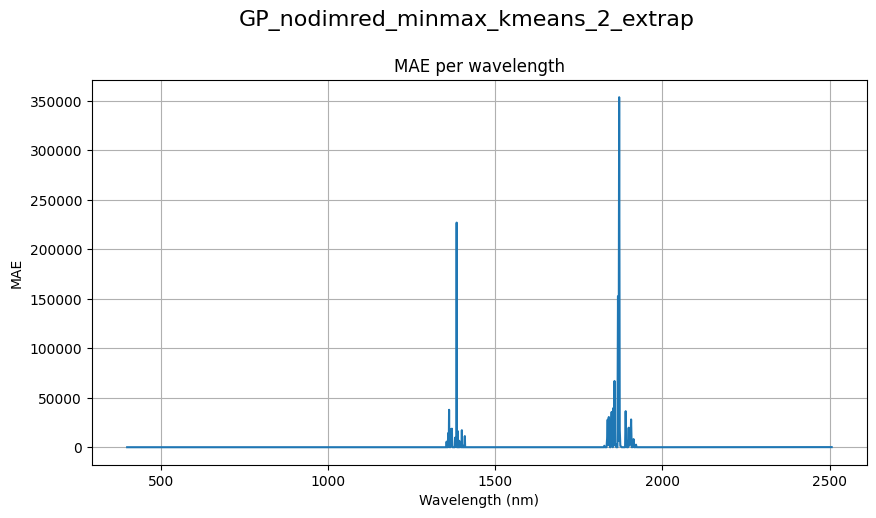

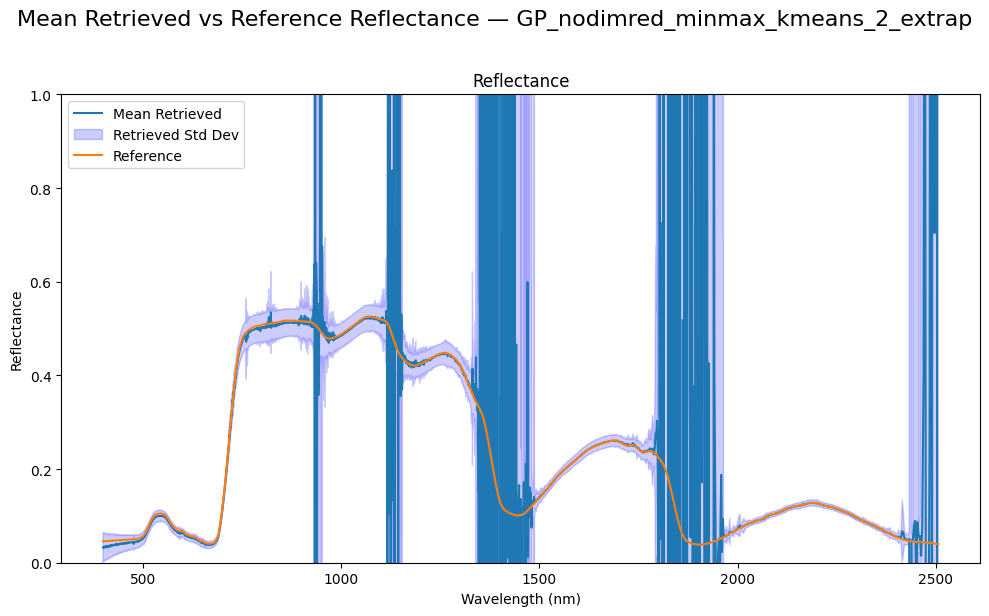

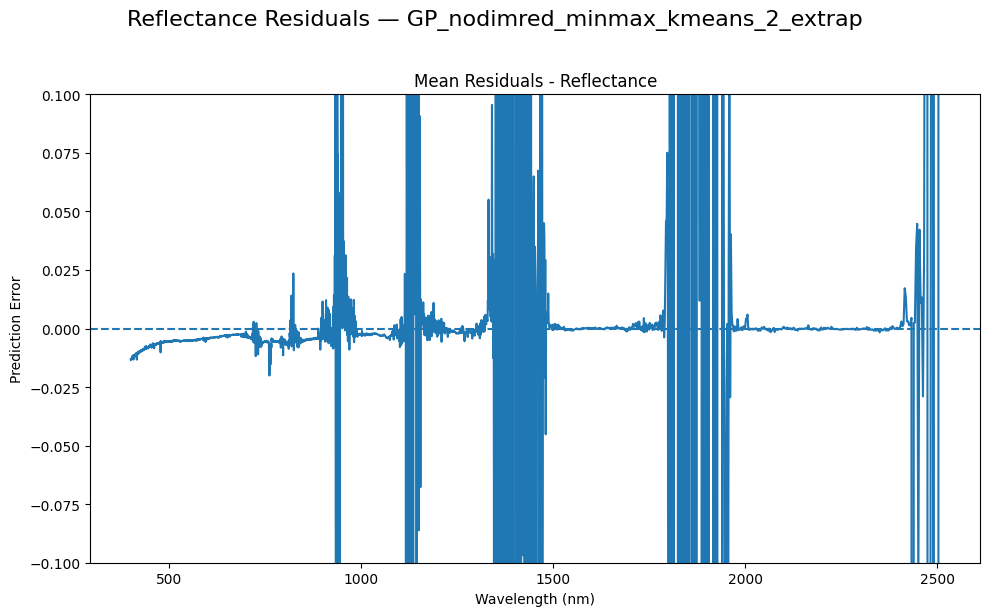

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.084085073374974


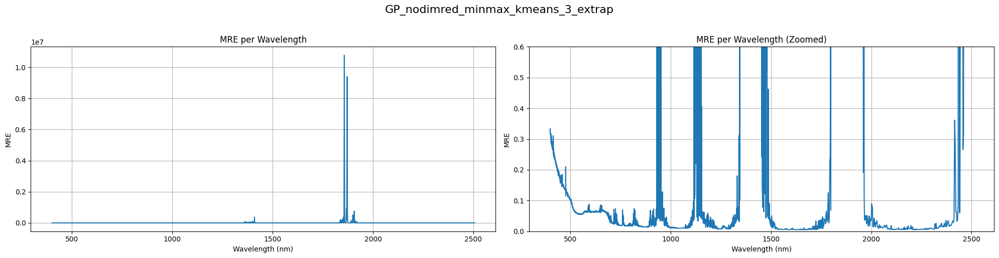

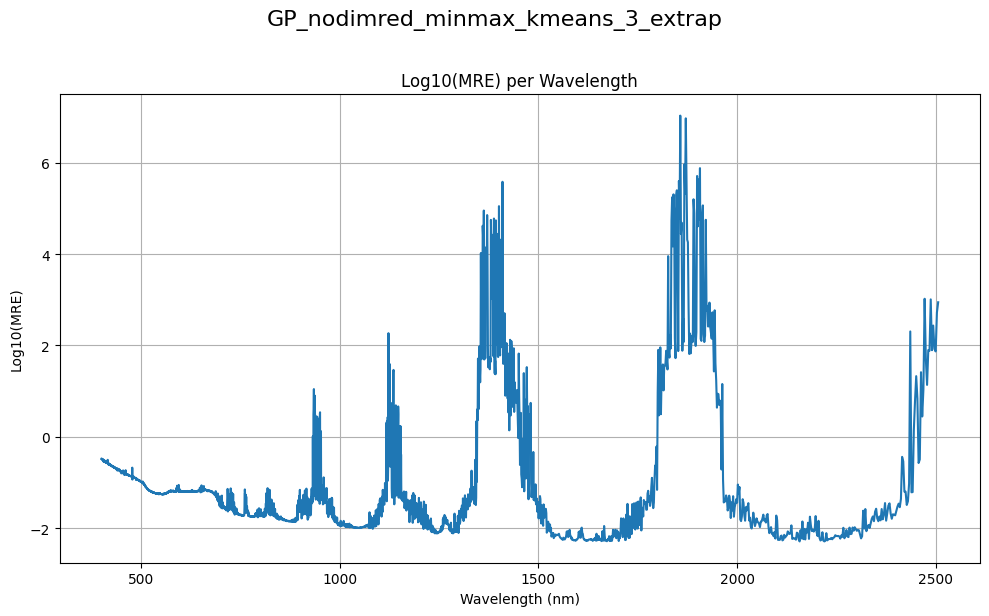

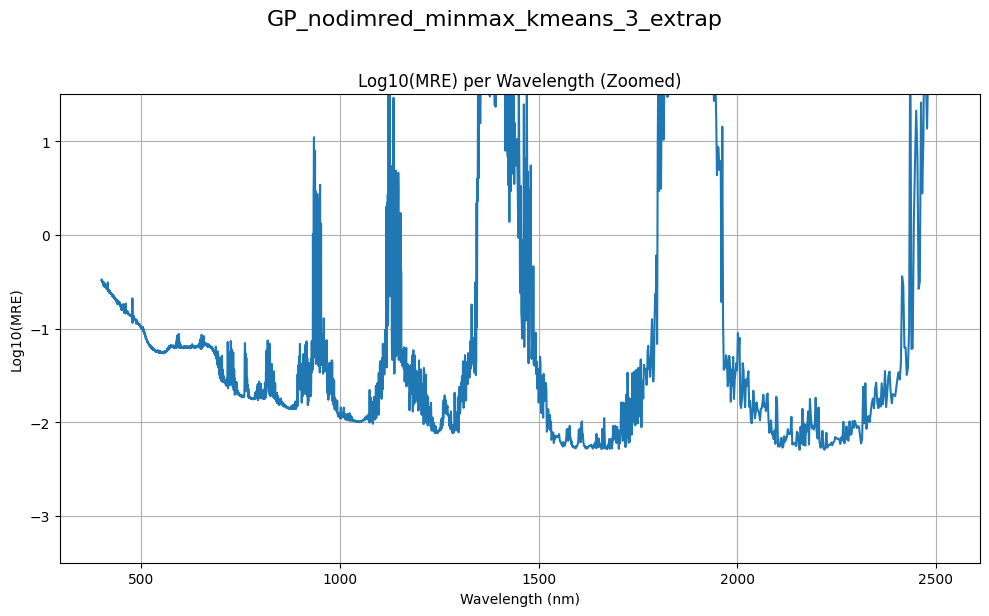

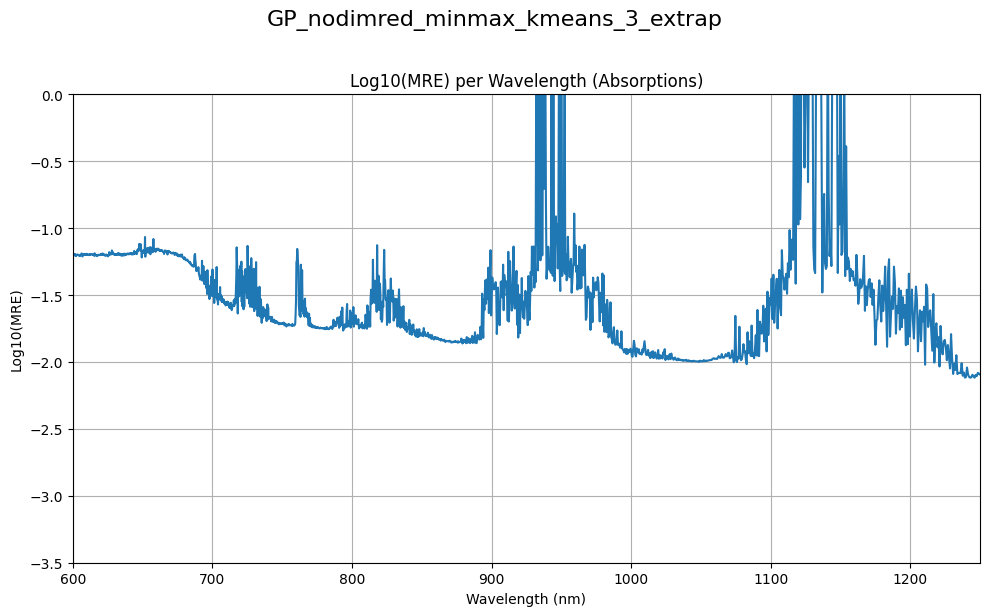

Testing MAE: 0.008850621909041869


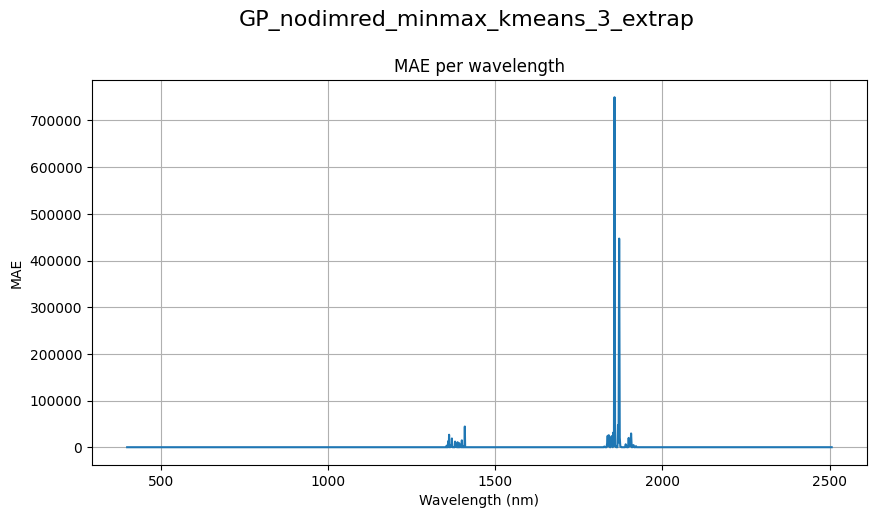

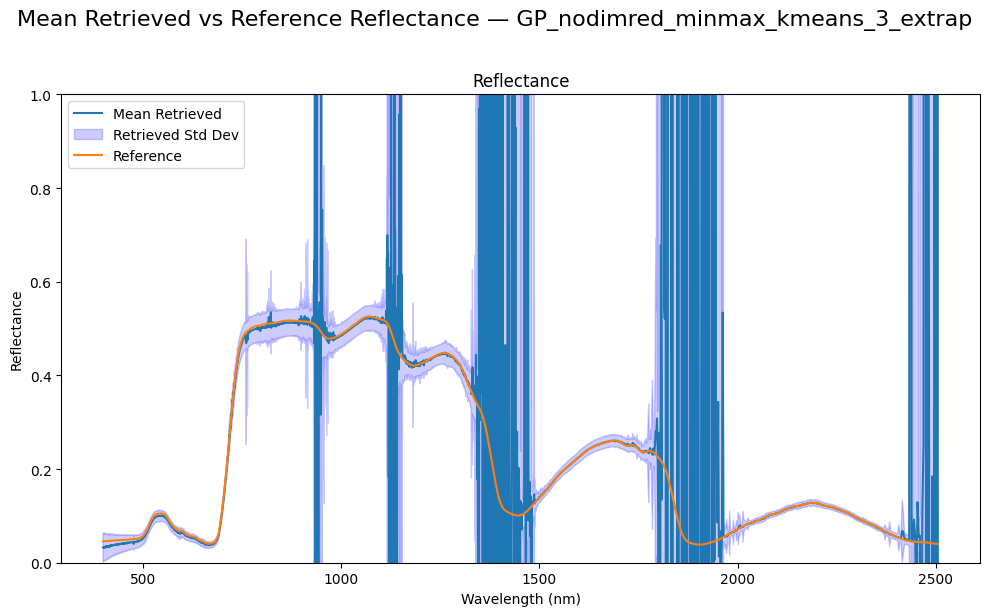

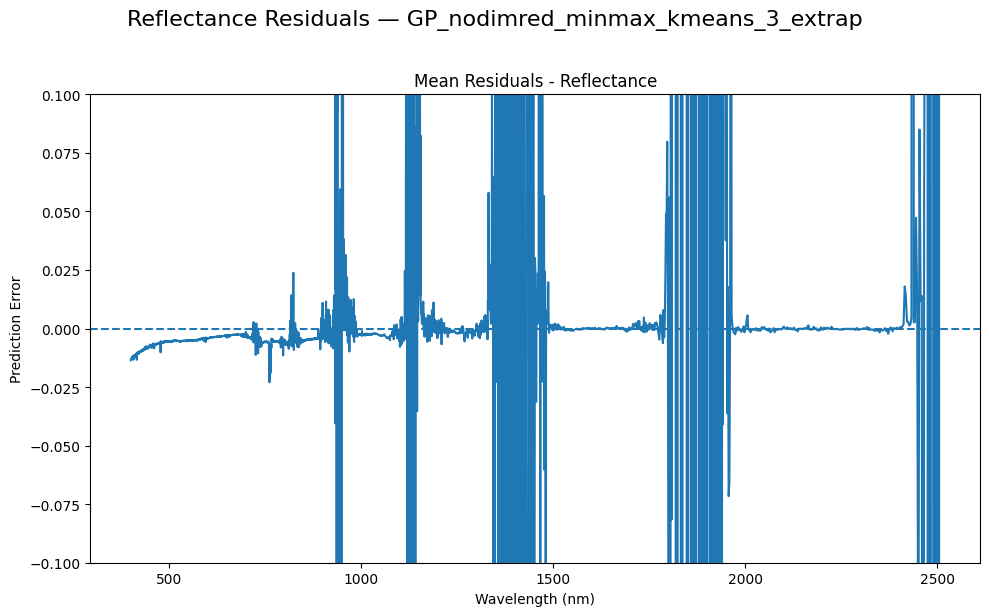

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.083114772282516


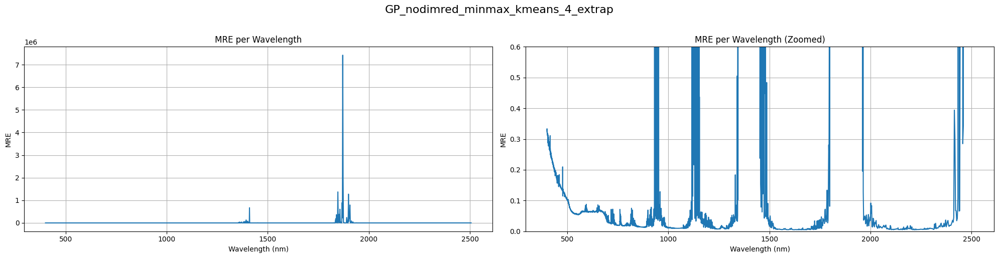

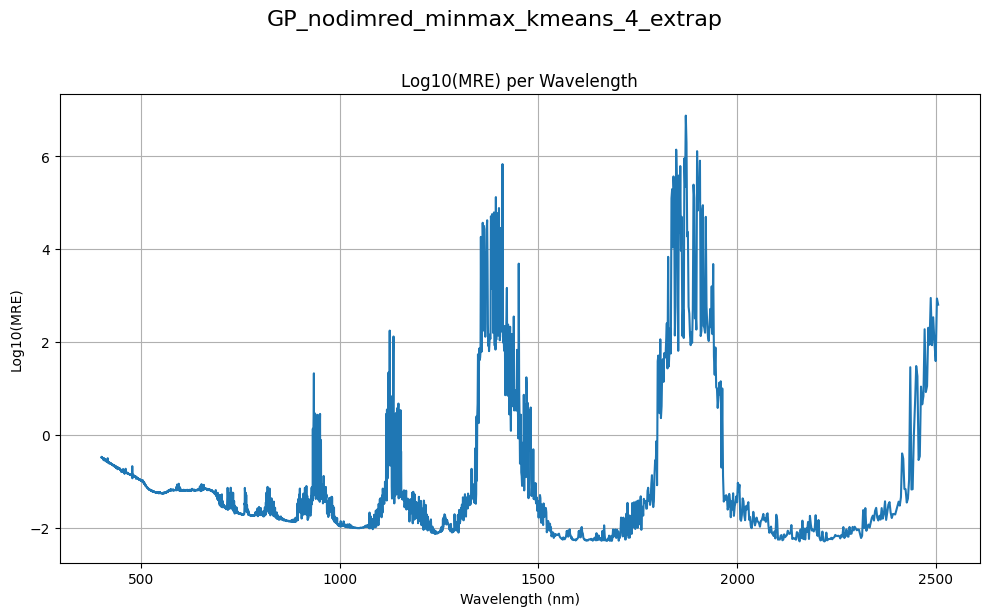

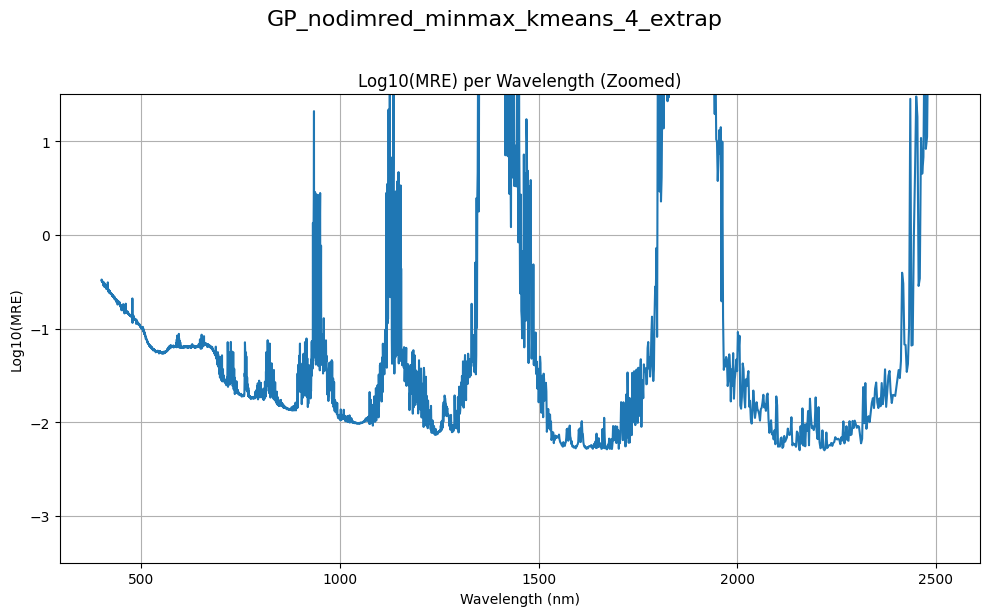

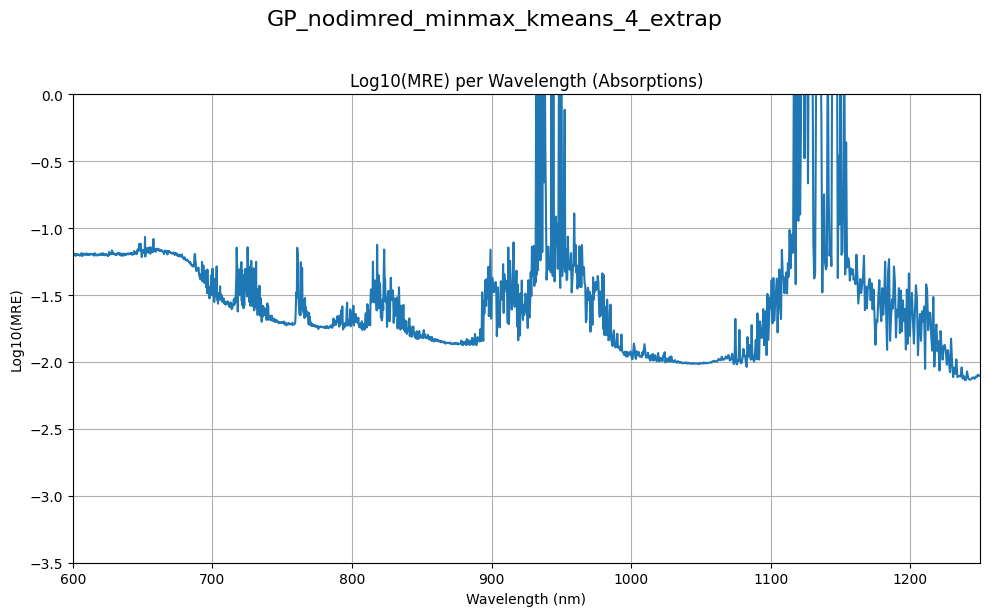

Testing MAE: 0.008400008930869654


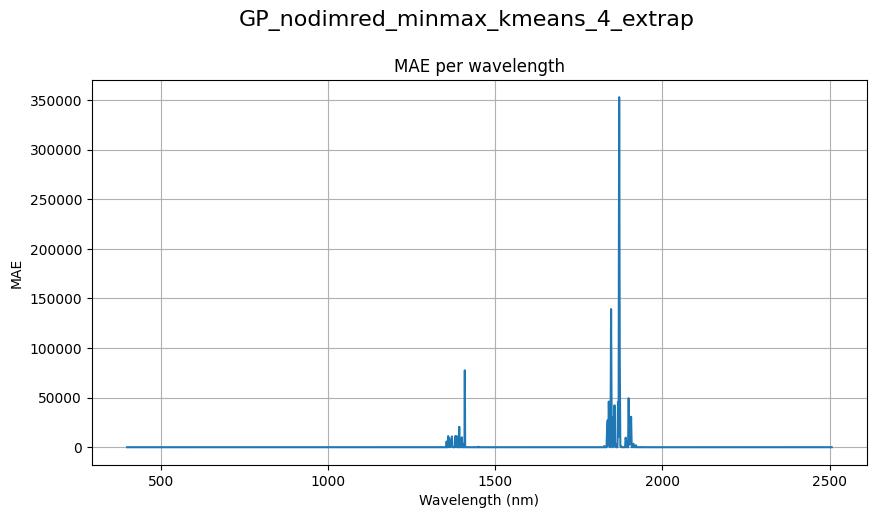

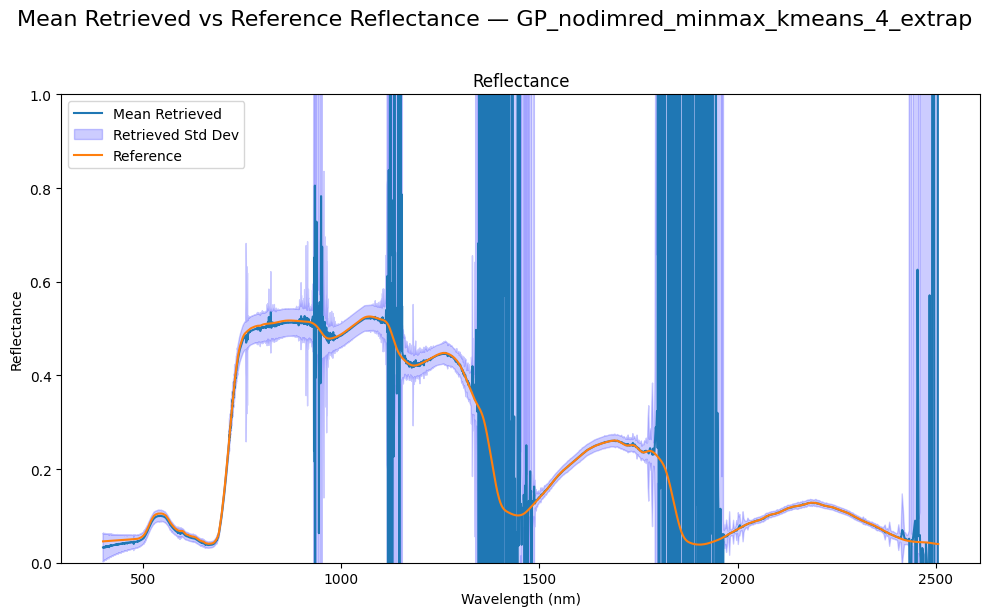

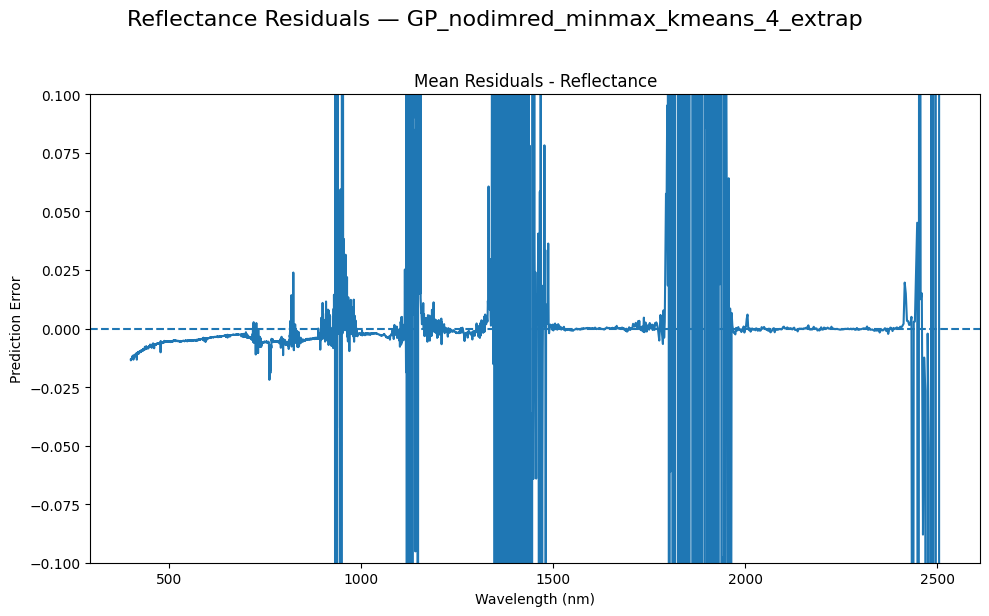

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08384743908176132


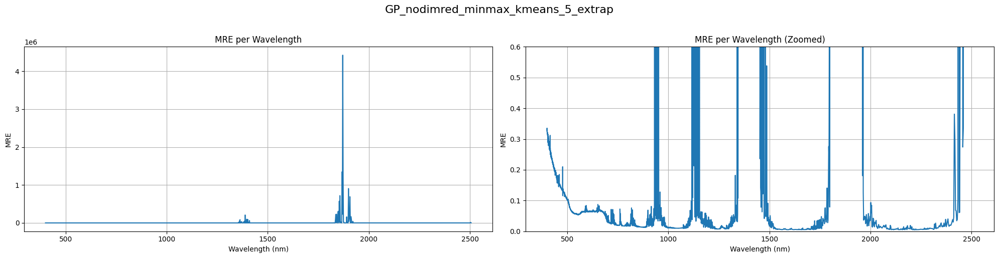

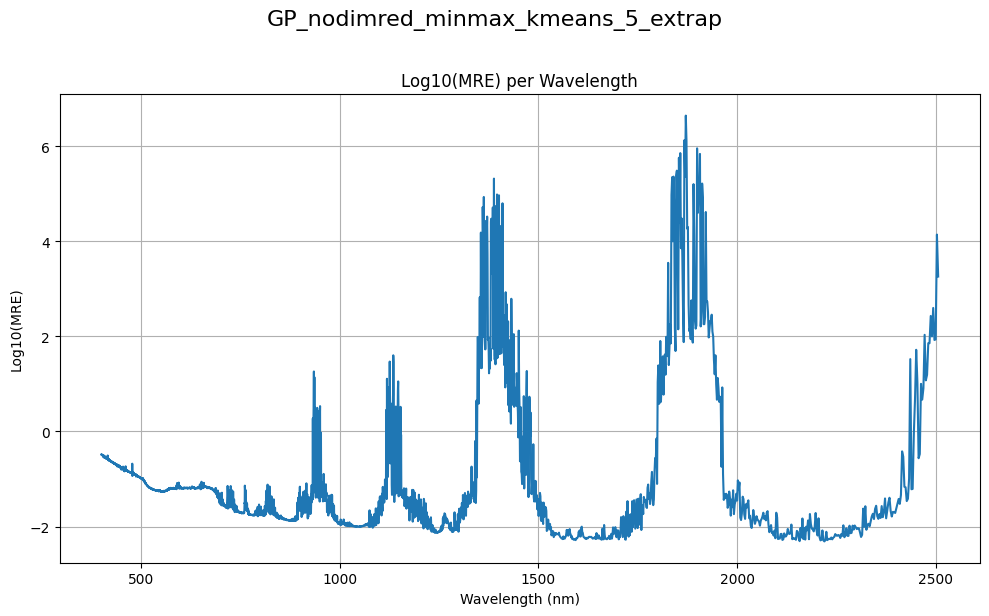

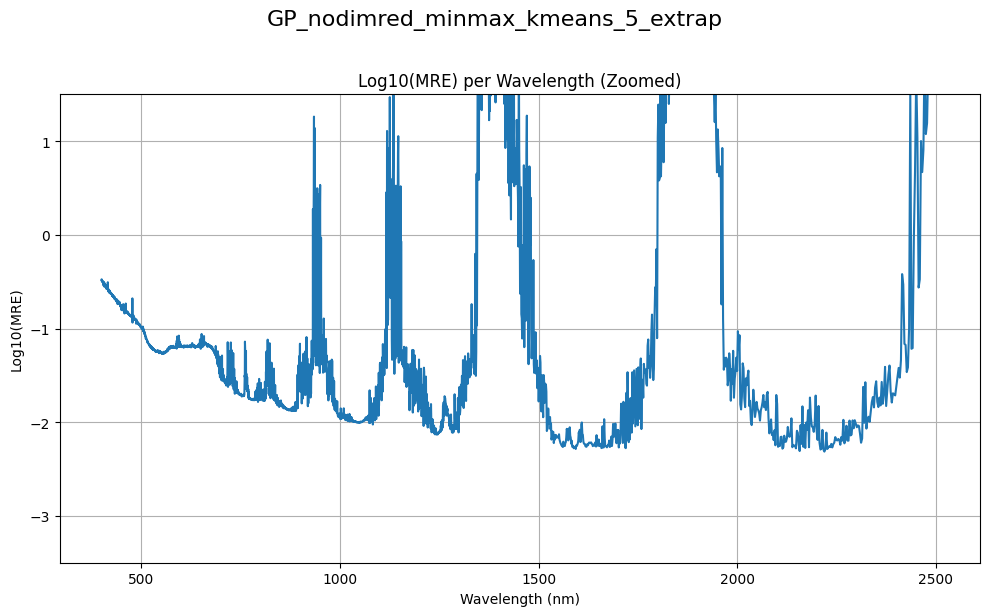

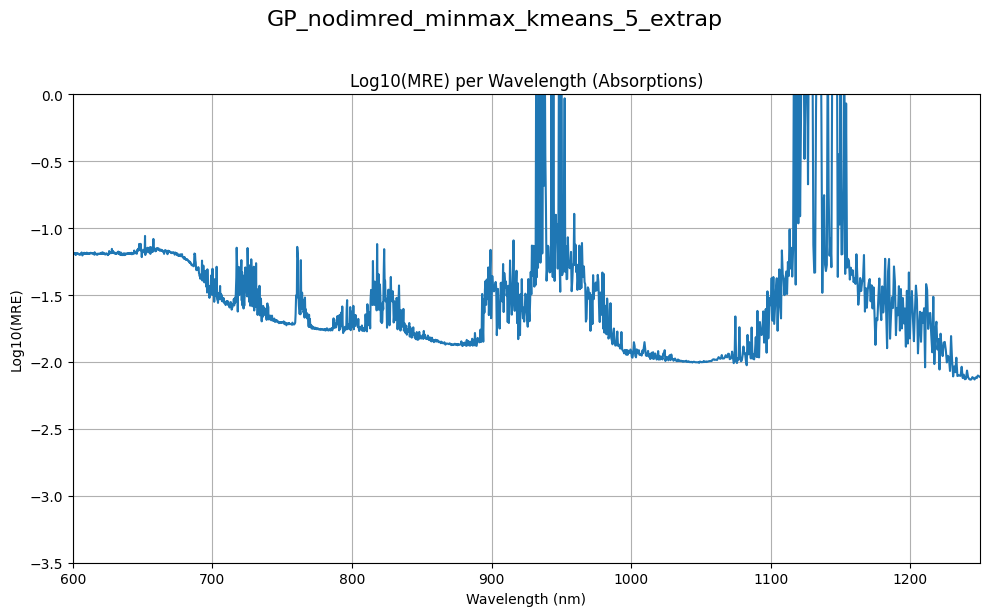

Testing MAE: 0.008659885968620423


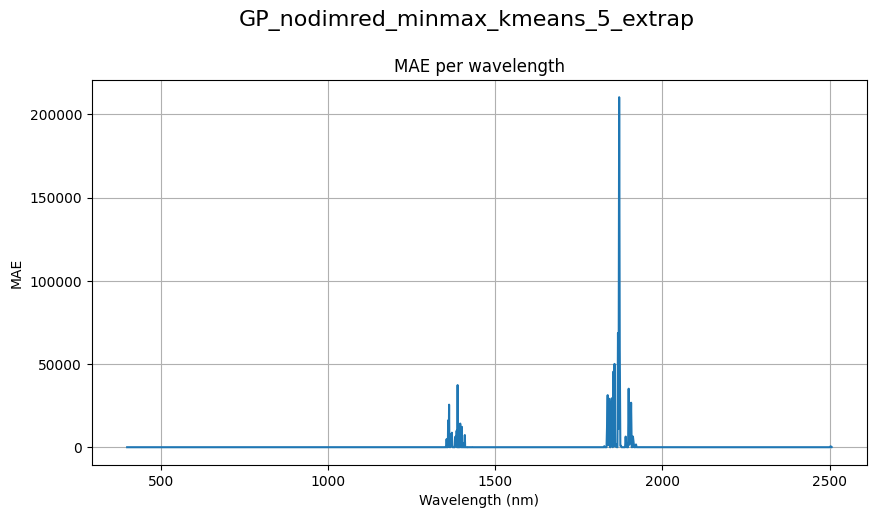

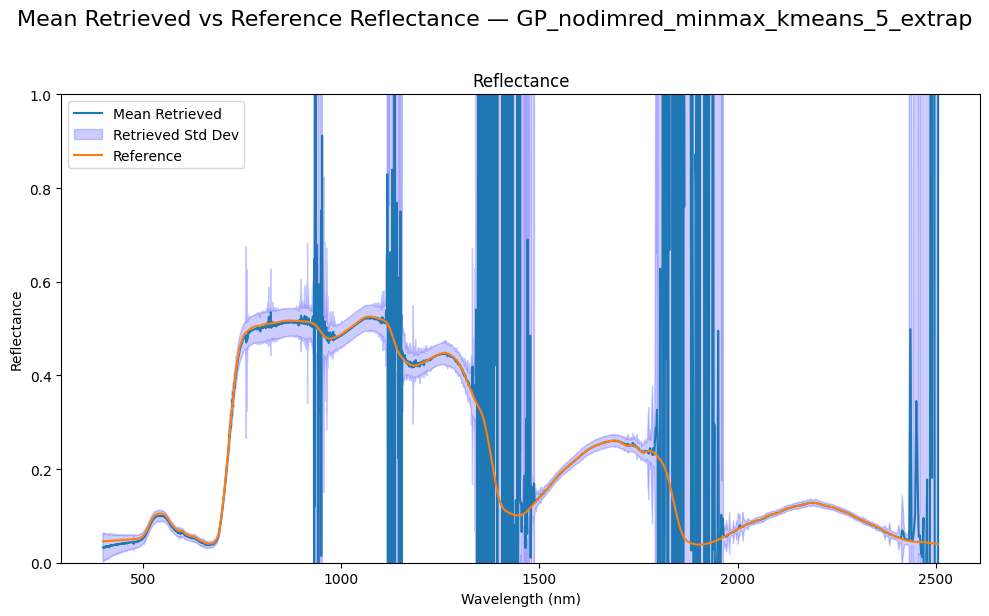

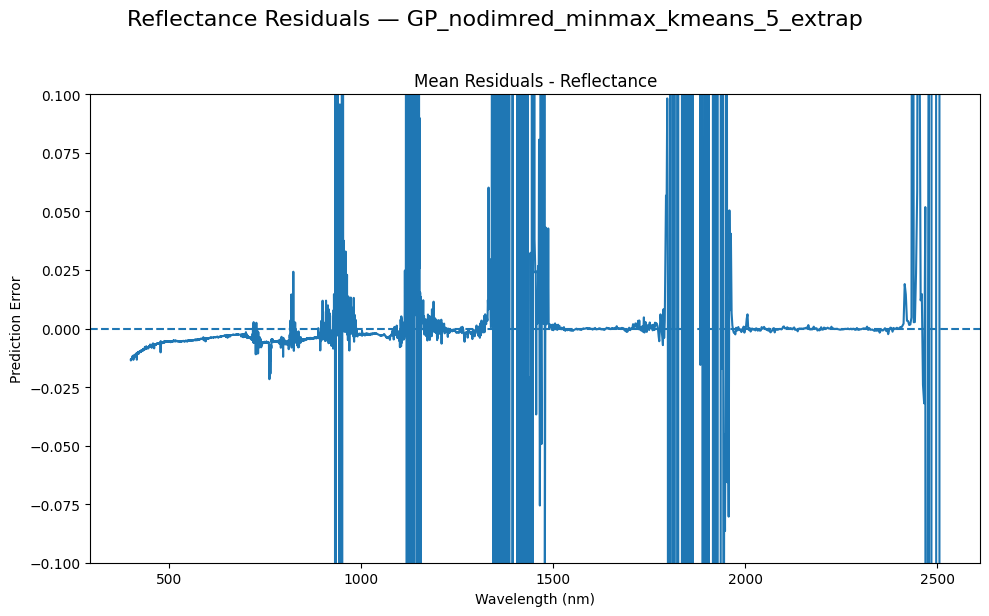

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.1139314150883955


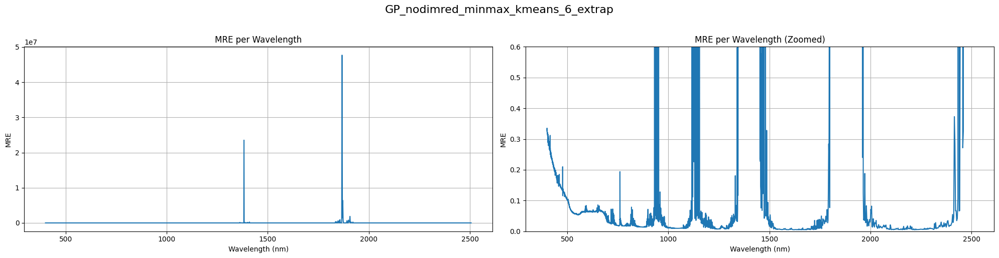

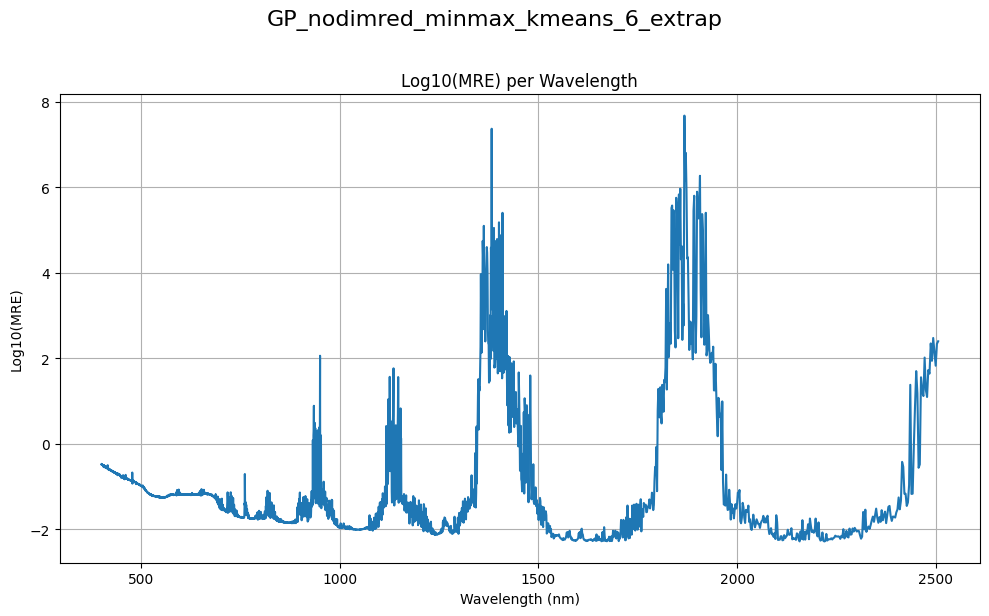

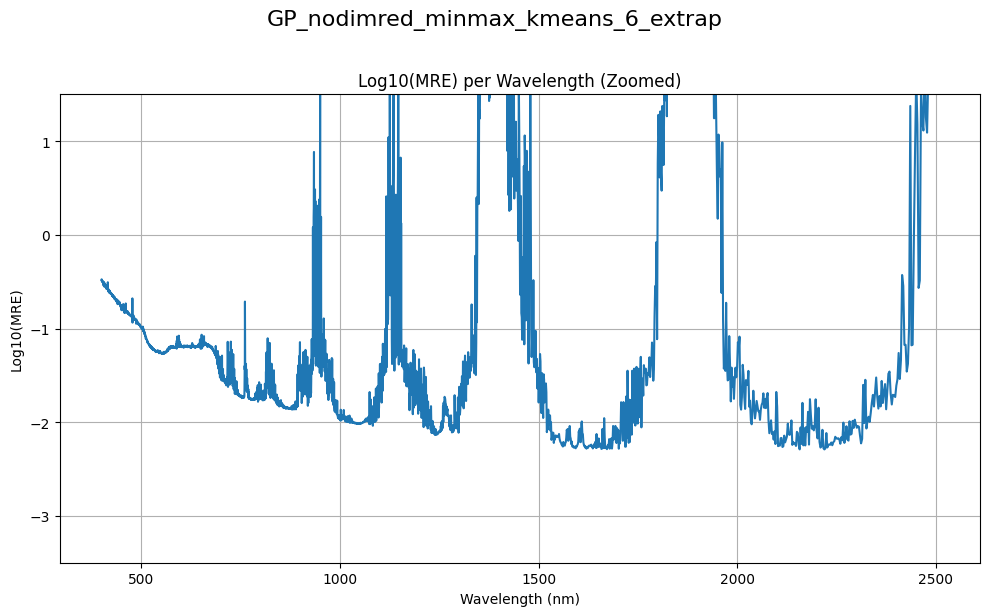

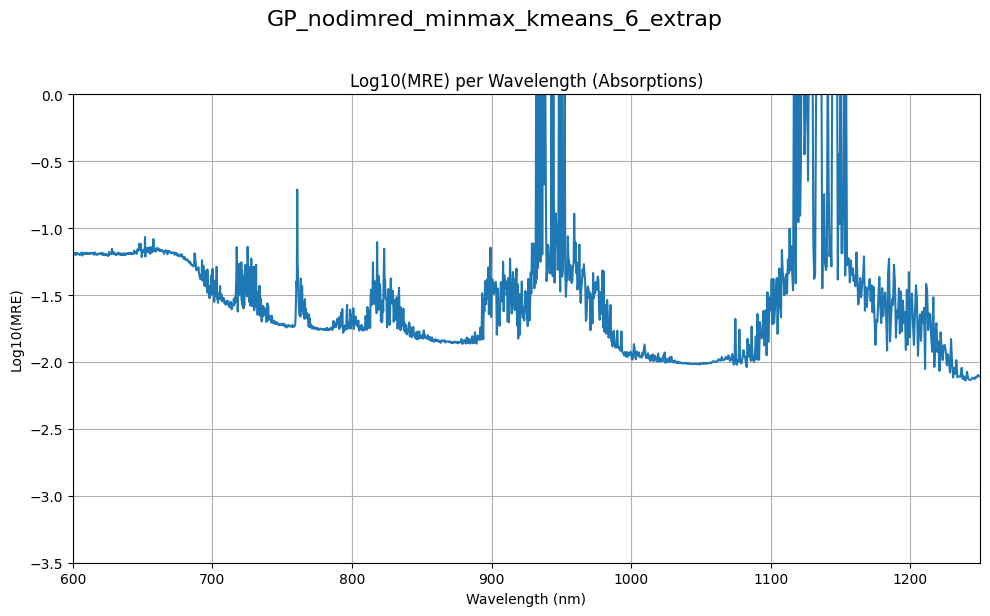

Testing MAE: 0.023476308329097337


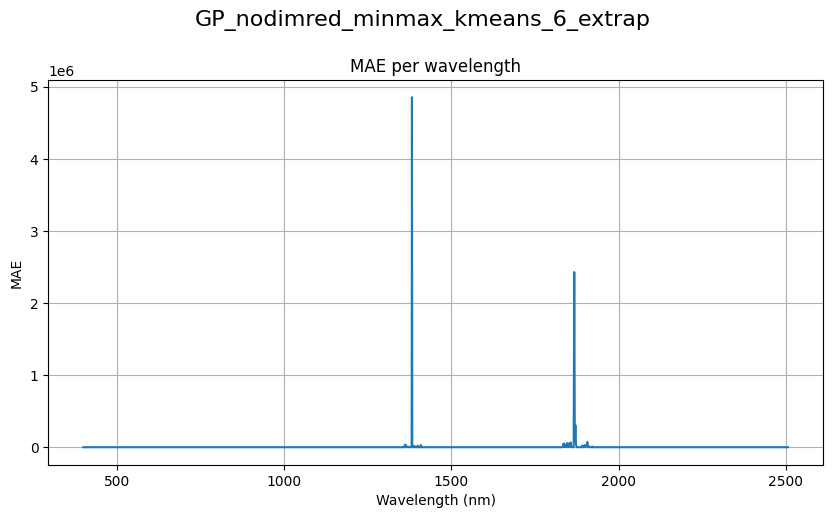

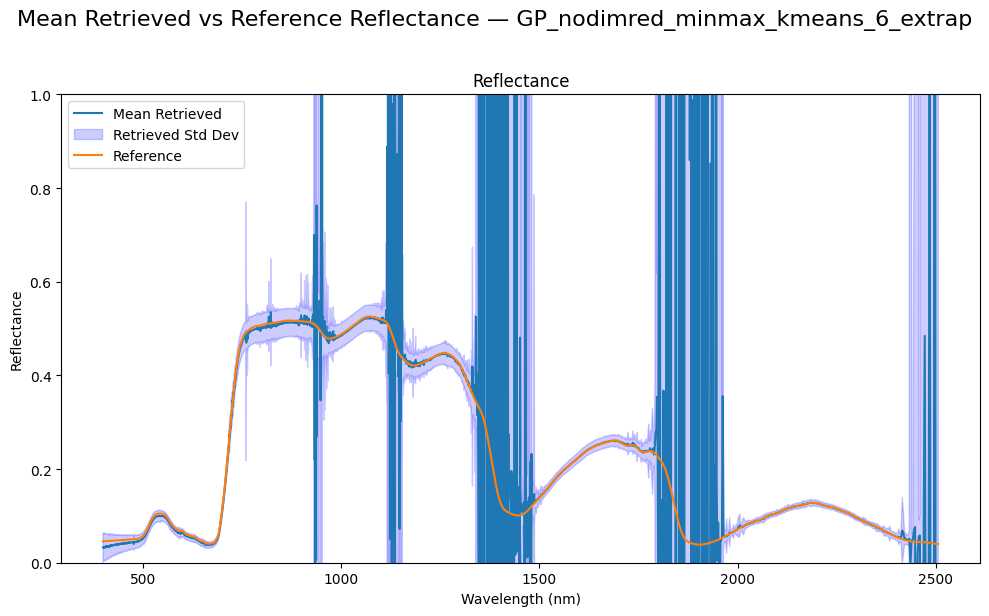

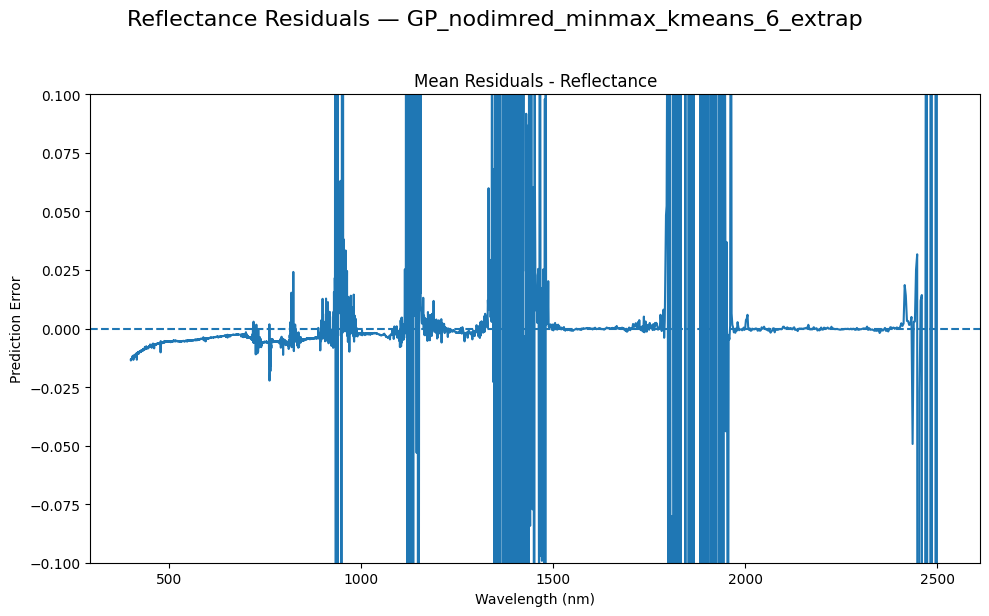

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08344074717860282


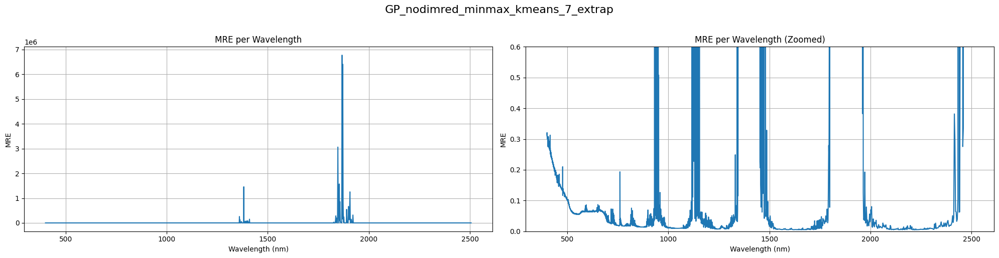

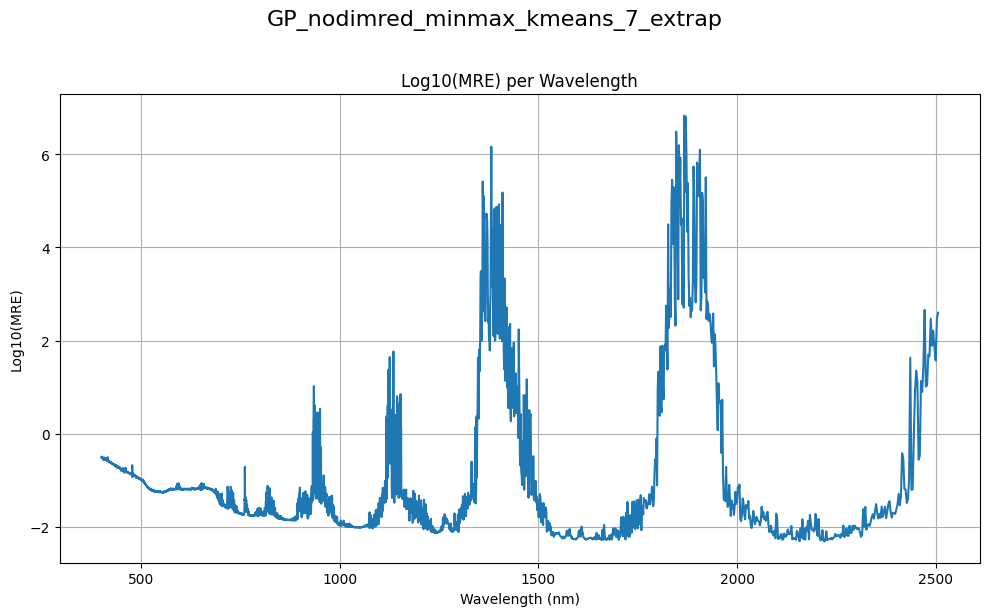

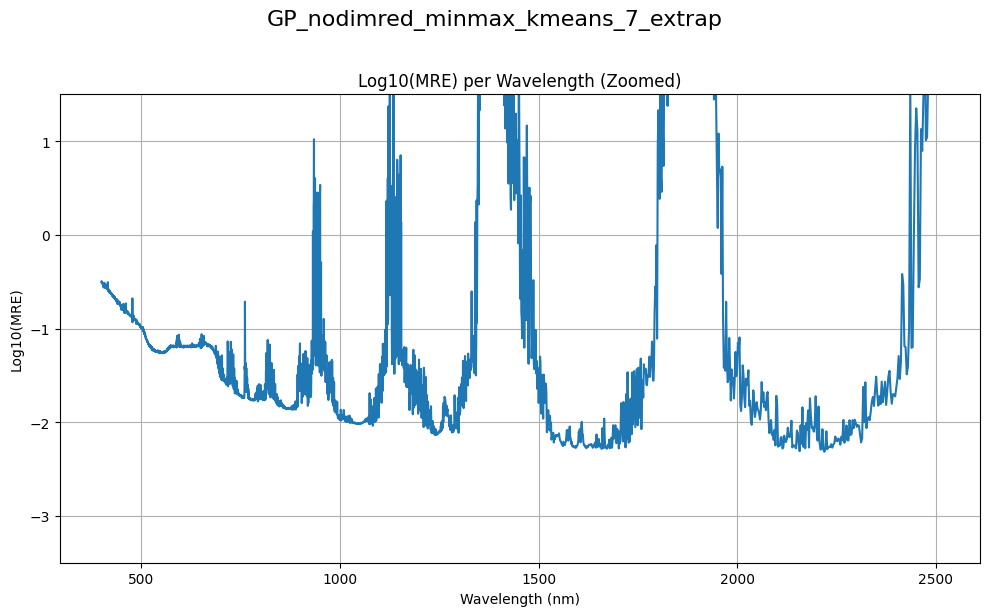

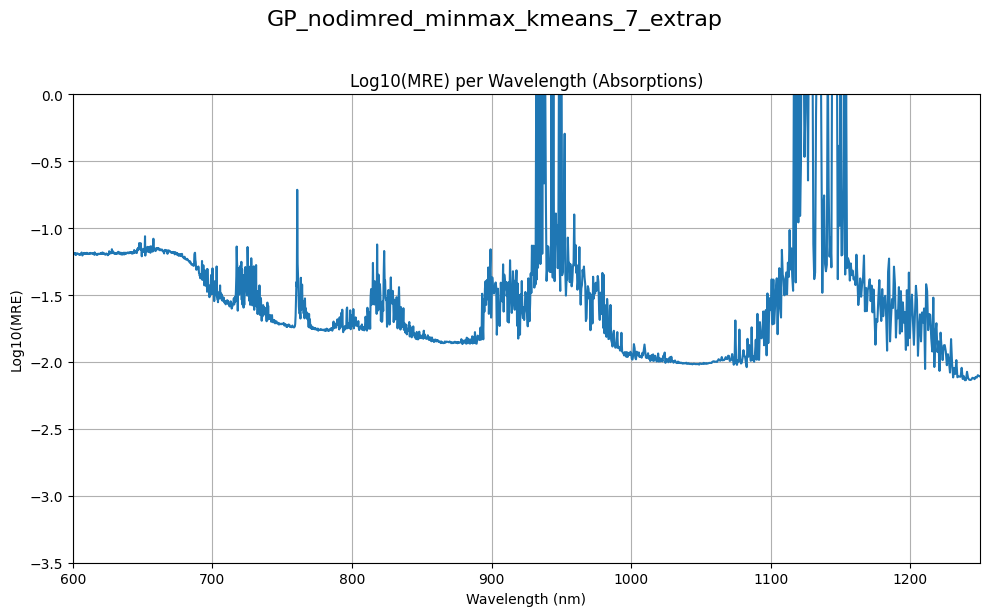

Testing MAE: 0.008548238665335958


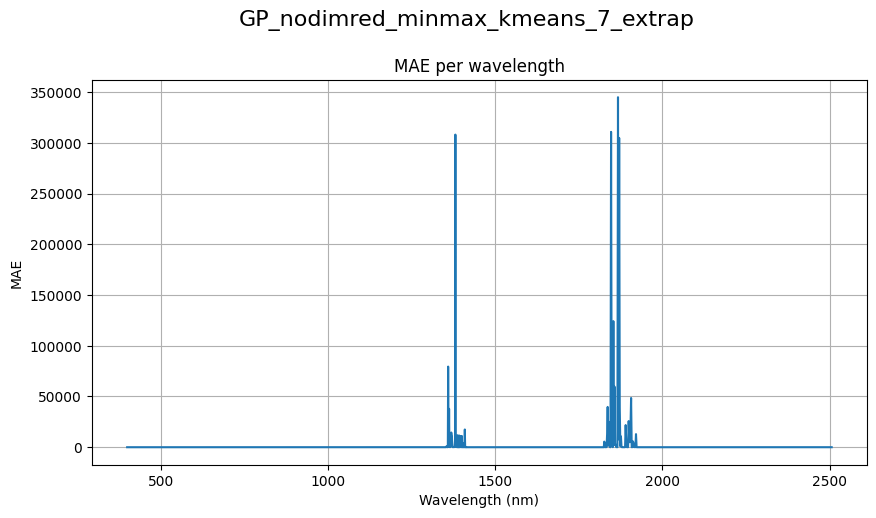

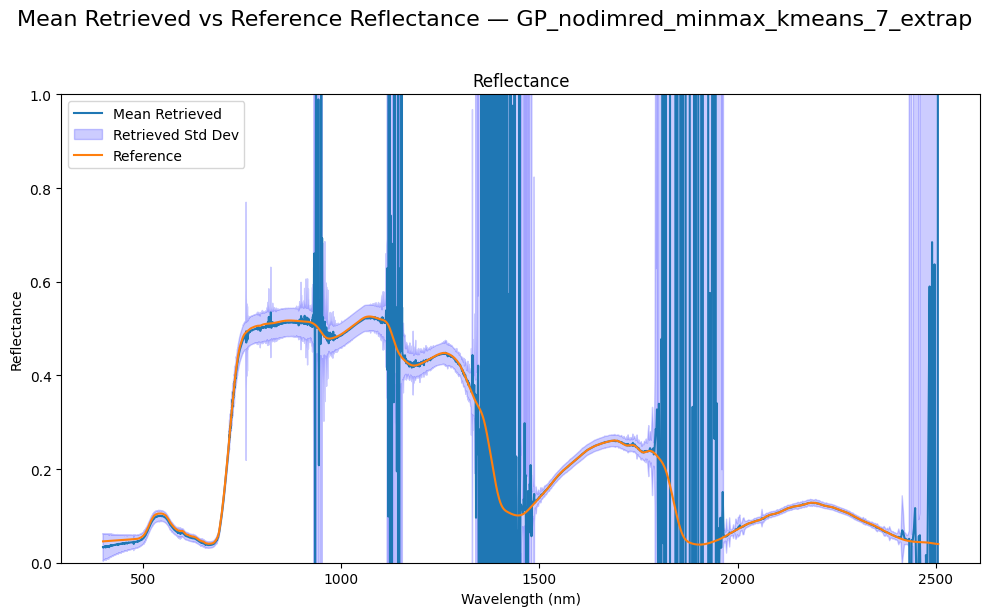

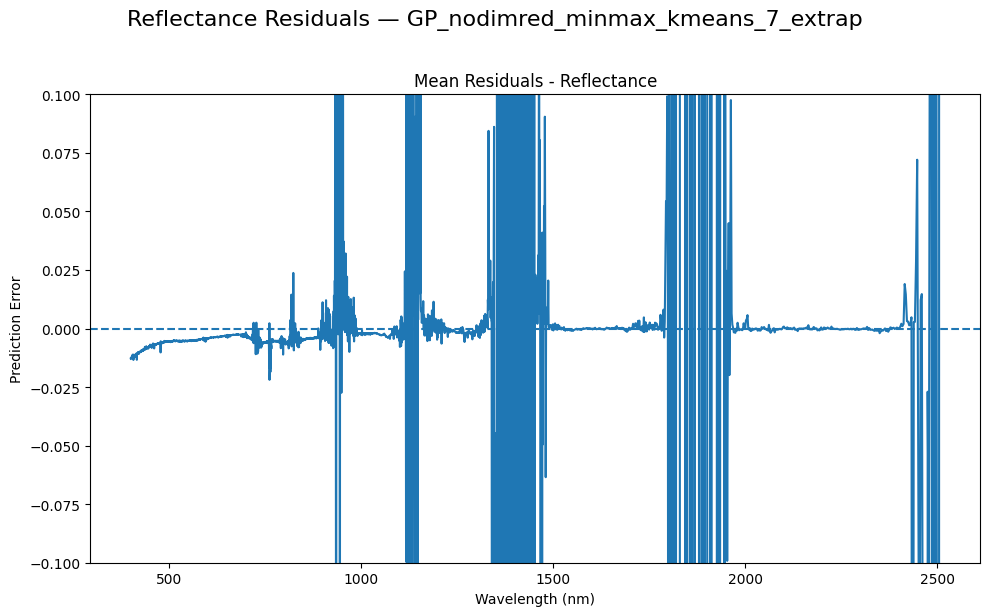

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08349512458717852


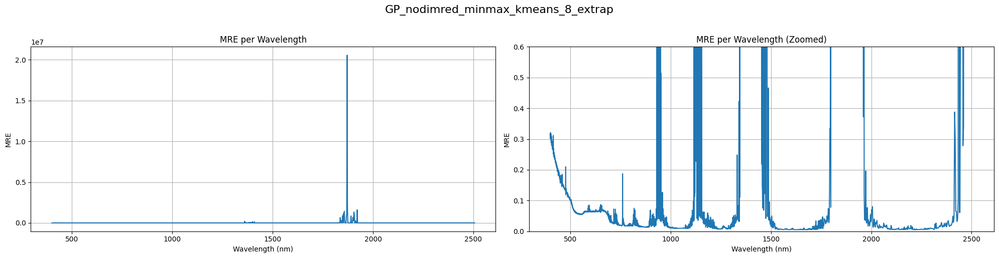

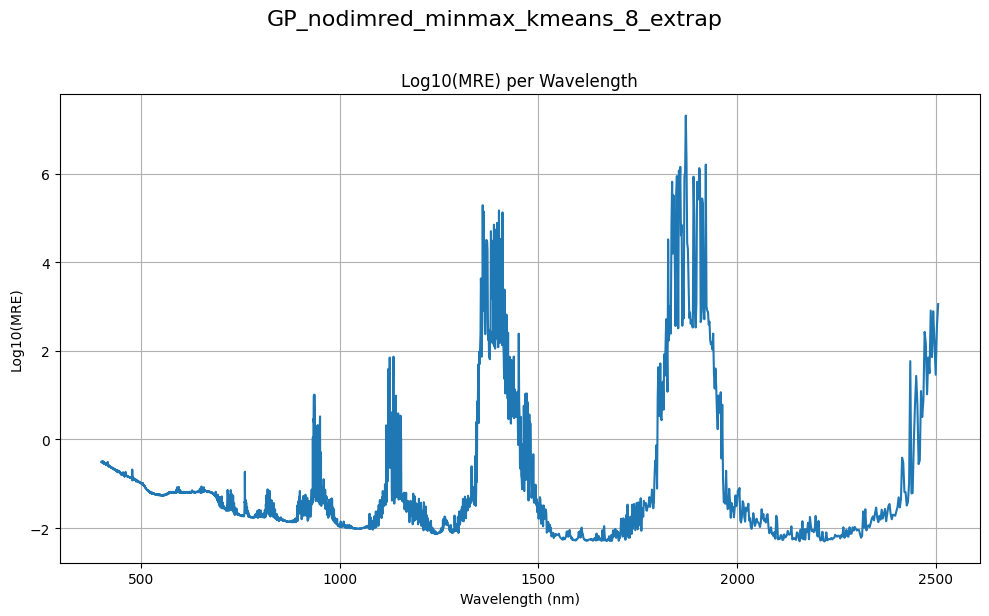

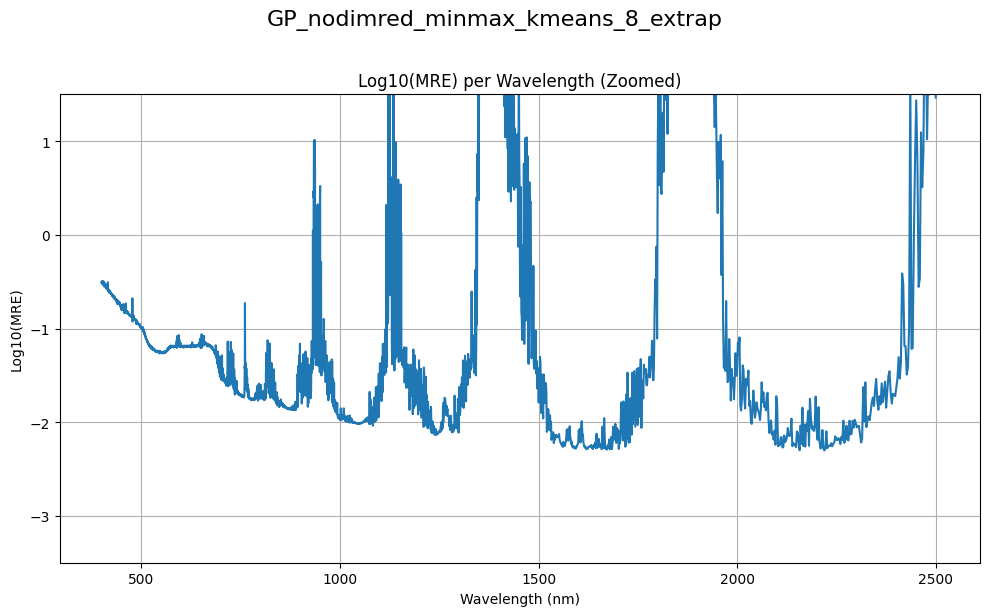

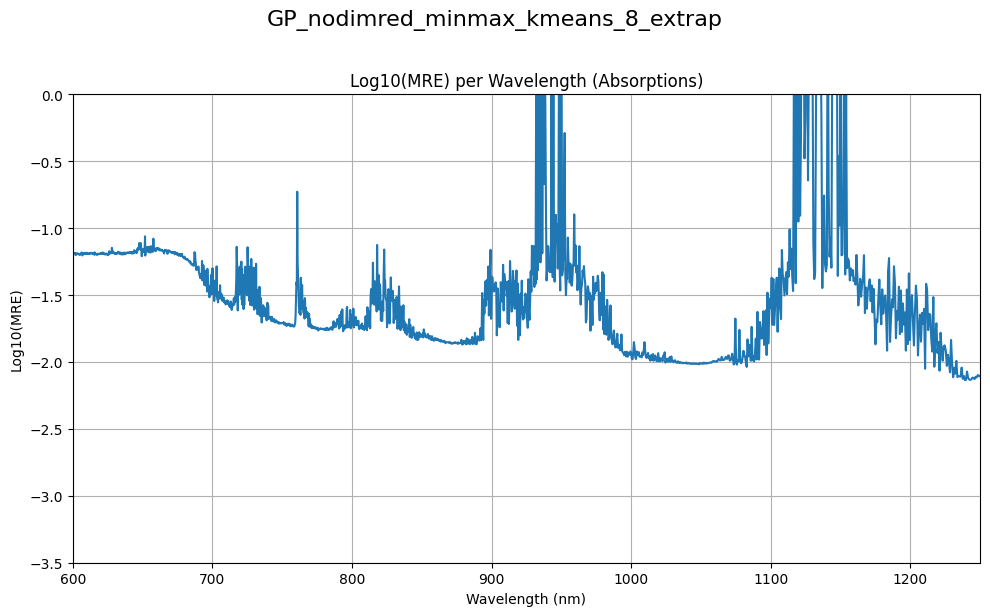

Testing MAE: 0.008517357335040615


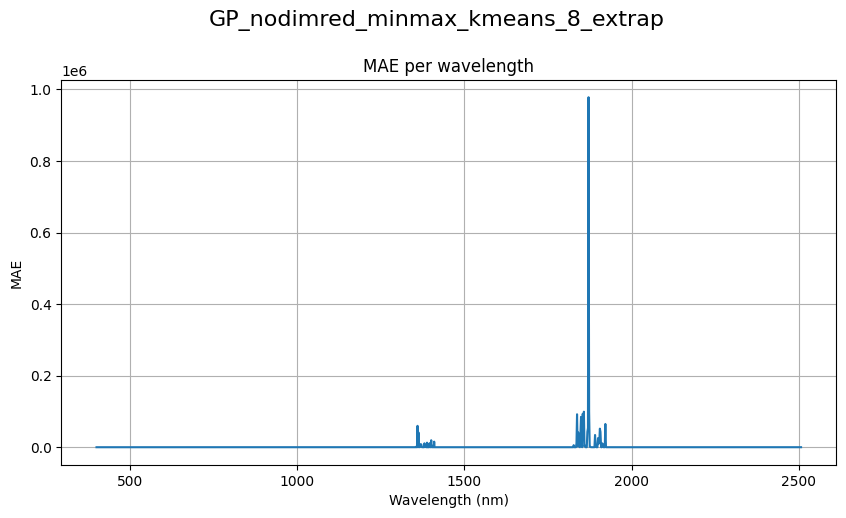

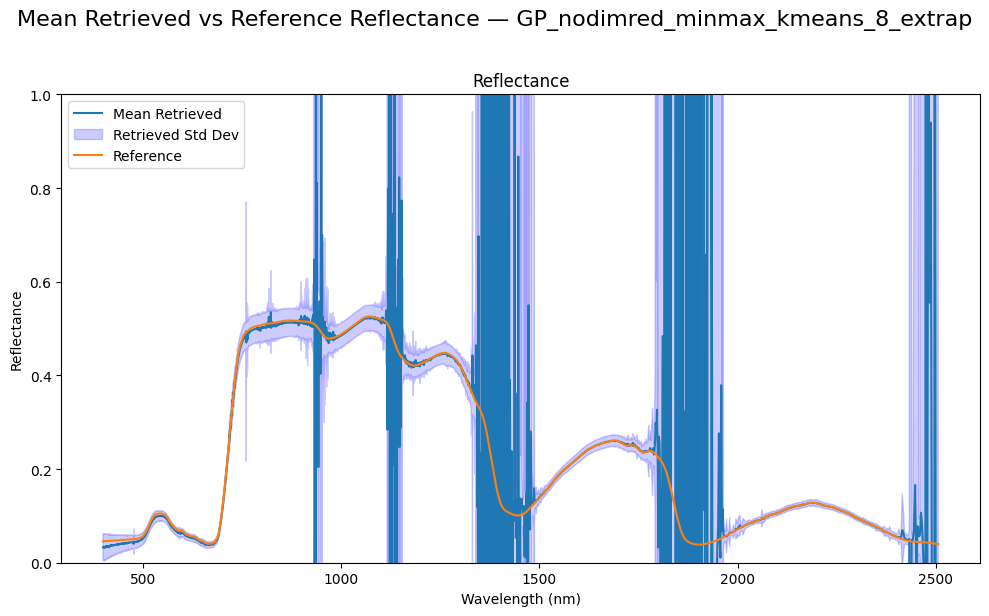

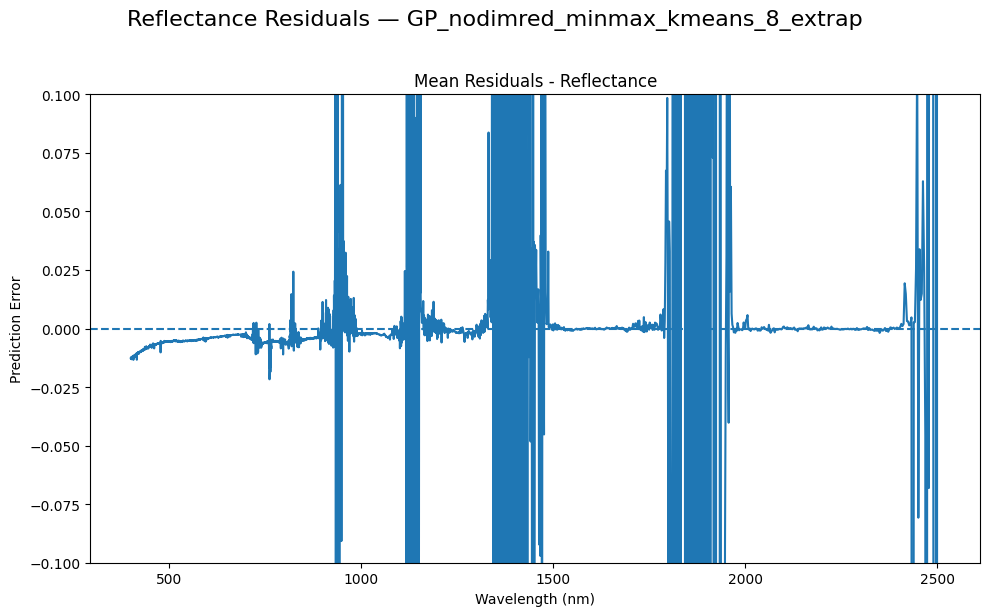

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08366727105538094


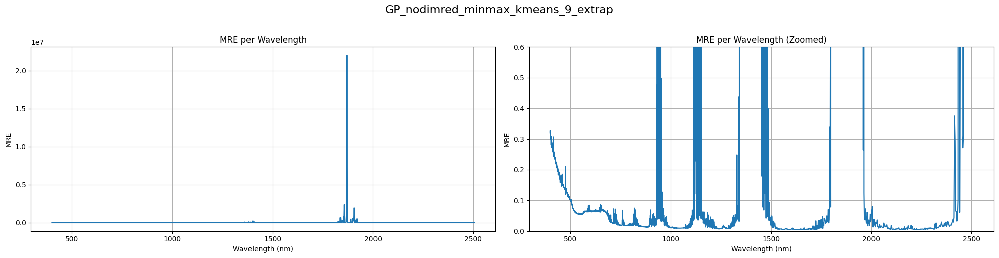

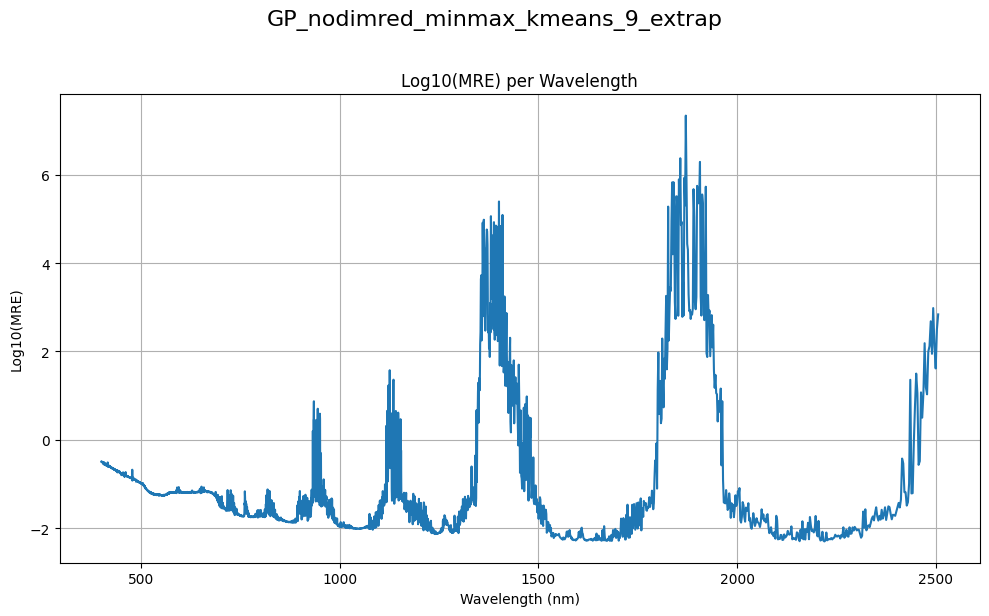

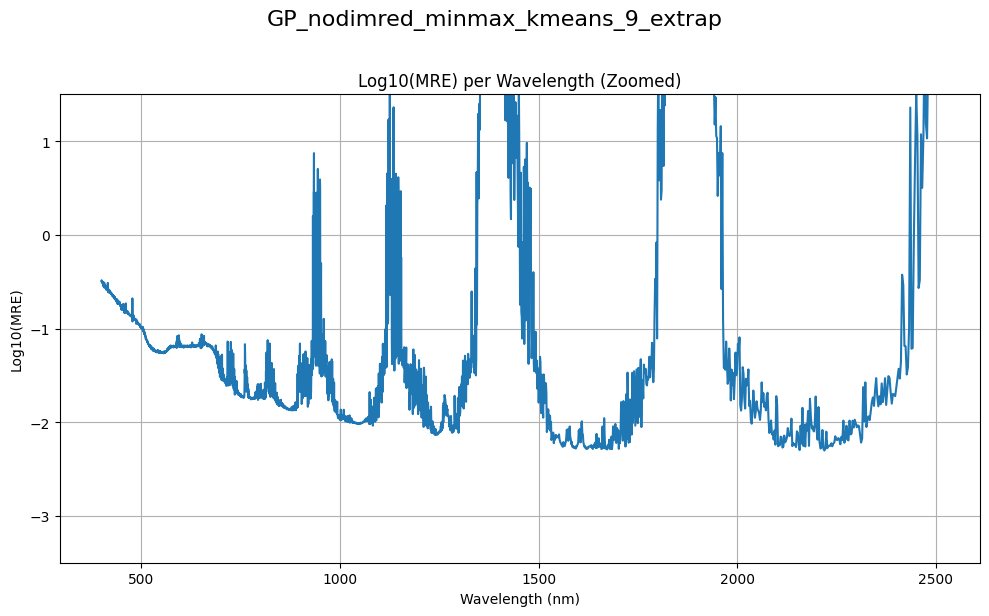

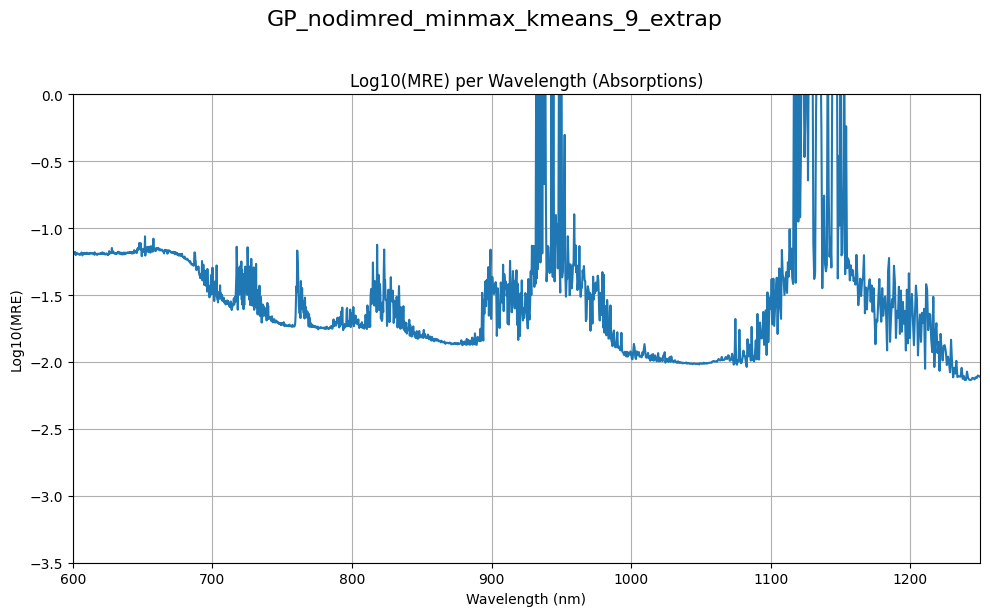

Testing MAE: 0.00866324339199822


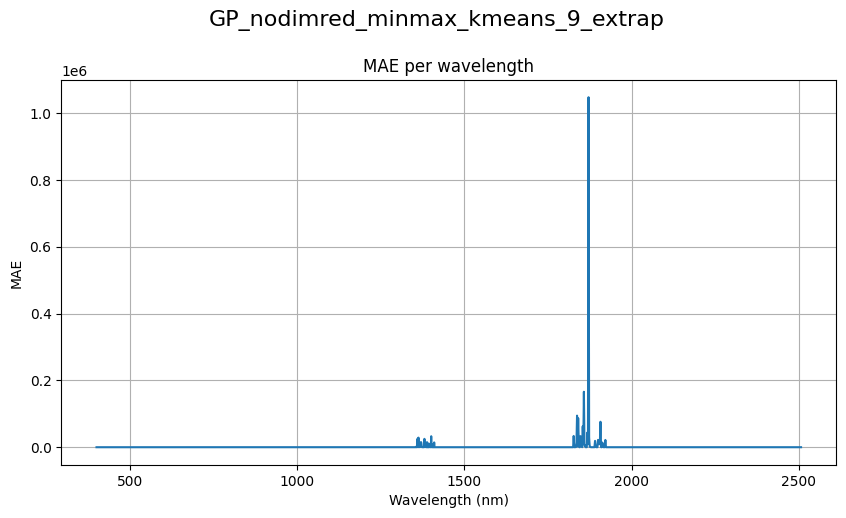

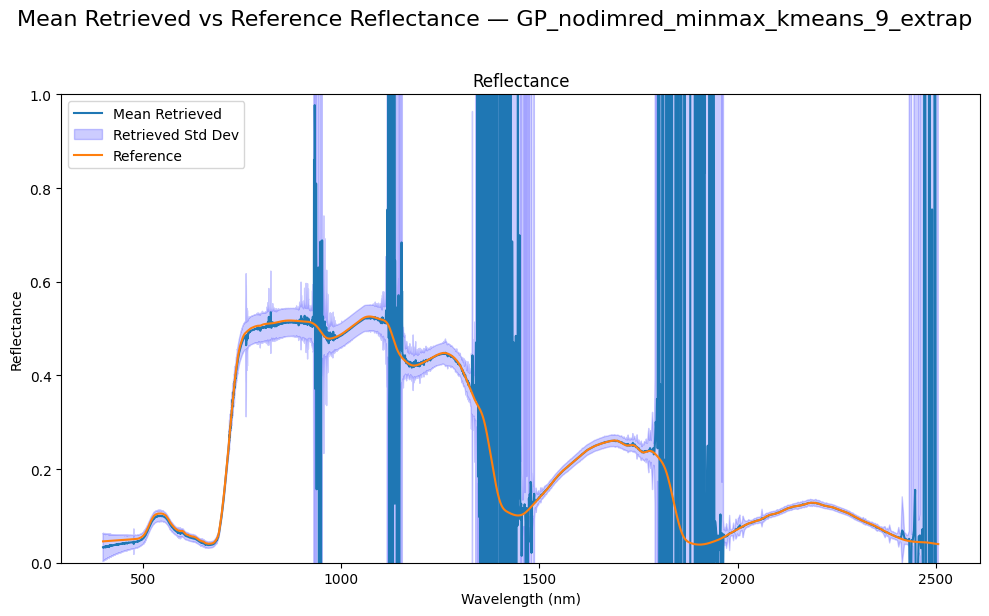

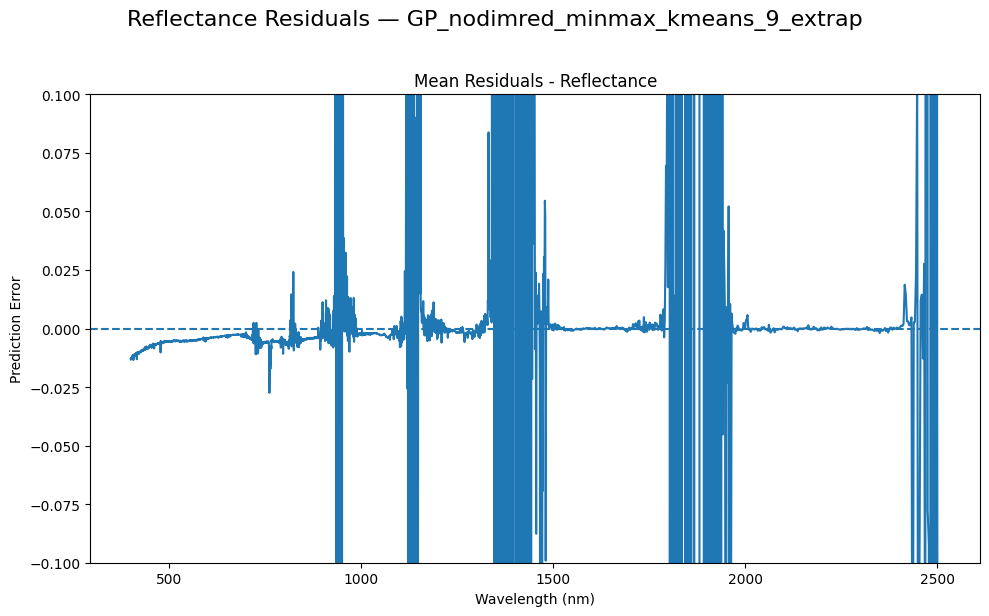

---PREDICTING WITH WINDOWED METHOD---
Testing MRE: 0.08602922894507634


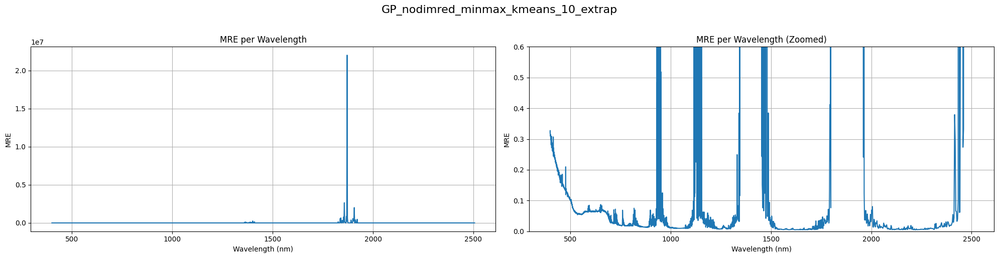

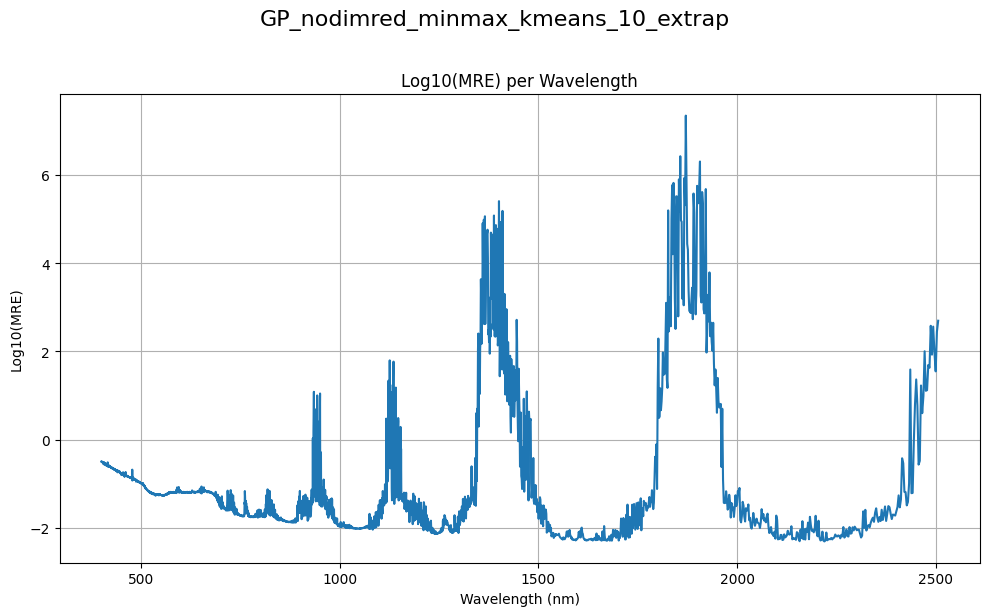

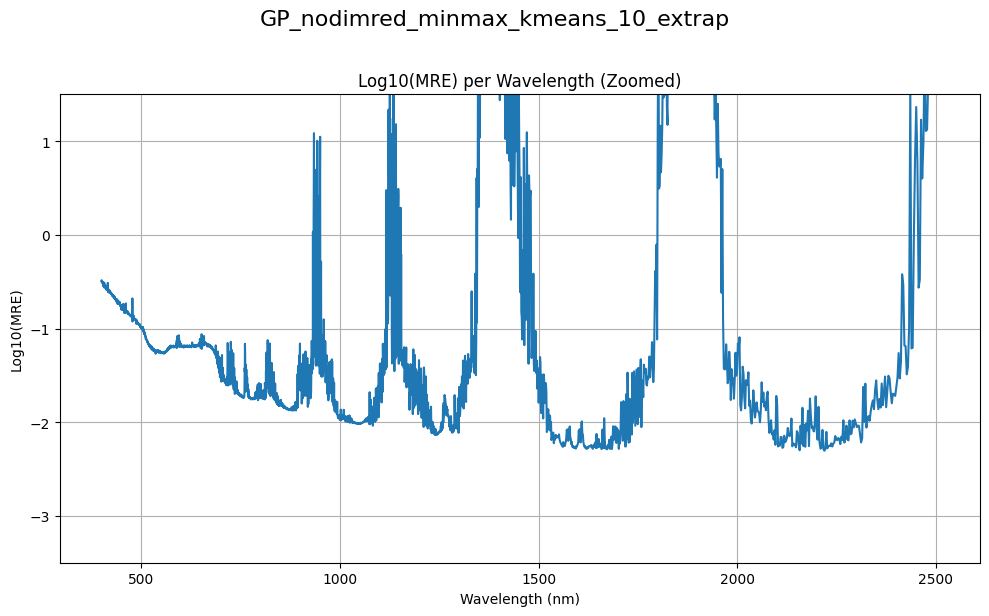

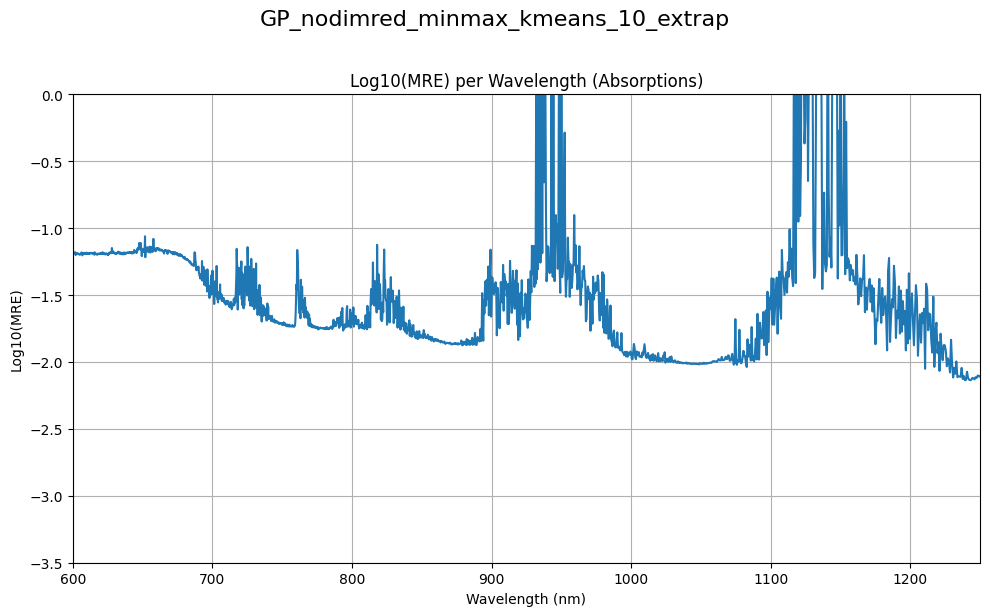

Testing MAE: 0.009831403855355761


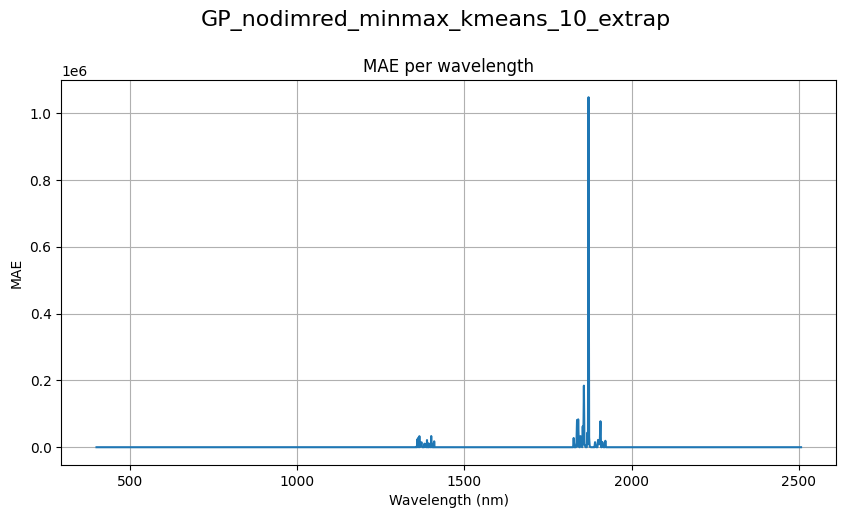

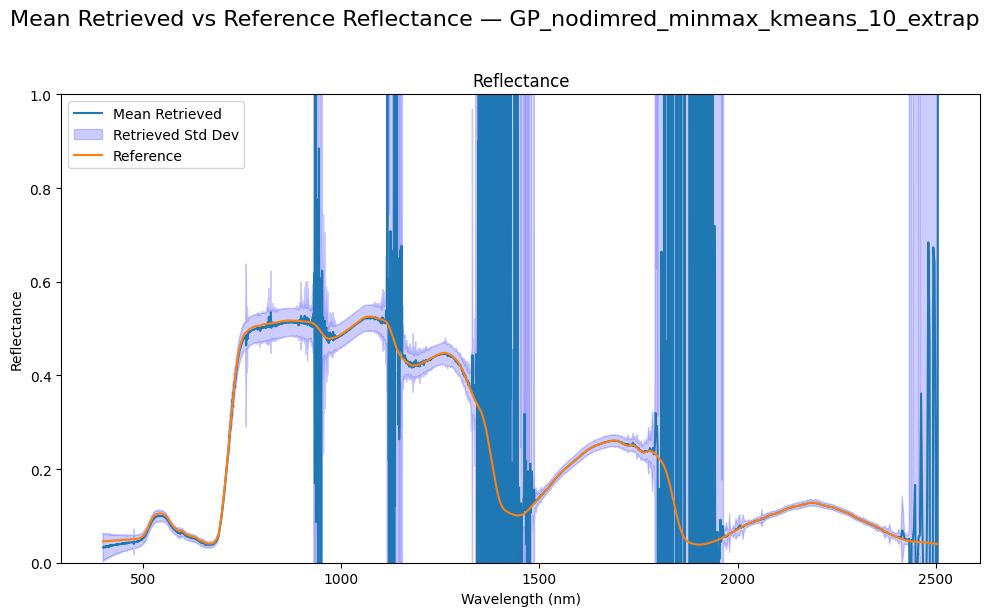

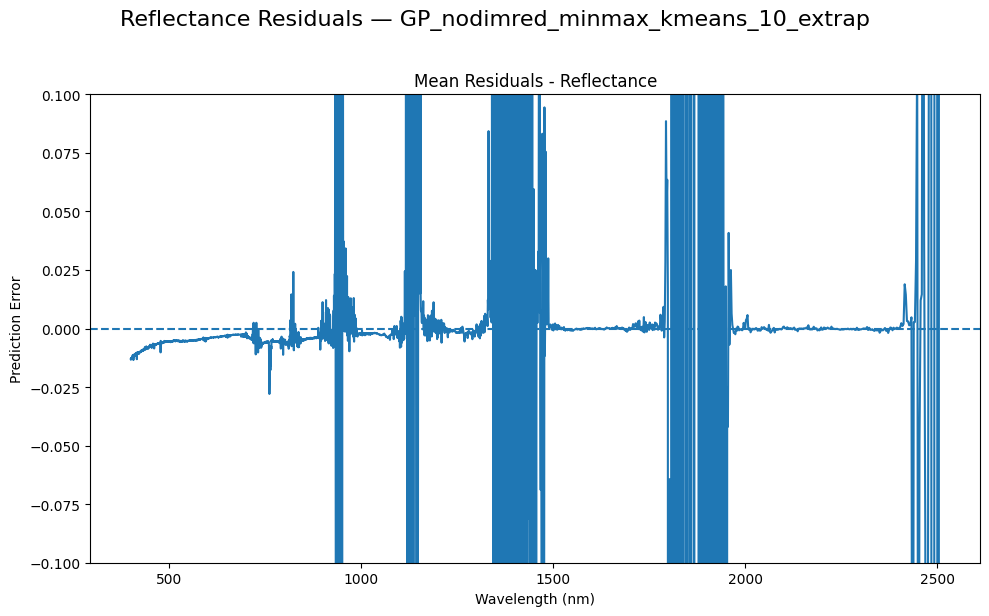

In [15]:
K_CLUSTERS = 10
for k in range(K_CLUSTERS):

    with open(globals.gp_input_path(f"gp_saves/nodimred_resources/gpr_list_nodimred_windows_{k+1}.pkl"), "rb") as f:
        windows_per_function = pickle.load(f)

    Y_test_pred, Y_test_std, elapsed = predict_windowed_shared_kernel(gpr_list, X_test_amlec_scaled, X_tr_scaled, Y_tr_scaled, windows_per_function, y_scalers, len(wavelengths), verbose=False)

    Y_pred_flat = Y_test_pred.reshape(Y_test_pred.shape[0], -1)

    rho_ret = utils.retrieve_reflectance(Y_test_amlec_extrap, Y_pred=Y_pred_flat, sza=sza, n_wvl=len(wavelengths))

    exp_id = f"GP_nodimred_{scale_type}_kmeans_{k+1}"
    full_id = f"GP_nodimred_{scale_type}_kmeans_{k+1}_{dataset_name}"
    test_mre, _ = utils.show_test_results_mre(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))
    test_mae, _ = utils.show_test_results_mae(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))

    Y_std_flat = Y_test_std.reshape(Y_test_std.shape[0], -1)  # (n_samples, 6*n_wvl)
    rho_std = utils.propagate_reflectance_uncertainty(Ltoa=Y_test_amlec_extrap, Y_pred=Y_pred_flat, Y_std=Y_std_flat, sza=sza, n_wvl=len(wavelengths))
    lower = rho_ret - 2 * rho_std
    upper = rho_ret + 2 * rho_std
    is_inside = (rho_ref_resampled >= lower) & (rho_ref_resampled <= upper)
    global_coverage = np.mean(is_inside) * 100

    utils.show_predicted_vs_true_reflectance(rho_ref_resampled, rho_ret, rho_std, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))
    utils.show_residuals_reflectance(rho_ref_resampled, rho_ret, wavelengths, exp_id=full_id, save_path=globals.gp_output_path(f"gp_saves/amlec_testing_results/nodimred/"))

    entry = {
        "experiment_id": exp_id,
        "gp_kernel_full_name": "nodimred_windowed_median",
        "model": "nodimred_windowed_median",
        "scale_type": "minmax",
        "dataset_size": "500",
        "inference_time": elapsed,
        "test_mre": test_mre,
        "test_mae": test_mae,
        "global_cov": global_coverage
    }

    results_df = pd.DataFrame([entry])
    results_df.to_csv(globals.gp_output_path(f"./gp_saves/amlec_testing_results/{dataset_name}_gp_test_results.csv"), mode="a", header=not Path(globals.gp_output_path(f"./gp_saves/amlec_testing_results/{dataset_name}_gp_test_results.csv")).exists(), index=False)

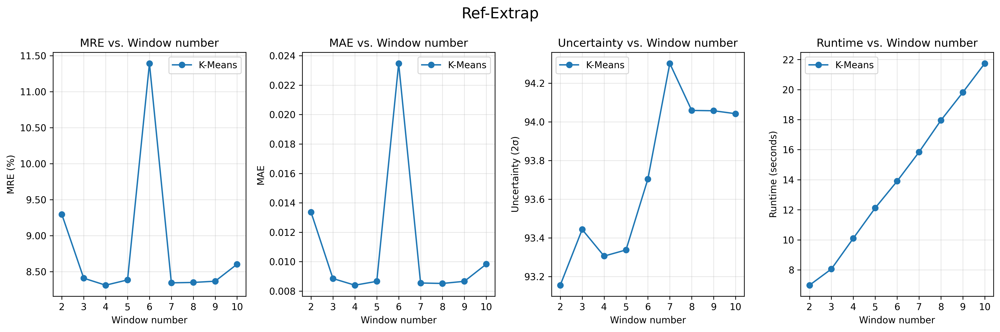

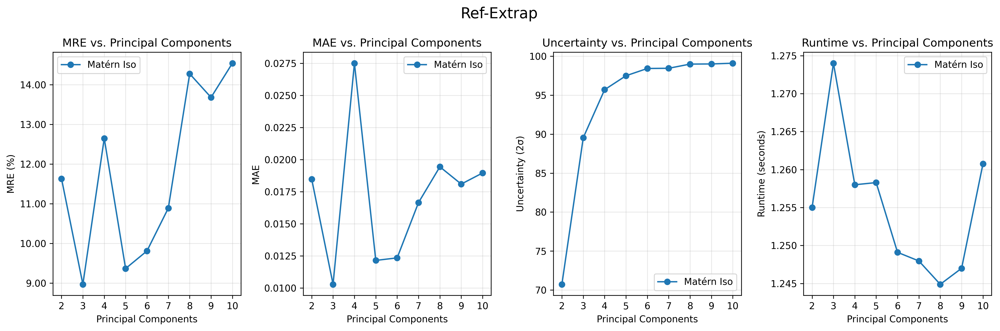

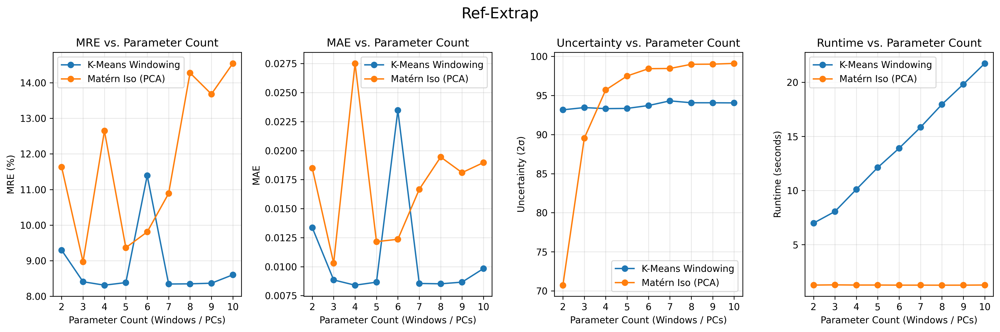

In [22]:
dataset_name_plots = "Ref-Extrap"
results_df = pd.read_csv(globals.gp_input_path("./gp_saves/amlec_testing_results/extrap_gp_test_results.csv"))
kmeans_df = extract_experiment_data(results_df, r"GP_nodimred_minmax_kmeans_((?:[2-9]|10))$", "window")
matern_df = extract_experiment_data(results_df, r"Matern_iso_minmax_500_((?:[2-9]|10))$", "PCs")

plot_combined_metrics([{"df": kmeans_df, "x_col": "window", "label": "K-Means"}], "Window number", dataset_name=dataset_name_plots)
plot_combined_metrics([{"df": matern_df, "x_col": "PCs", "label": "Matérn Iso"}], "Principal Components", dataset_name=dataset_name_plots)
plot_combined_metrics(
    [
        {"df": kmeans_df, "x_col": "window", "label": "K-Means Windowing"},
        {"df": matern_df, "x_col": "PCs", "label": "Matérn Iso (PCA)"},
    ],
    "Parameter Count",
    dataset_name=dataset_name_plots
)